# 30_03 — Convergencia de las cadenas MCMC · Metro Interstate (I-94) horario · volumen de tráfico · **barrido en $M$**

Paso **3a** del ciclo. Este notebook **sólo diagnostica las cadenas**: no
predice, no evalúa y no toca el bloque de prueba. Si algo aquí falla, los
números de `30_04` no significan nada, y por eso son notebooks separados.

Los cálculos viven en `fit/convergencia_barrido.py` y las figuras en
`graphics/viz_convergencia.py`; este notebook los orquesta.

Covariables cruzadas con un solo rezago ($p=M$): el diseño cambia con $M$, así que MATLAB entrena **cada** $M$ y `hyperparameters.json["trazas_en"]` apunta al propio punto. Datos reales: no hay generador contra el cual contrastar la selección (§6).

| Estadístico | Referencia | Lectura |
|---|---|---|
| ESS | Geyer (1992) | $\gtrsim 400$ ideal, $>100$ aceptable |
| Geweke $z$ | test $z$ entre segmentos | $\lvert z\rvert < 2$ ⇒ no se rechaza |
| $\hat R$ | Gelman-Rubin | $< 1.1$ ⇒ convergencia |

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, diagnosticar_punto, imprimir_convergencia,
    ocupacion_mezcla, diagnostico_gating, pip_punto,
    verificar_muestreador_predictor, diagnostico_paso_gamma,
    tabla_barrido, ocupacion_barrido, pip_barrido, veredicto_barrido,
)
from model_psbp_fd.graphics import (
    plot_global_components, plot_active_clusters,
    plot_convergence_bj, plot_convergence_pj,
    plot_ocupacion_mezcla, plot_gating, plot_diagnostico_vs_M,
    plot_ocupacion_vs_M, plot_pip_vs_M,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 30_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "trafico_mi", 1   # ventana 1: 2015-07-01 .. 2018-09-30, 70/30 (30_01 §1.1)
M_FPCA_LIST = (1, 2, 3, 4, 5, 6)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None

# Propias de la convergencia.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
BURN_EVAL           = None    # iteraciones descartadas; None = el burn del .mat
SD_PIP_MAX          = 0.15    # dispersión entre cadenas que se avisa
CORR_MIN_CONTRATO   = 0.999   # corr(inEout, predict) mínima, §7

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
# Salidas que CRUZAN los M: directorio hermano de los de cada punto.
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 80-83)")


EXPERIMENT_BASE : real_trafico_mi_v01
barrido en M    : [1, 2, 3, 4, 5, 6]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_barrido_M   (archivos 80-83)


In [3]:
# EST[M] es el estado completo de cada punto; todo lo que sigue lo consume por índice.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST, PROJECT_ROOT,
                                  dominio=DOMINIO)

  M  comp  cadenas  covariables  seed_base
  1     1        1            1  41232
  2     2        1            2  41232
  3     3        1            3  41232
  4     4        1            4  41232
  5     5        1            5  41232
  6     6        1            6  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 1)


## 2. Lectura de las trazas

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS, BURN_EVAL)   # los M efectivamente disponibles

OK M=1: 1 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=2: 2 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=3: 3 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=4: 4 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=5: 5 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=6: 6 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente


## 3. Tabla de diagnósticos

ESS, Geweke y $\hat R$ **sin generar figuras**. Una tabla por $M$, guardada en el
directorio de su punto (`40_diagnosticos_mcmc.csv`); la comparación entre $M$ va
en §8.

In [5]:
for M in M_OK:
    diag_df = diagnosticar_punto(EST[M])
    display(diag_df.style
        .format({"ess_min": "{:.1f}", "ess_mean": "{:.1f}",
                 "geweke_max": "{:+.2f}", "rhat": "{:.4f}"})
        .background_gradient(subset=["rhat"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption(f"M={M} - diagnósticos MCMC por componente FPCA y variable"))

imprimir_convergencia(EST, M_OK)

[tabla_diagnosticos] inicio (2 pasos)


  1/2 (50.0%) t=0.0s eta=0.0s  fpc_1 beta_j[fpc_1_lag1] rhat=nan ess_min=1744


  2/2 (100.0%) t=0.0s eta=0.0s  fpc_1 p_j[fpc_1_lag1] rhat=nan ess_min=302


[tabla_diagnosticos] listo: 2 pasos en 0.0s  0 variables sin converger de 2


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\fit\diagnostics_mcmc.py:269: RuntimeWarning: All-NaN axis encountered
  "rhat_max":        float(np.nanmax(tabla["rhat"])),


,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,1,2000,1744.5,1744.5,+0.22,nan,True
1,1,p_j,fpc_1_lag1,1,2000,302.4,302.4,+1.75,nan,True


... (126 outputs left out)

[tabla_diagnosticos] listo: 72 pasos en 0.1s  28 variables sin converger de 72


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\fit\diagnostics_mcmc.py:269: RuntimeWarning: All-NaN axis encountered
  "rhat_max":        float(np.nanmax(tabla["rhat"])),


,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,1,2000,1439.2,1439.2,+1.01,nan,True
1,1,beta_j,fpc_2_lag1,1,2000,2000.0,2000.0,+0.11,nan,True
2,1,beta_j,fpc_3_lag1,1,2000,1761.9,1761.9,+1.83,nan,True
3,1,beta_j,fpc_4_lag1,1,2000,1964.6,1964.6,+1.70,nan,True
4,1,beta_j,fpc_5_lag1,1,2000,1547.5,1547.5,+2.03,nan,False
5,1,beta_j,fpc_6_lag1,1,2000,2000.0,2000.0,+0.84,nan,True
6,1,p_j,fpc_1_lag1,1,2000,293.8,293.8,+0.44,nan,True
7,1,p_j,fpc_2_lag1,1,2000,111.2,111.2,+1.33,nan,True
8,1,p_j,fpc_3_lag1,1,2000,22.2,22.2,+6.76,nan,False
9,1,p_j,fpc_4_lag1,1,2000,31.2,31.2,+2.91,nan,False


  M = 1   (real_trafico_mi_v01_m01)
  Rhat max nan (umbral 1.1)  ·  ESS min 302.4 (umbral 100.0)  ·  |Geweke| max 1.75 (umbral 2.0)
  variables sin converger: 0 de 2   VEREDICTO: OK todas convergen
  M = 2   (real_trafico_mi_v01_m02)
  Rhat max nan (umbral 1.1)  ·  ESS min 32.1 (umbral 100.0)  ·  |Geweke| max 4.00 (umbral 2.0)
  variables sin converger: 3 de 8   VEREDICTO: X REVISAR
    · FPC 1 p_j fpc_1_lag1: Rhat=nan ESS=55 G=+4.00
    · FPC 1 p_j fpc_2_lag1: Rhat=nan ESS=287 G=+2.20
    · FPC 2 p_j fpc_2_lag1: Rhat=nan ESS=32 G=+0.11
  M = 3   (real_trafico_mi_v01_m03)
  Rhat max nan (umbral 1.1)  ·  ESS min 51.5 (umbral 100.0)  ·  |Geweke| max 4.61 (umbral 2.0)
  variables sin converger: 9 de 18   VEREDICTO: X REVISAR
    · FPC 1 p_j fpc_1_lag1: Rhat=nan ESS=87 G=+0.46
    · FPC 1 p_j fpc_2_lag1: Rhat=nan ESS=115 G=+3.06
    · FPC 1 p_j fpc_3_lag1: Rhat=nan ESS=54 G=+4.61
    · FPC 2 beta_j fpc_3_lag1: Rhat=nan ESS=99 G=+1.79
    · FPC 2 p_j fpc_1_lag1: Rhat=nan ESS=155 G=+2.53
   

## 4. Ocupación de la mezcla

`N1out` es $\max_i S_i$: cuántos átomos están efectivamente ocupados en cada
iteración. Decide si el truncamiento en $N$ átomos es suficiente y suele ser
**lo último en mezclar**, de modo que conviene mirarlo antes de fijar el `burn`.
Si la traza se pega contra $N$, el truncamiento está mordiendo y hay que subirlo.

OK [M=1] ninguna cadena alcanza N=30: el truncamiento no restringe.


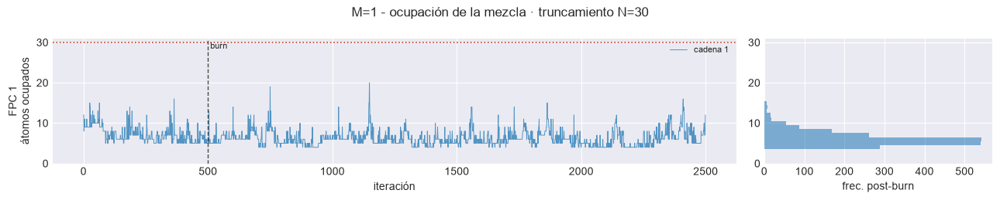

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,1,1,1,6.17,20,13.0,30,False,0.00%


! [M=2] alguna cadena alcanza N: subir mcmc_config['N'].


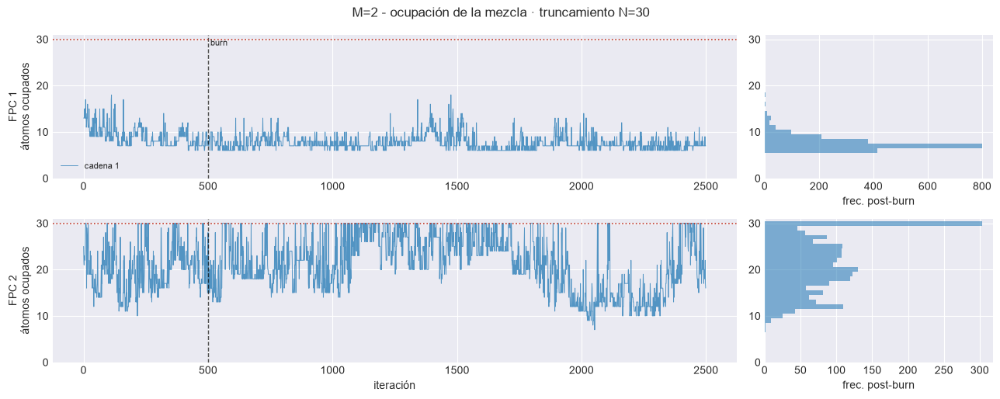

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,2,1,1,7.60,18,13.0,30,False,0.00%
1,2,2,1,21.36,30,30.0,30,True,15.15%


! [M=3] alguna cadena alcanza N: subir mcmc_config['N'].


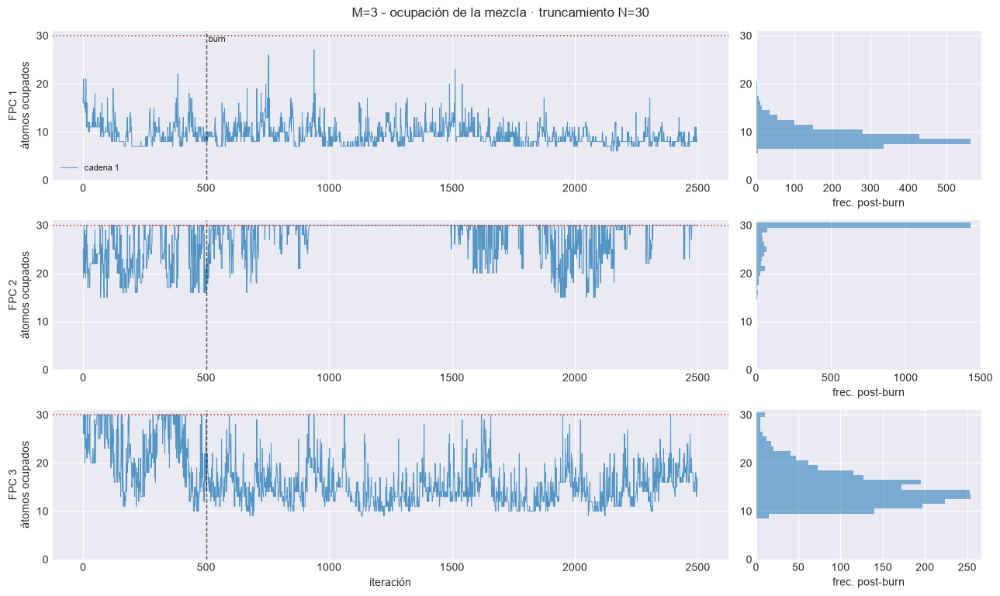

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,3,1,1,9.20,27,16.0,30,False,0.00%
1,3,2,1,28.30,30,30.0,30,True,71.70%
2,3,3,1,14.93,30,28.0,30,True,0.55%


! [M=4] alguna cadena alcanza N: subir mcmc_config['N'].


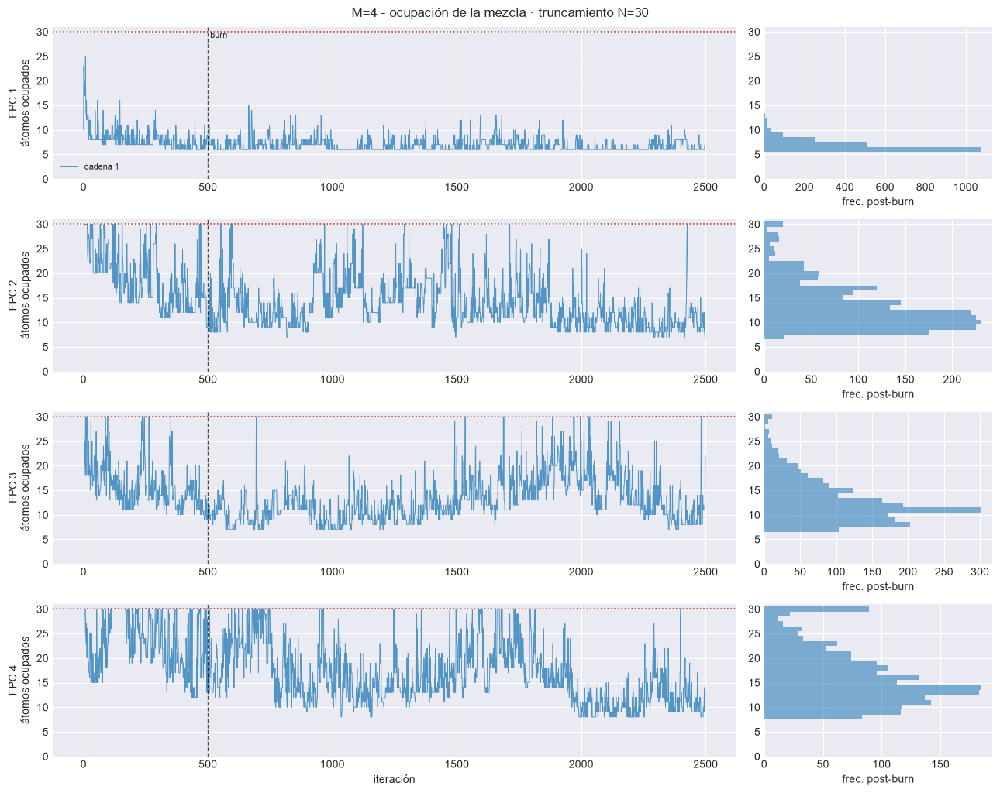

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,4,1,1,6.81,15,12.0,30,False,0.00%
1,4,2,1,13.34,30,29.0,30,True,1.00%
2,4,3,1,12.78,30,27.0,30,True,0.55%
3,4,4,1,16.11,30,30.0,30,True,4.45%


! [M=5] alguna cadena alcanza N: subir mcmc_config['N'].


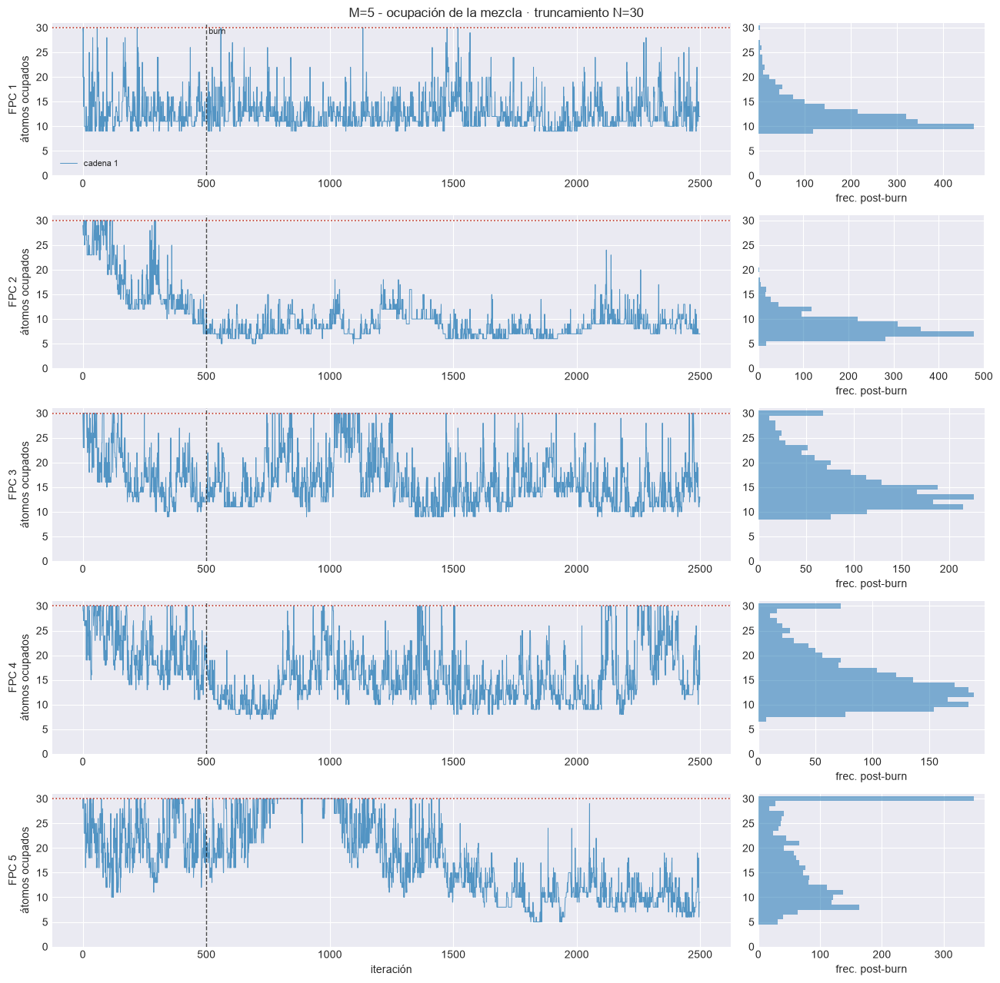

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,5,1,1,12.59,30,24.0,30,True,0.20%
1,5,2,1,8.60,24,16.0,30,False,0.00%
2,5,3,1,15.85,30,30.0,30,True,3.40%
3,5,4,1,15.04,30,30.0,30,True,3.60%
4,5,5,1,17.19,30,30.0,30,True,17.45%


! [M=6] alguna cadena alcanza N: subir mcmc_config['N'].


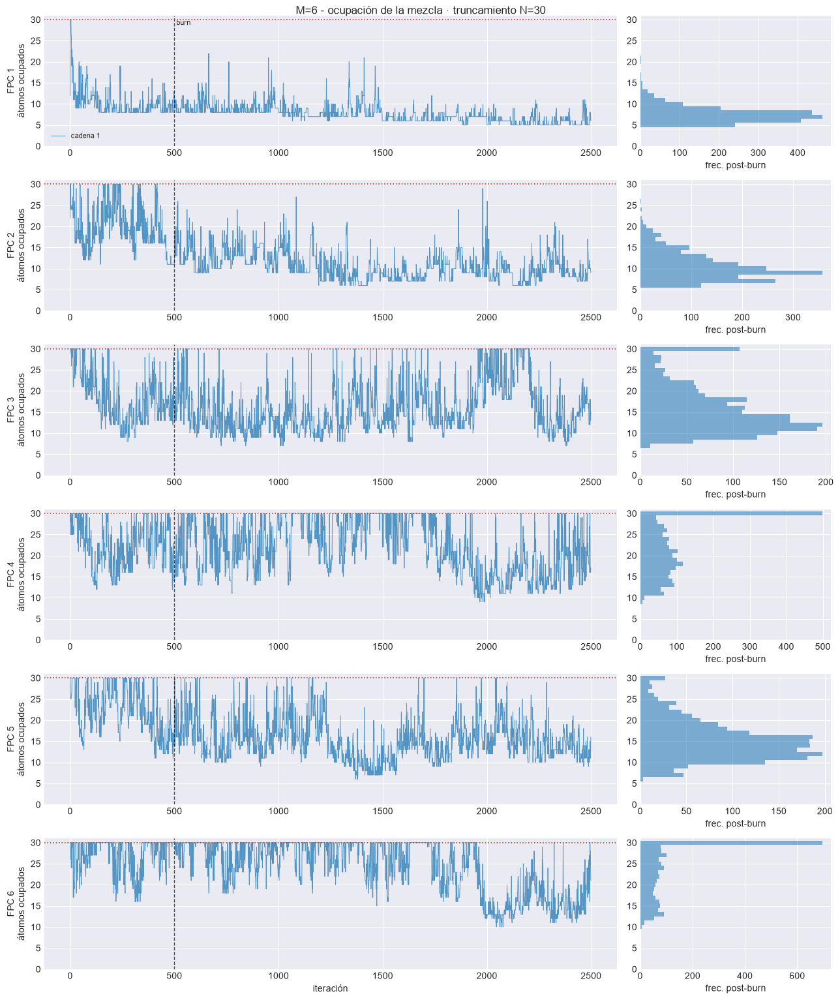

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,6,1,1,7.52,22,14.0,30,False,0.00%
1,6,2,1,10.54,29,20.0,30,False,0.00%
2,6,3,1,15.74,30,30.0,30,True,5.35%
3,6,4,1,22.02,30,30.0,30,True,24.90%
4,6,5,1,15.16,30,30.0,30,True,1.35%
5,6,6,1,23.97,30,30.0,30,True,34.75%


In [6]:
for M in M_OK:
    e = EST[M]
    ocup_df = ocupacion_mezcla(e, M)
    plot_ocupacion_mezcla(e, M, e["paths"]["out_report"] / "41_ocupacion_mezcla.png")
    plt.show()
    display(ocup_df.style.format({"media": "{:.2f}", "p99": "{:.1f}", "frac_en_N": "{:.2%}"})
            .set_caption(f"M={M} - átomos ocupados post-calentamiento"))

### 4.1 Gating: $\psi$, $\alpha$, $\Gamma$

Promedios ponderados por el peso medio de cada átomo, $\bar w_h=\frac1n\sum_i\pi_h(x_i)$,
para que no dependan del etiquetado. **Señal de gating** = átomos efectivos
globales menos por punto (≈ 0 si los pesos son los mismos en todo $x$);
**sd del argumento** = dispersión en $i$ de $\alpha_h-\sum_j\psi_{hj}|x_{ij}-\Gamma_{hj}|$.

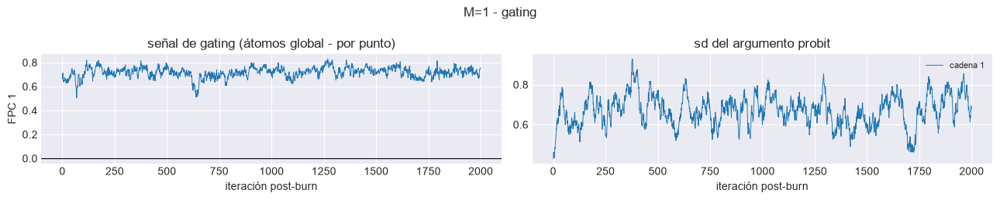

,M,FPC,variable,media_c1,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,1,atomos_global,2.841,1,2000,28,28,2.222,nan,False
1,1,1,atomos_punto,2.124,1,2000,26,26,2.648,nan,False
2,1,1,senal_gating,0.717,1,2000,42,42,0.734,nan,False
3,1,1,sd_argumento,0.671,1,2000,62,62,0.867,nan,False
4,1,1,alpha,0.940,1,2000,30,30,1.982,nan,False
5,1,1,psi_0,0.932,1,2000,66,66,1.139,nan,False
6,1,1,Gamma_0,0.370,1,2000,6,6,1.613,nan,False


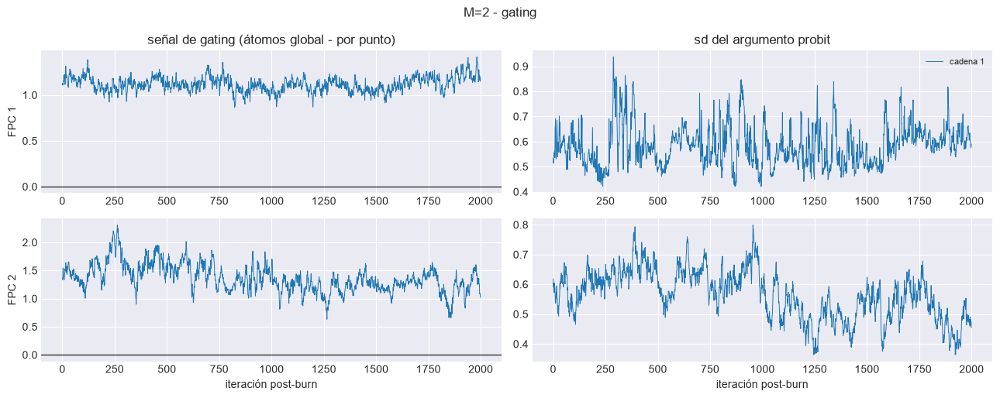

,M,FPC,variable,media_c1,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,2,1,atomos_global,3.461,1,2000,68,68,0.196,nan,False
1,2,1,atomos_punto,2.342,1,2000,62,62,0.794,nan,False
2,2,1,senal_gating,1.119,1,2000,35,35,1.202,nan,False
3,2,1,sd_argumento,0.583,1,2000,68,68,0.680,nan,False
4,2,1,alpha,1.970,1,2000,16,16,0.439,nan,False
5,2,1,psi_0,0.871,1,2000,60,60,1.110,nan,False
6,2,1,psi_1,0.759,1,2000,11,11,0.510,nan,False
7,2,1,Gamma_0,-0.701,1,2000,47,47,0.224,nan,False
8,2,1,Gamma_1,-0.133,1,2000,9,9,0.036,nan,False
9,2,2,atomos_global,5.596,1,2000,8,8,3.532,nan,False


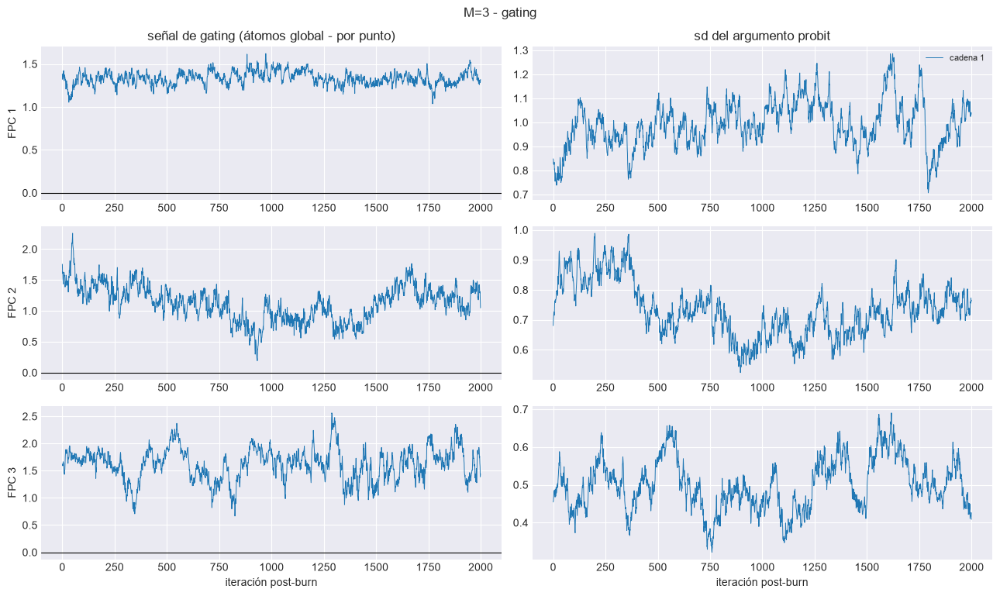

,M,FPC,variable,media_c1,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,3,1,atomos_global,3.441,1,2000,59,59,1.995,nan,False
1,3,1,atomos_punto,2.107,1,2000,40,40,2.366,nan,False
2,3,1,senal_gating,1.334,1,2000,36,36,1.230,nan,False
3,3,1,sd_argumento,0.991,1,2000,29,29,1.715,nan,False
4,3,1,alpha,1.753,1,2000,6,6,4.547,nan,False
5,3,1,psi_0,1.067,1,2000,11,11,2.394,nan,False
6,3,1,psi_1,0.959,1,2000,6,6,5.666,nan,False
7,3,1,psi_2,1.558,1,2000,28,28,3.231,nan,False
8,3,1,Gamma_0,-0.249,1,2000,44,44,0.481,nan,False
9,3,1,Gamma_1,-0.781,1,2000,7,7,5.431,nan,False


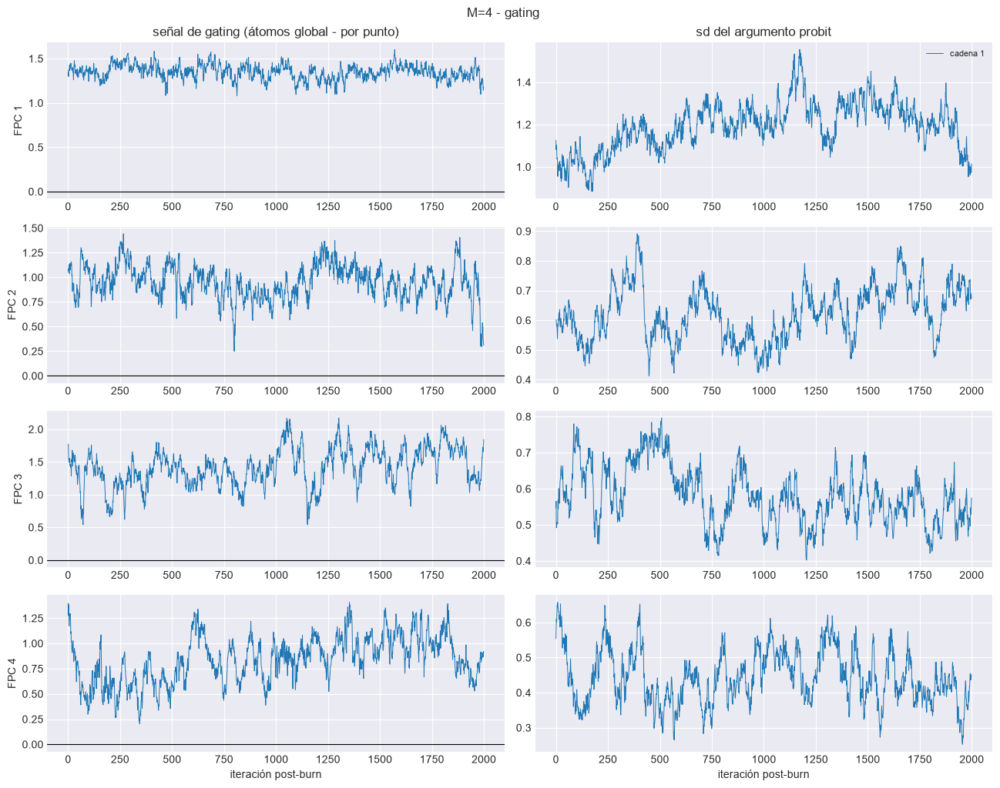

,M,FPC,variable,media_c1,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,4,1,atomos_global,3.451,1,2000,11,11,6.044,nan,False
1,4,1,atomos_punto,2.103,1,2000,7,7,6.641,nan,False
2,4,1,senal_gating,1.348,1,2000,51,51,0.300,nan,False
3,4,1,sd_argumento,1.193,1,2000,7,7,7.730,nan,False
4,4,1,alpha,2.863,1,2000,6,6,3.997,nan,False
5,4,1,psi_0,1.151,1,2000,26,26,3.623,nan,False
6,4,1,psi_1,1.424,1,2000,4,4,25.837,nan,False
7,4,1,psi_2,1.968,1,2000,15,15,1.718,nan,False
8,4,1,psi_3,3.103,1,2000,10,10,2.084,nan,False
9,4,1,Gamma_0,-0.299,1,2000,58,58,2.536,nan,False


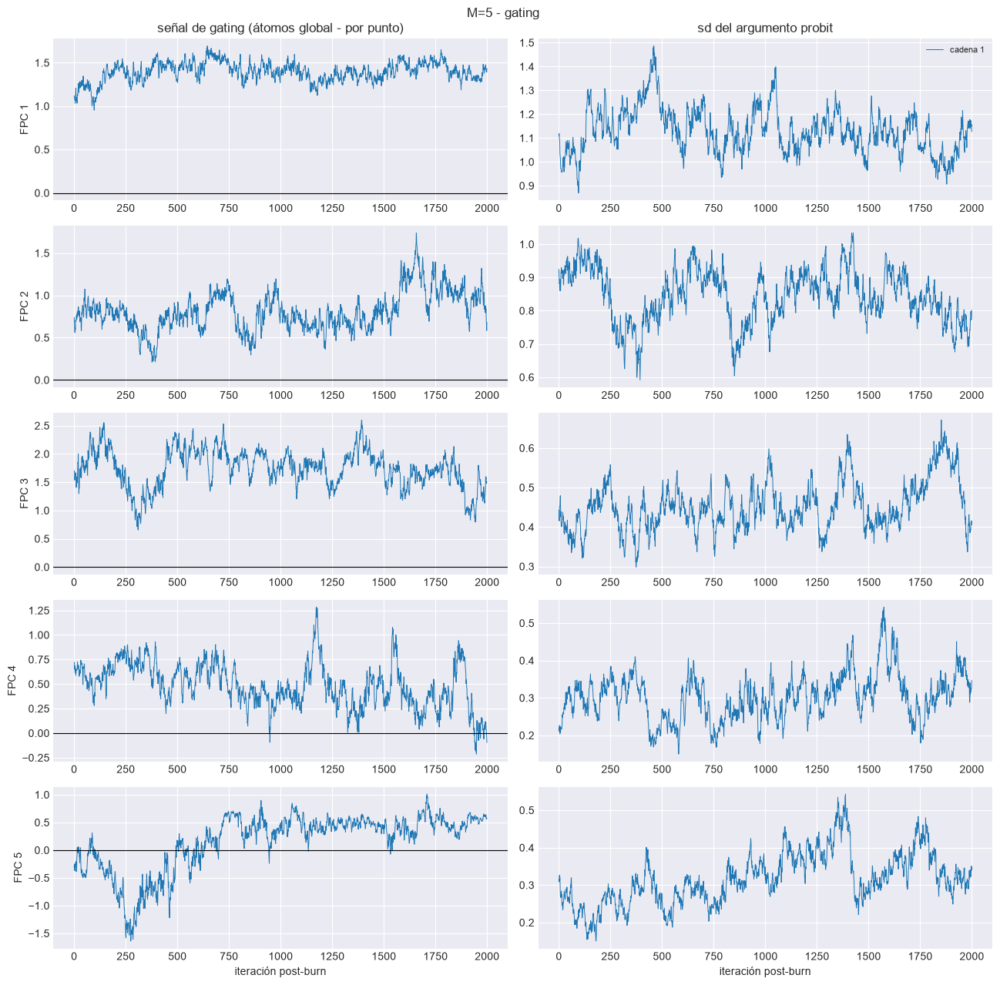

,M,FPC,variable,media_c1,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,5,1,atomos_global,3.436,1,2000,19,19,1.939,nan,False
1,5,1,atomos_punto,2.040,1,2000,23,23,0.677,nan,False
2,5,1,senal_gating,1.396,1,2000,17,17,2.620,nan,False
3,5,1,sd_argumento,1.131,1,2000,25,25,0.431,nan,False
4,5,1,alpha,2.775,1,2000,12,12,0.906,nan,False
5,5,1,psi_0,1.017,1,2000,28,28,0.616,nan,False
6,5,1,psi_1,0.567,1,2000,15,15,0.063,nan,False
7,5,1,psi_2,3.796,1,2000,30,30,1.691,nan,False
8,5,1,psi_3,4.238,1,2000,52,52,1.772,nan,False
9,5,1,psi_4,0.001,1,2000,170,170,1.403,nan,True


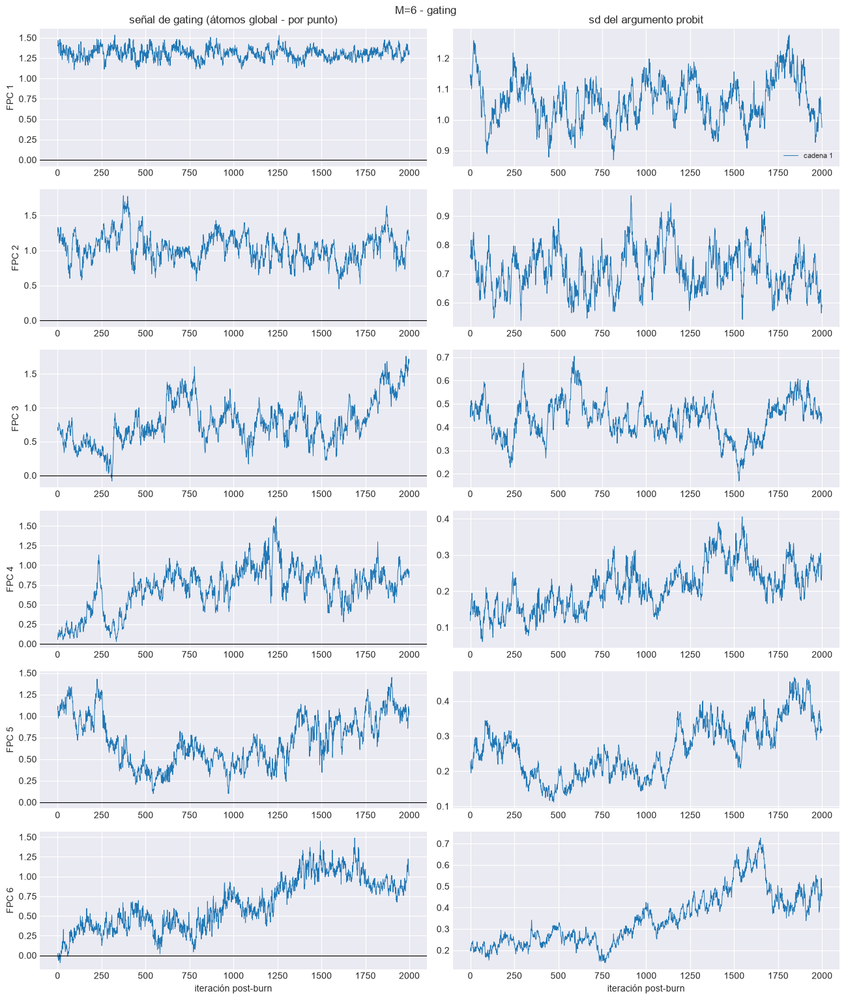

,M,FPC,variable,media_c1,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,6,1,atomos_global,3.542,1,2000,6,6,4.730,nan,False
1,6,1,atomos_punto,2.235,1,2000,5,5,3.652,nan,False
2,6,1,senal_gating,1.307,1,2000,101,101,0.115,nan,True
3,6,1,sd_argumento,1.062,1,2000,30,30,0.377,nan,False
4,6,1,alpha,2.513,1,2000,5,5,2.915,nan,False
5,6,1,psi_0,0.852,1,2000,37,37,0.375,nan,False
6,6,1,psi_1,0.763,1,2000,35,35,0.933,nan,False
7,6,1,psi_2,2.394,1,2000,9,9,3.912,nan,False
8,6,1,psi_3,3.789,1,2000,26,26,0.443,nan,False
9,6,1,psi_4,1.012,1,2000,4,4,8.499,nan,False


In [7]:
_CACHE_GATING = {}      # clave (M, componente, cadena): las series cuestan

for M in M_OK:
    e = EST[M]
    gat, series = diagnostico_gating(e, M, _CACHE_GATING)
    plot_gating(series, e, M, e["paths"]["out_report"] / "49_gating.png")
    plt.show()
    display(gat.style.format({c: "{:.3f}" for c in gat.columns
                              if c.startswith("media_") or c in ("rhat", "geweke_max")}
                             | {"ess_min": "{:.0f}", "ess_mean": "{:.0f}"})
            .set_caption(f"M={M} - gating post-calentamiento"))

## 5. Figuras de convergencia por parámetro

== M=1 ==============================================


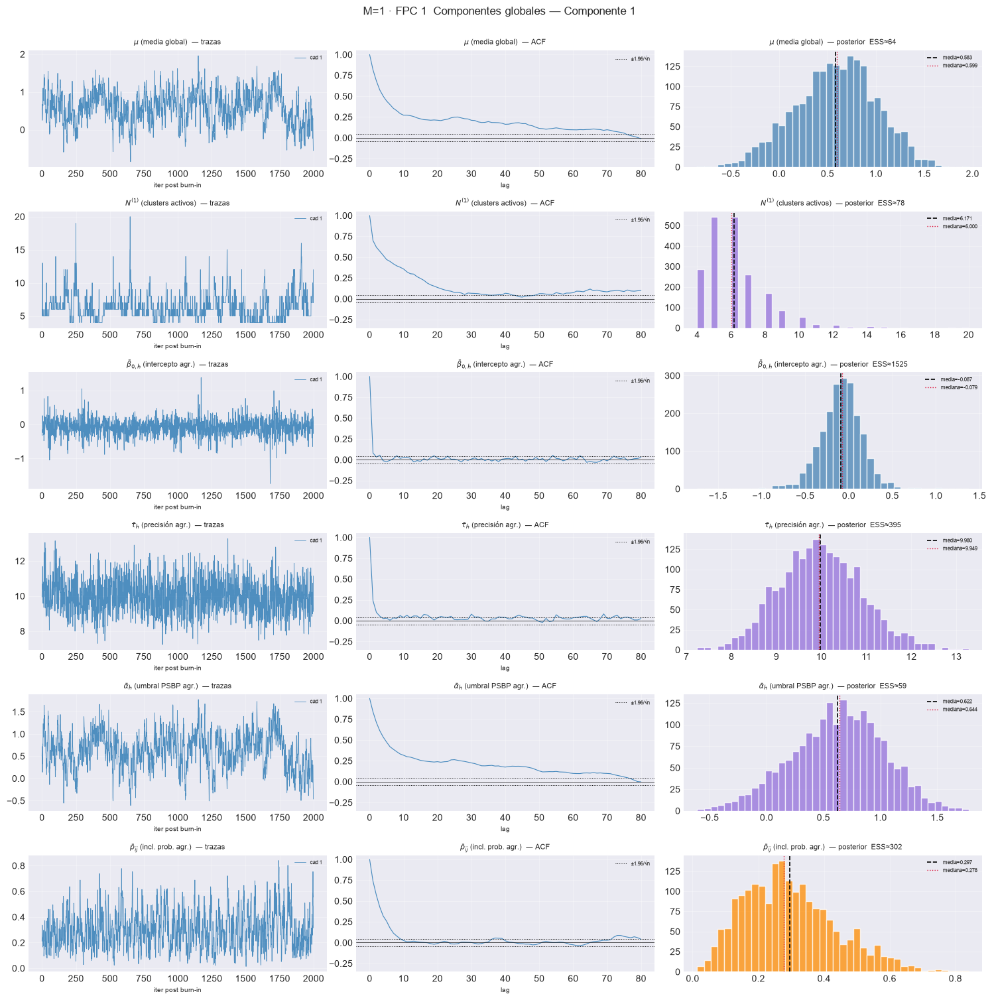

C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:276: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:278: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


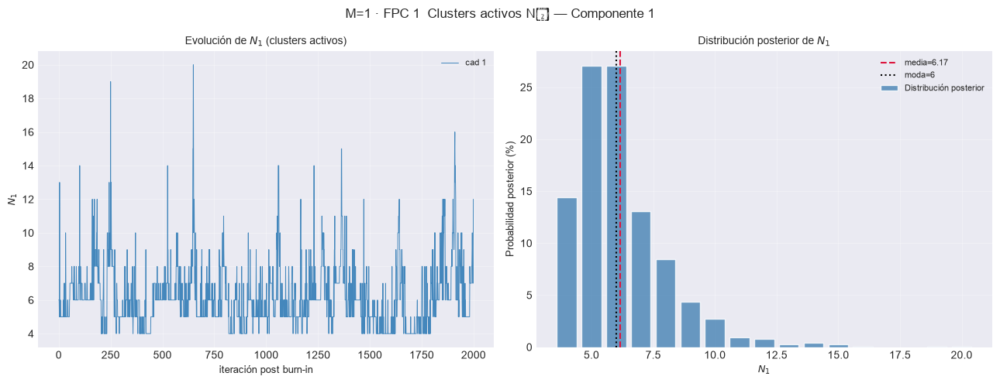

== M=2 ==============================================


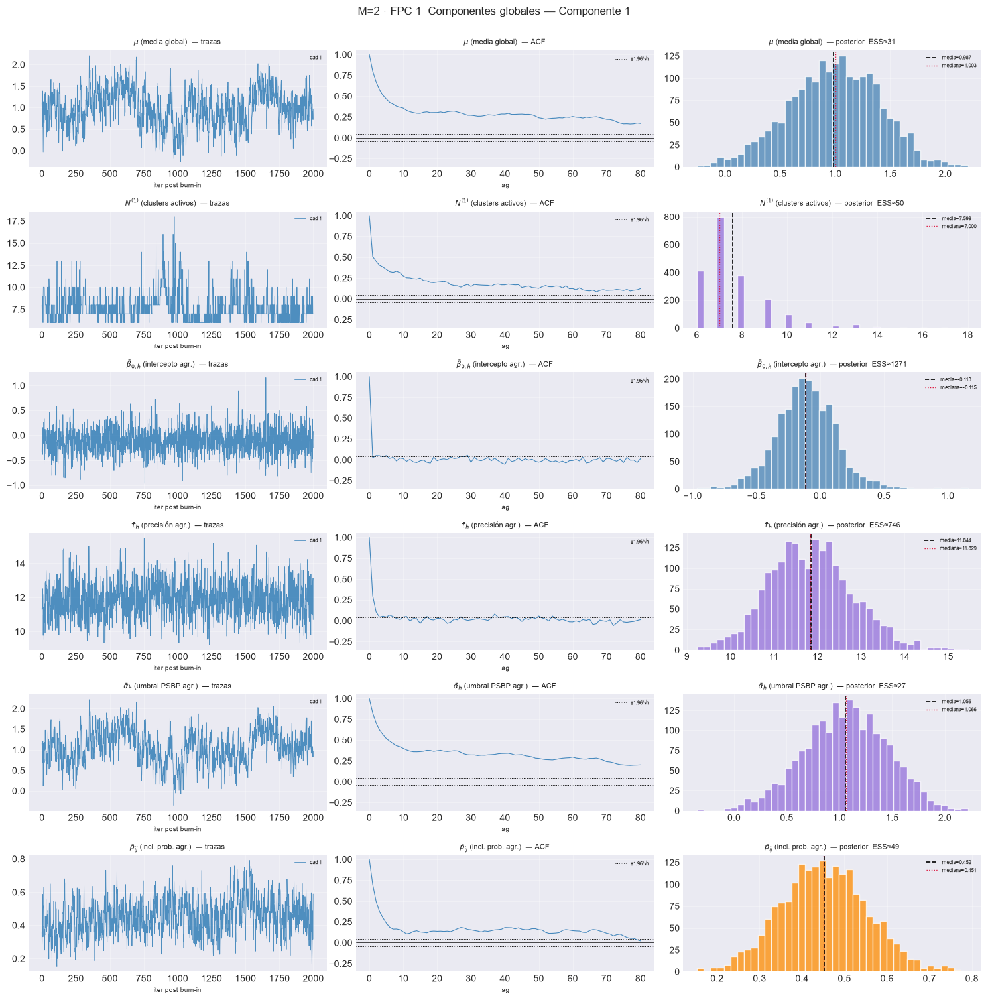

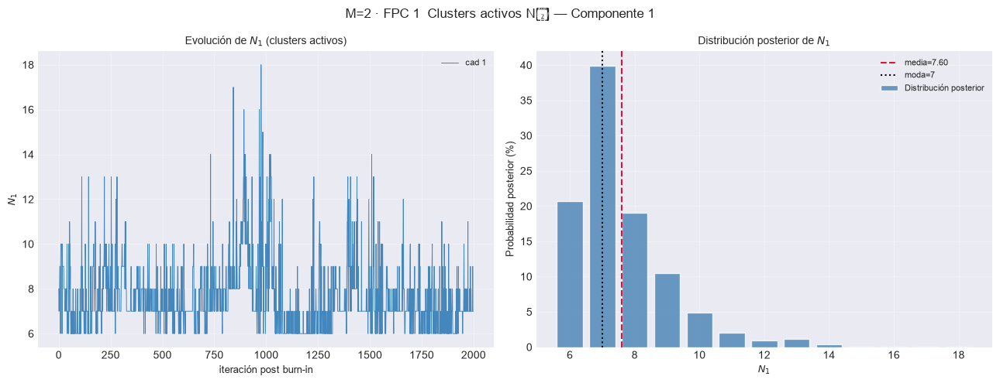

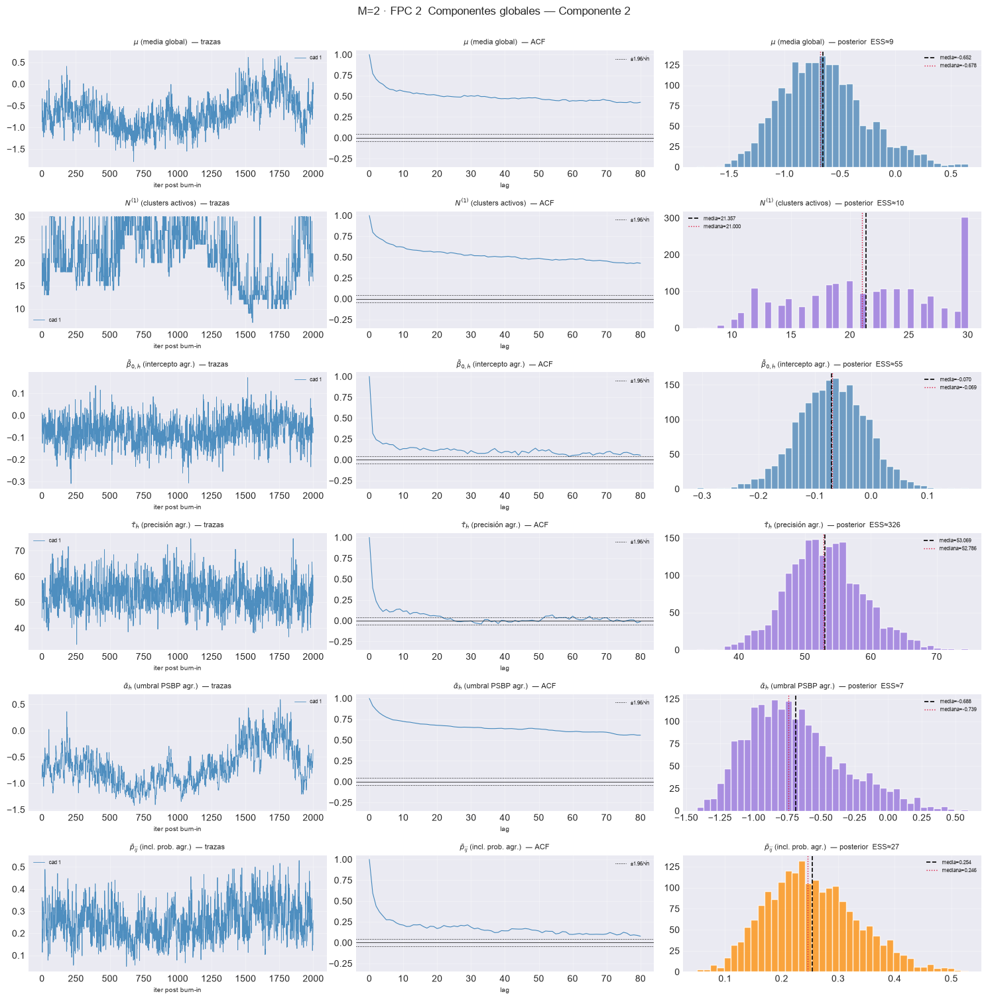

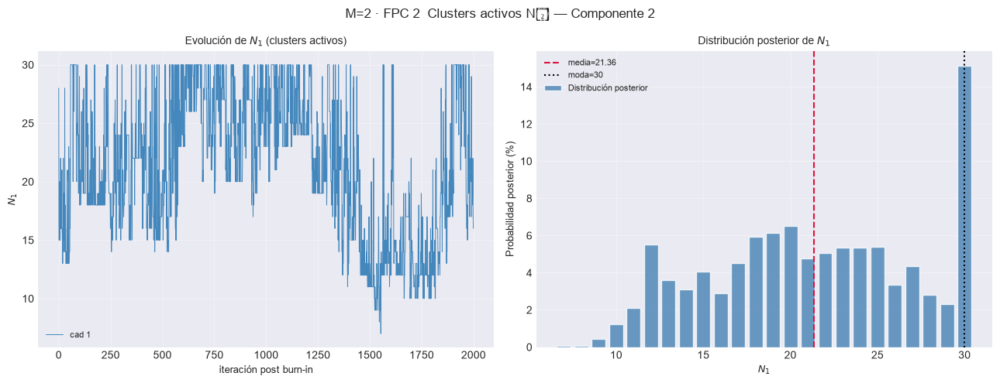

== M=3 ==============================================


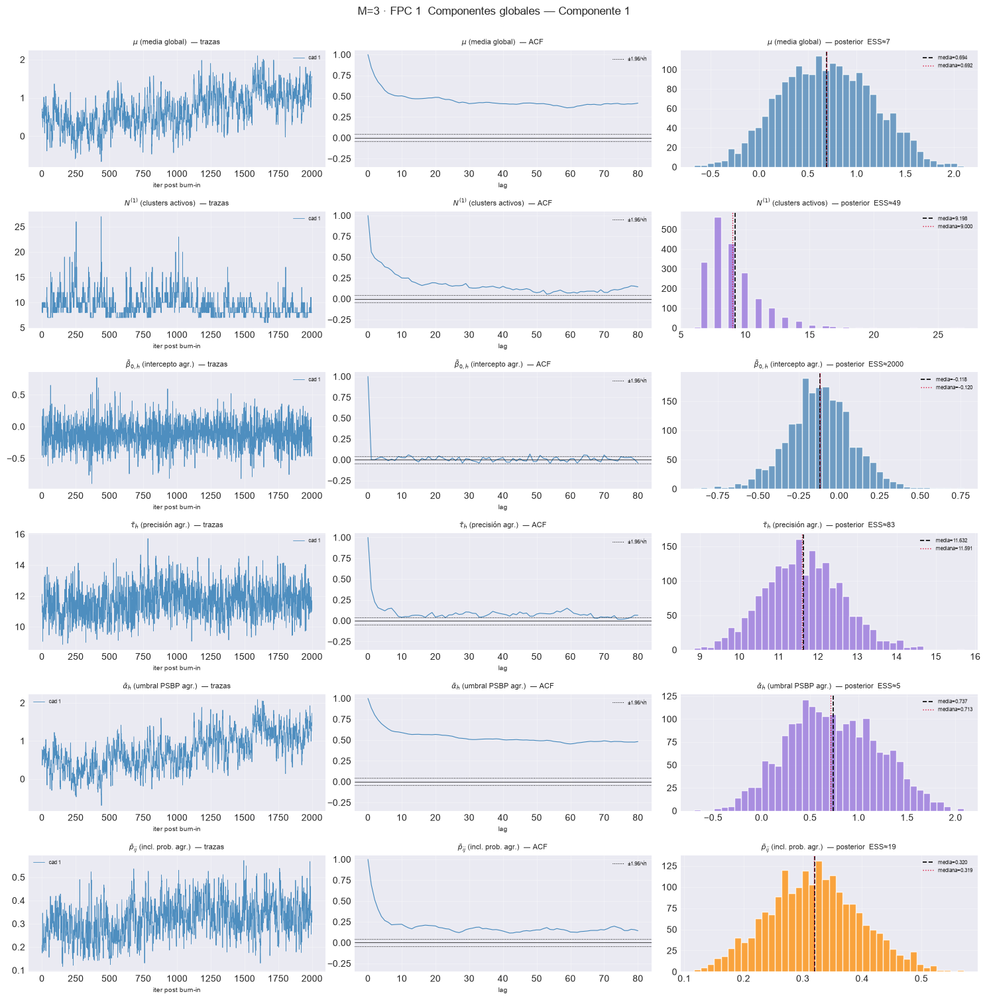

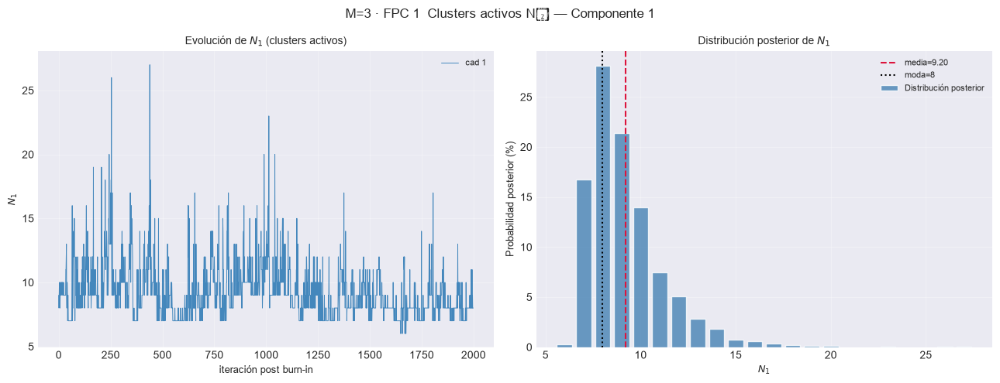

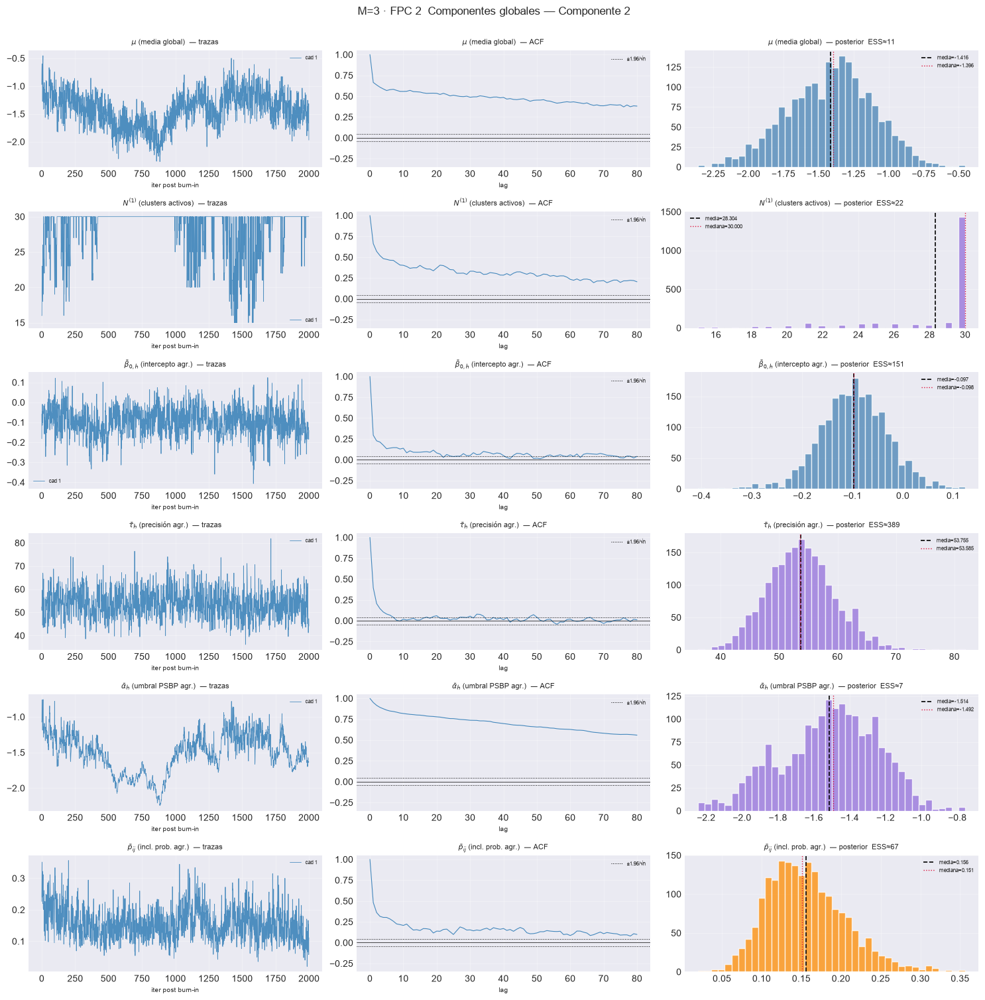

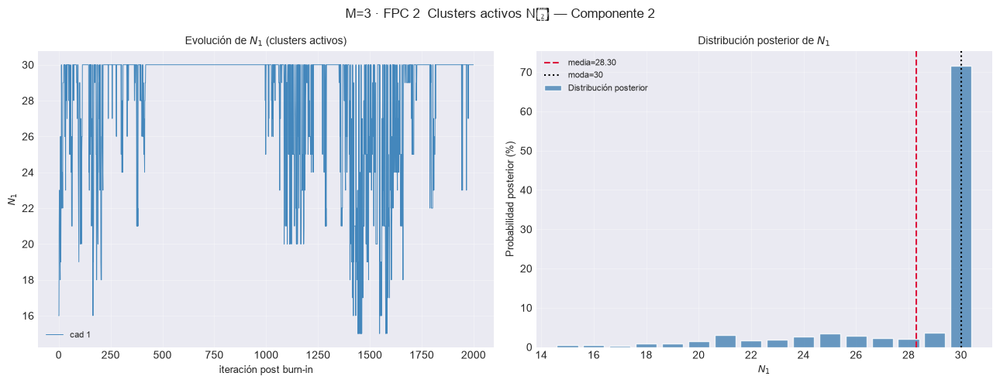

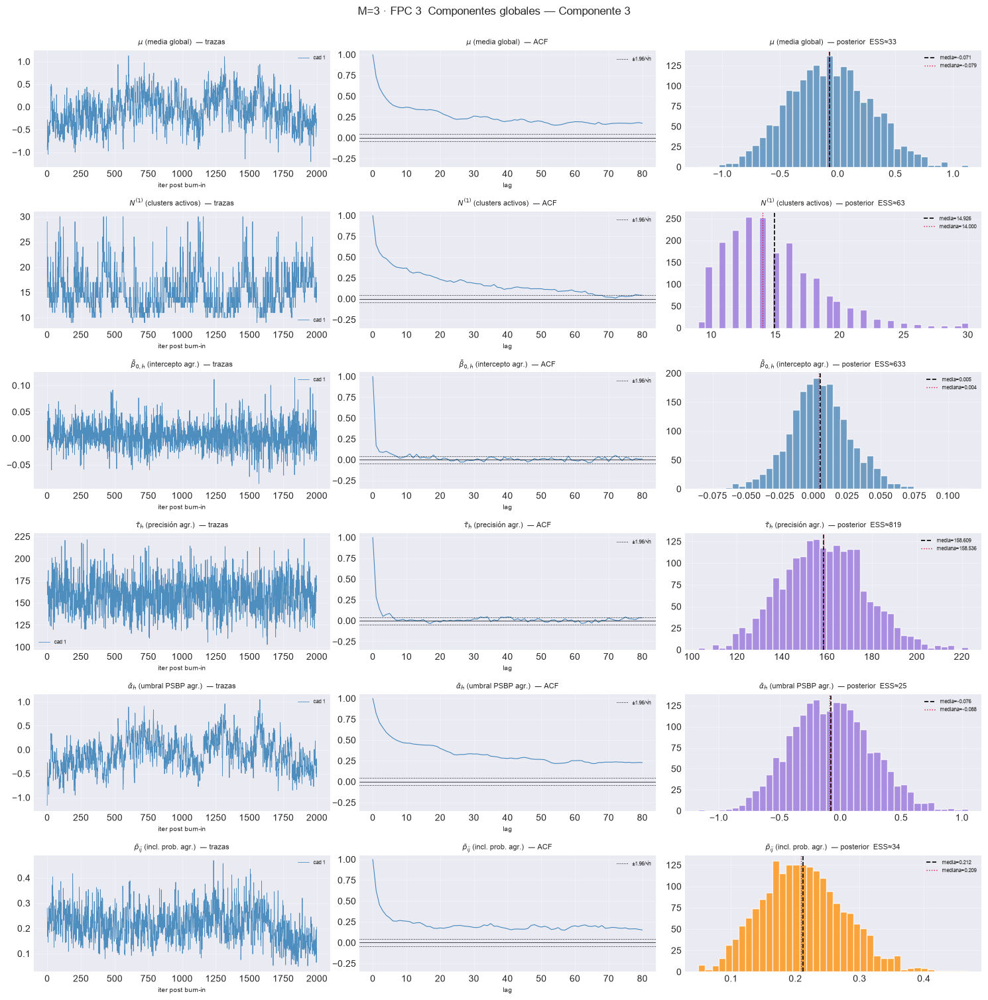

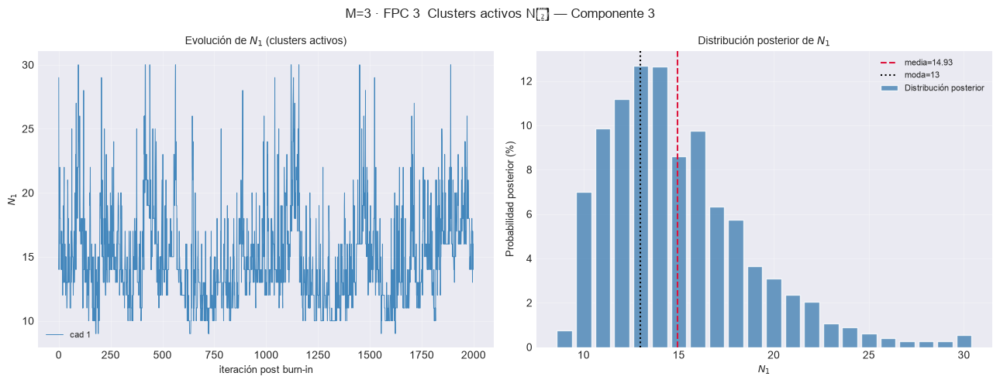

== M=4 ==============================================


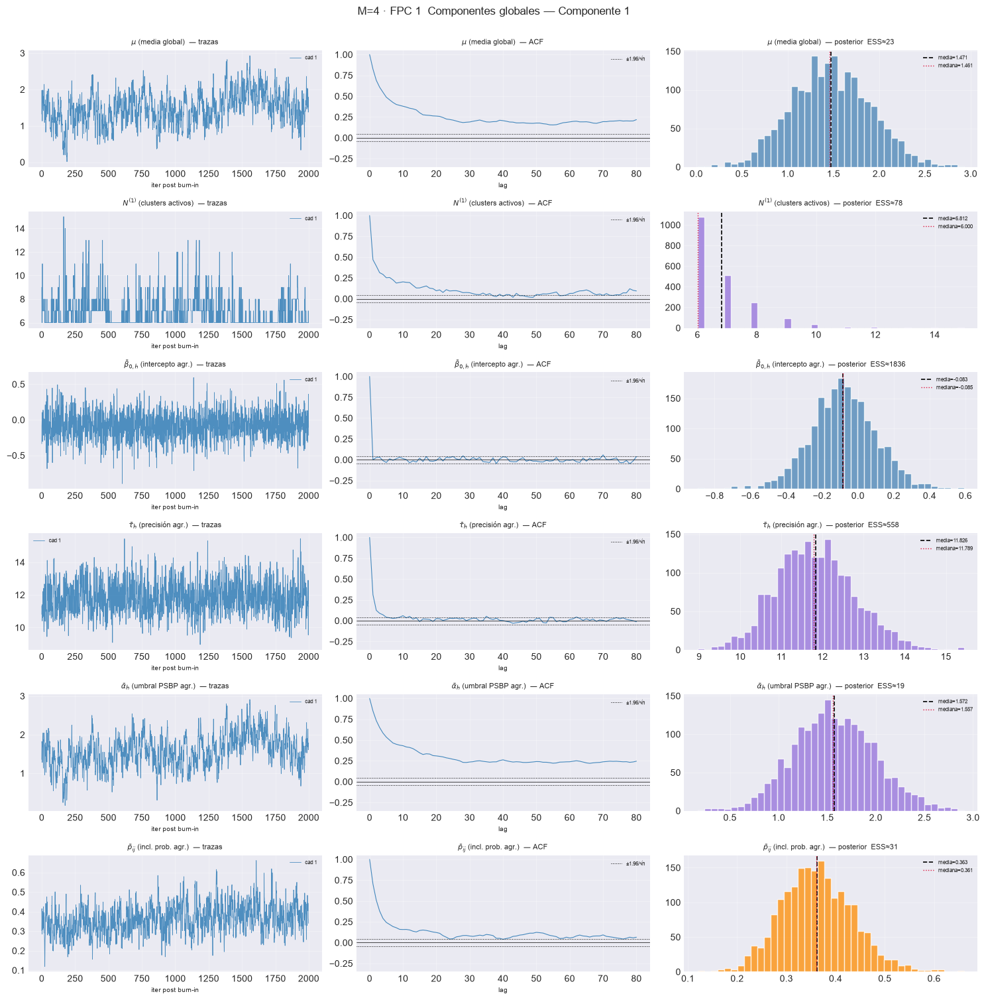

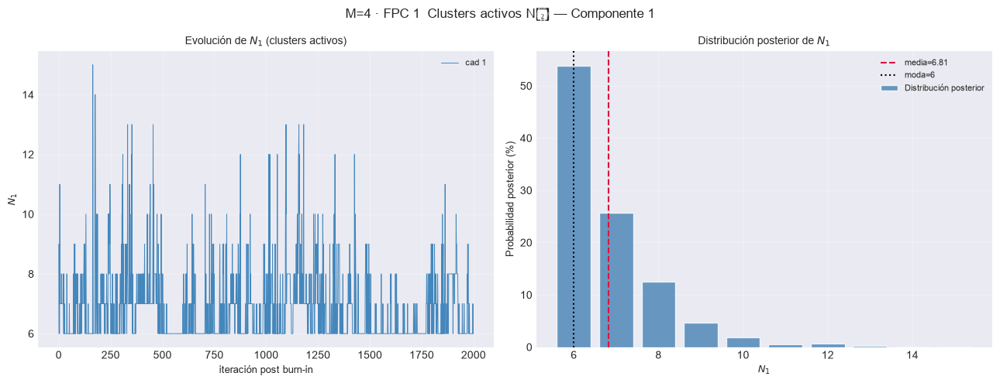

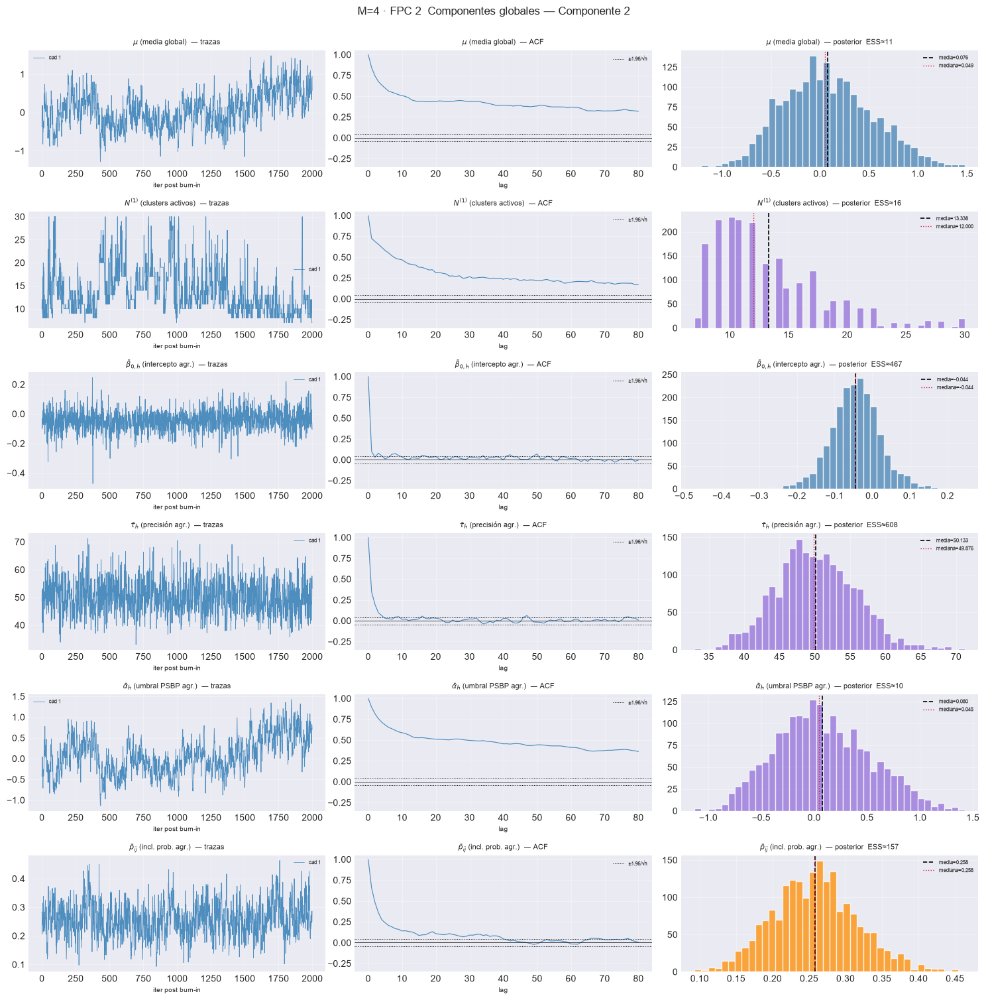

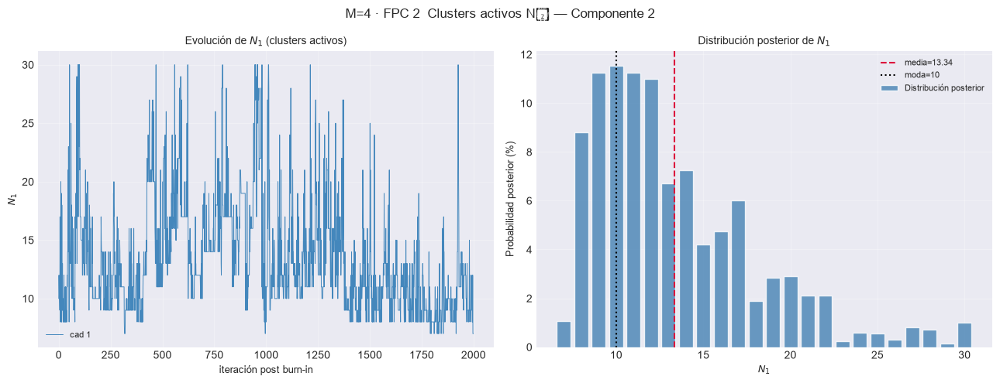

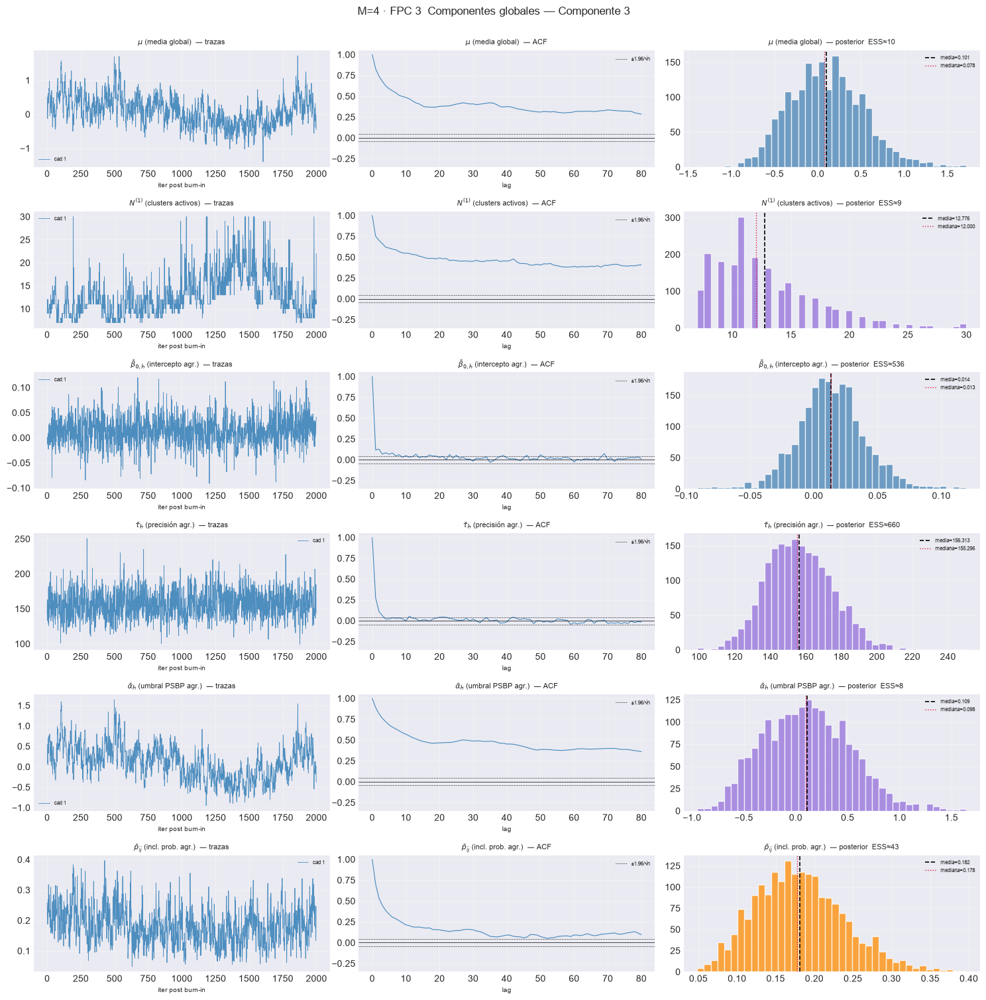

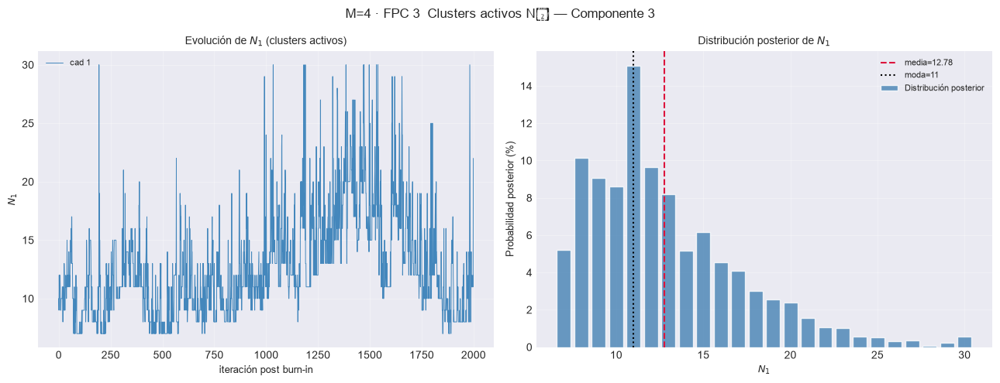

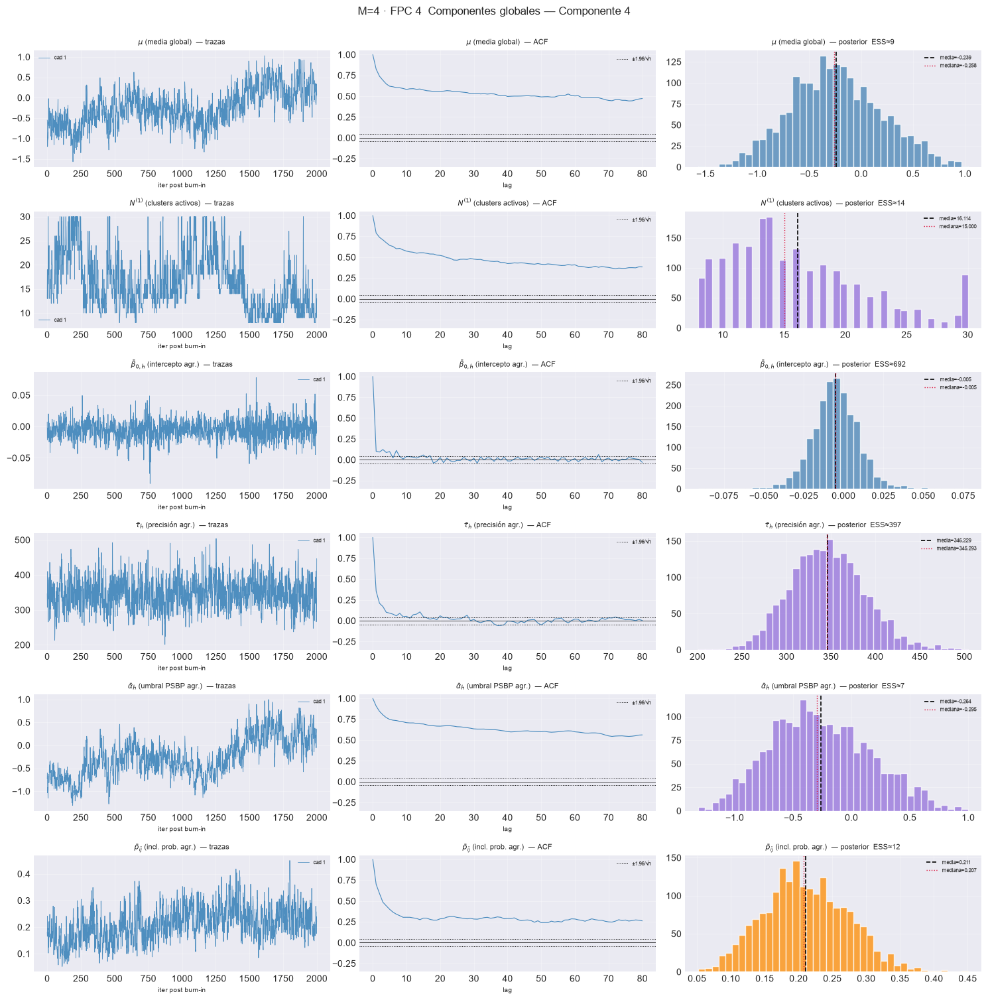

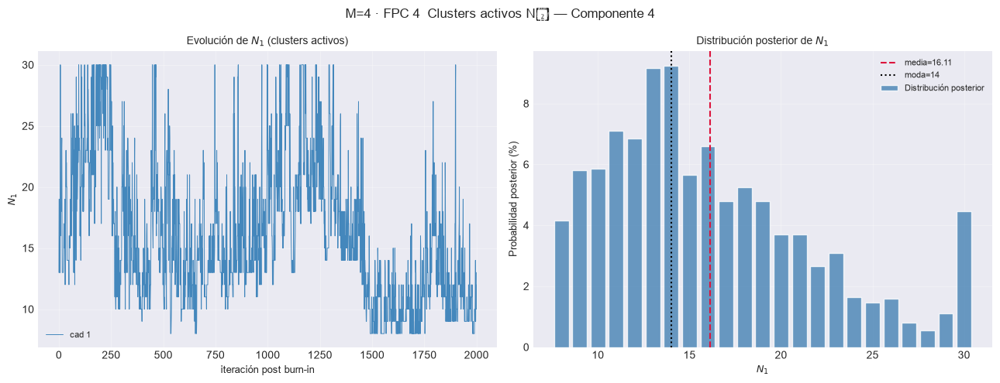

== M=5 ==============================================


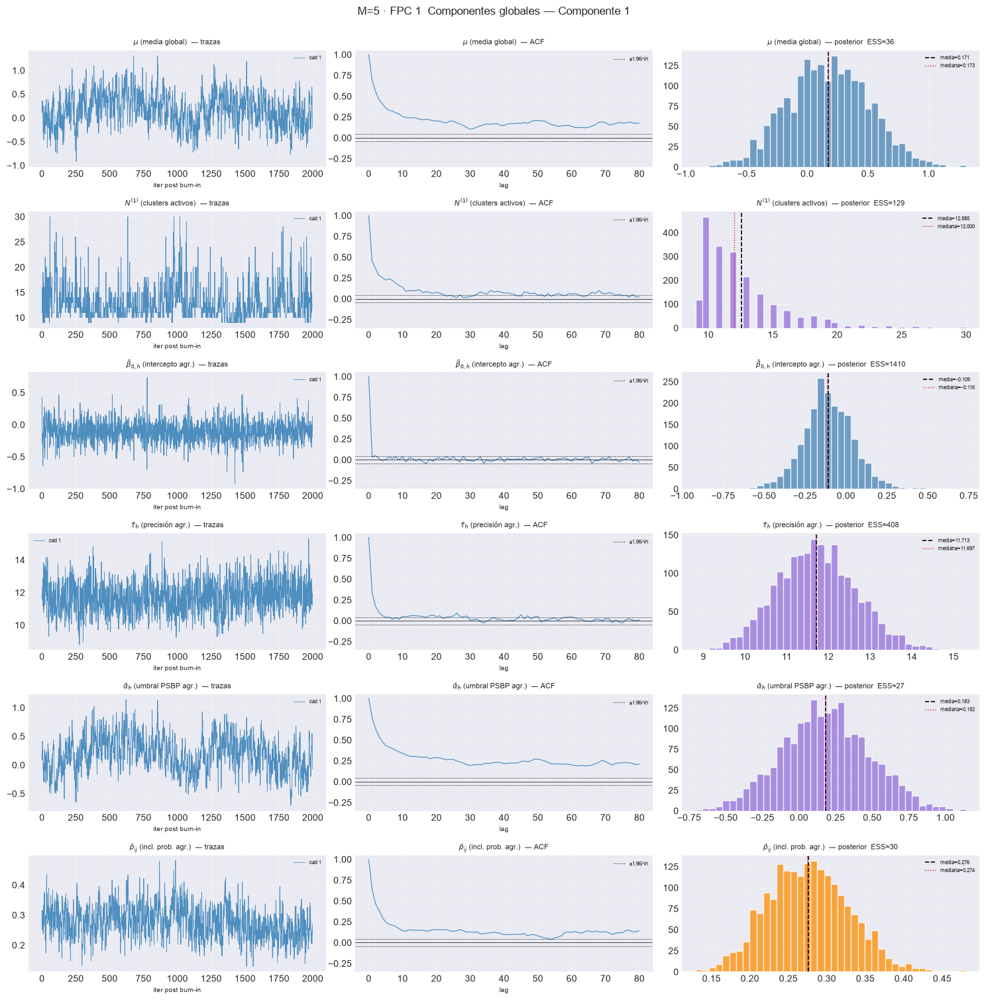

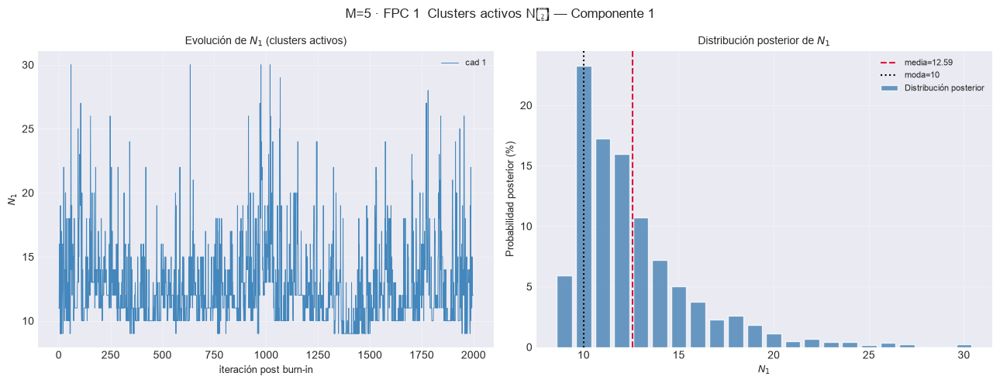

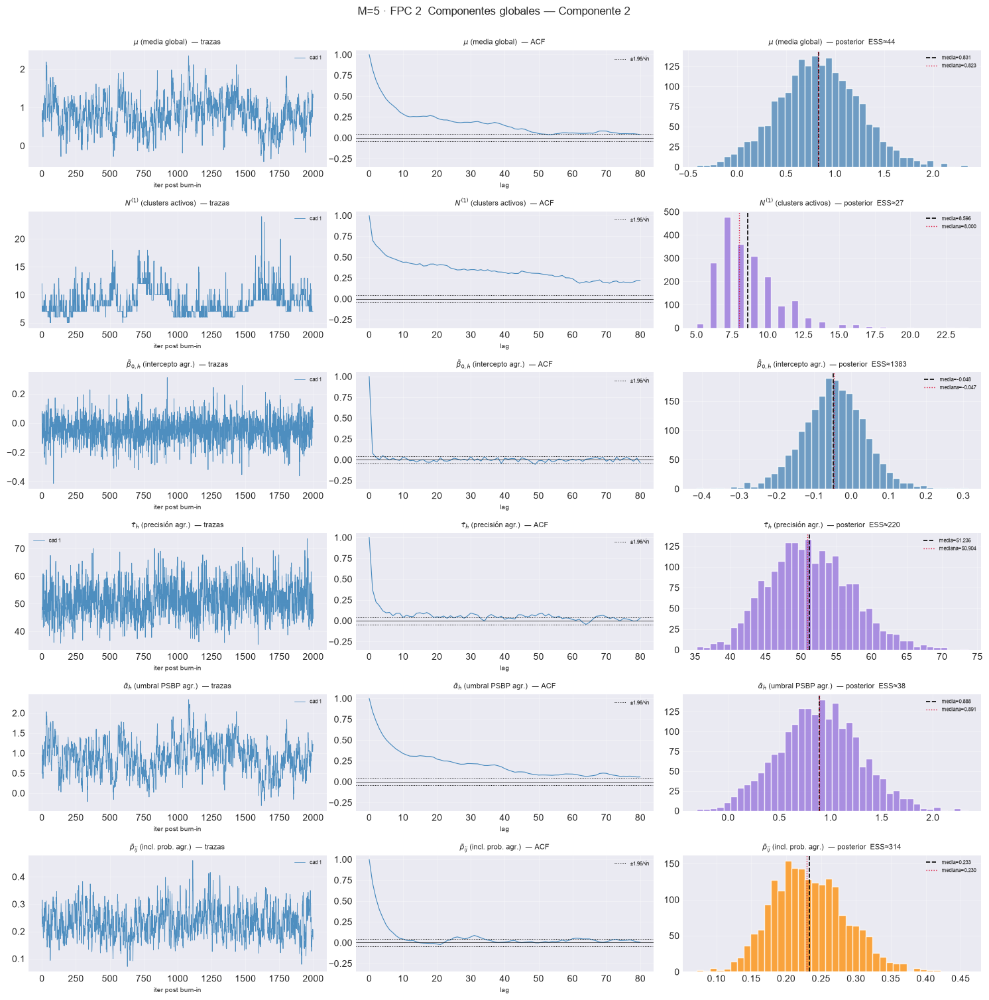

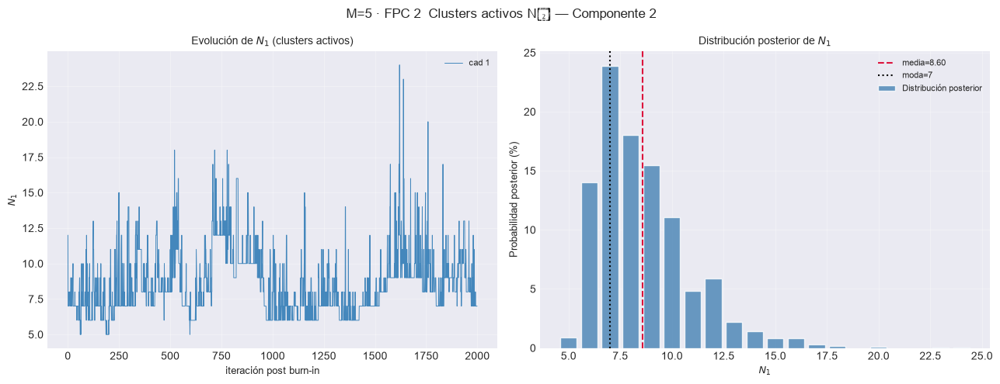

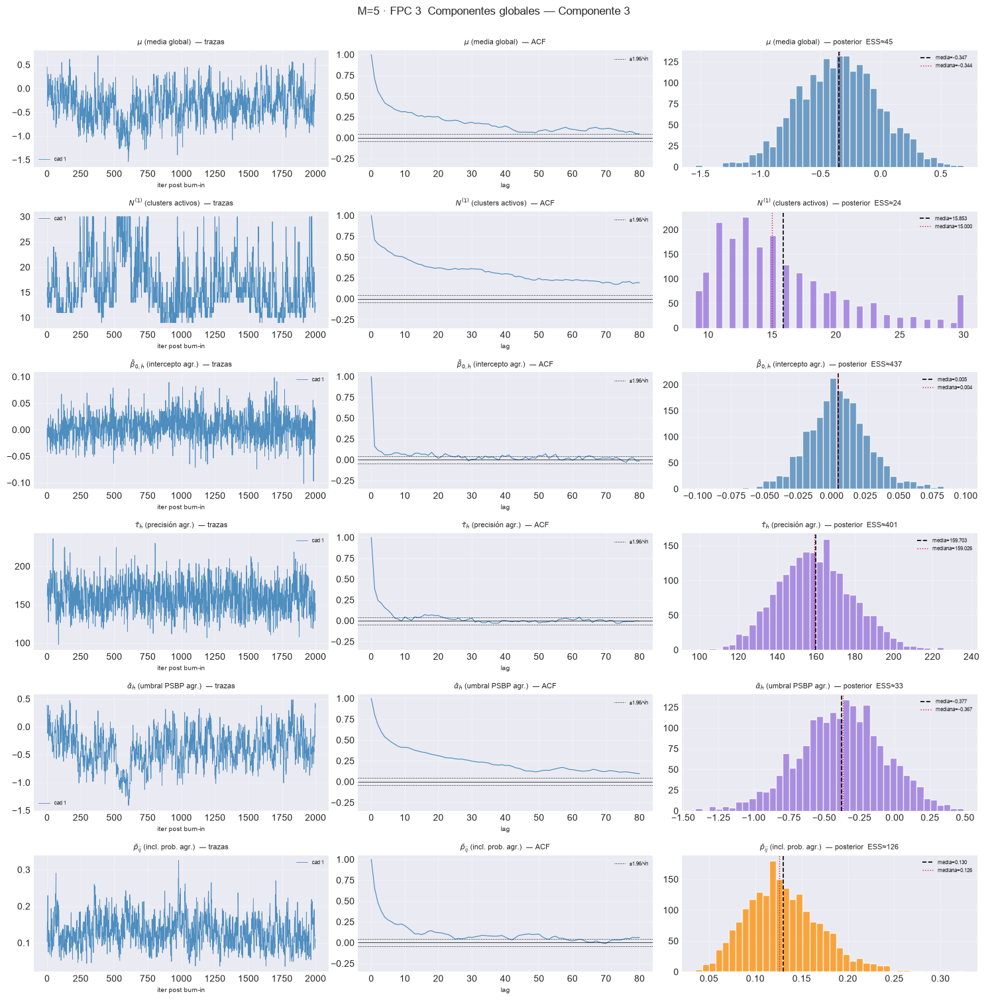

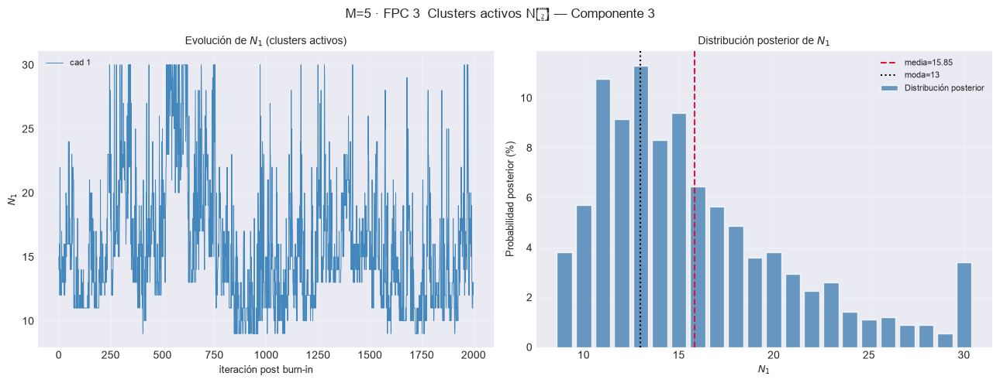

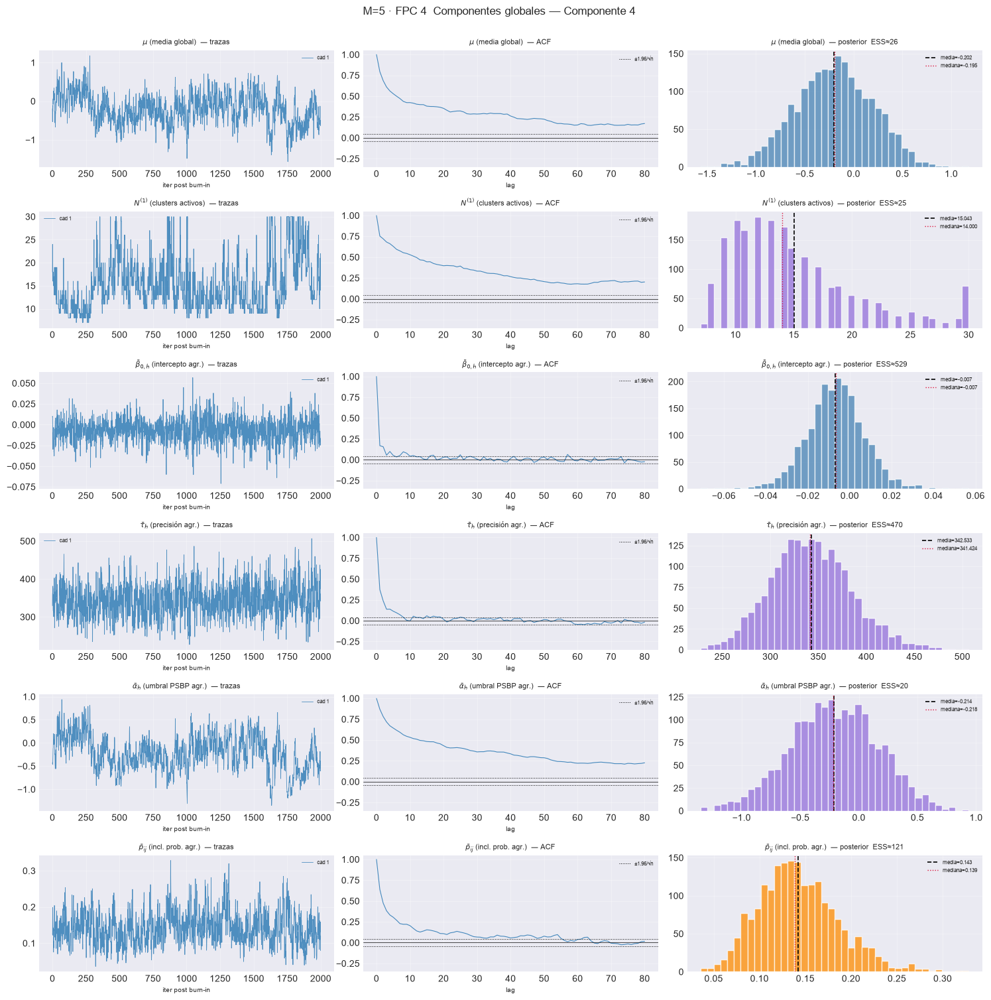

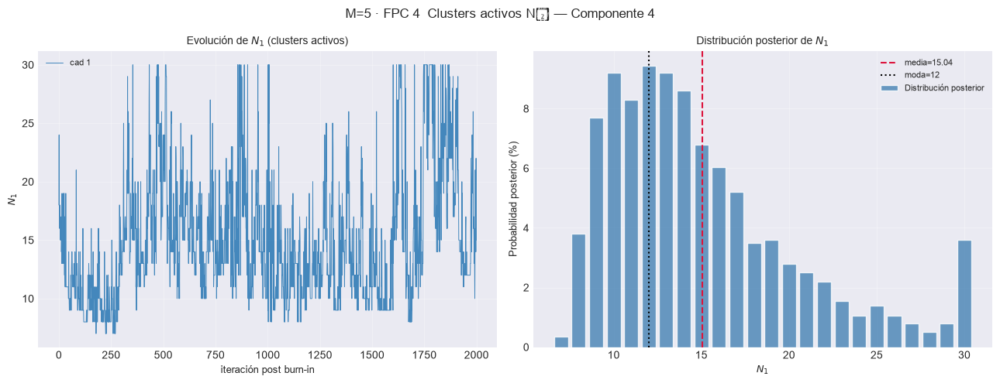

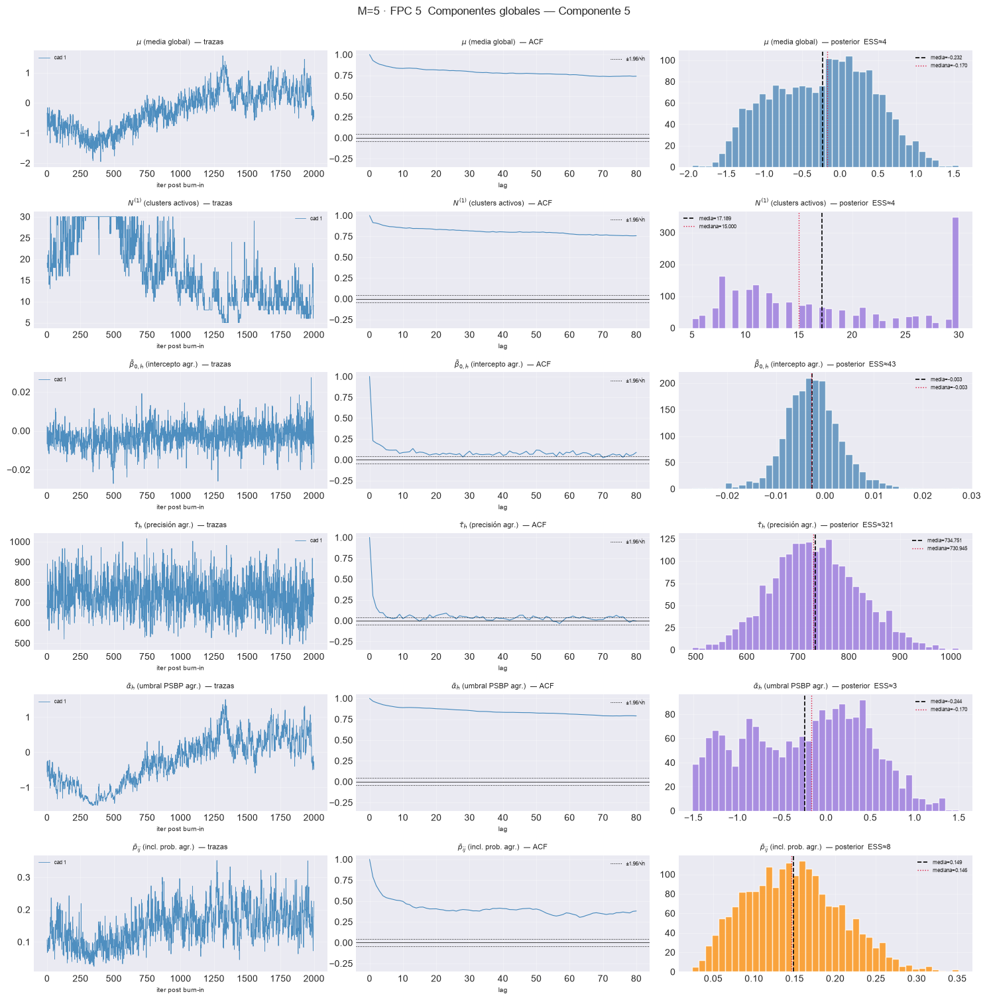

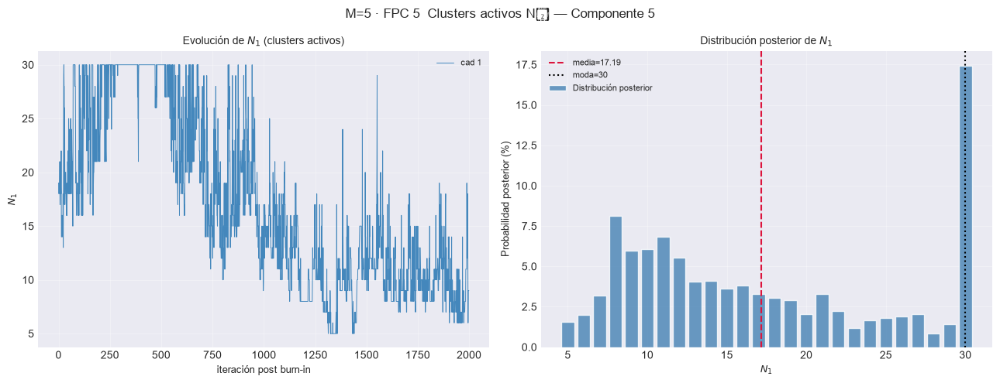

== M=6 ==============================================


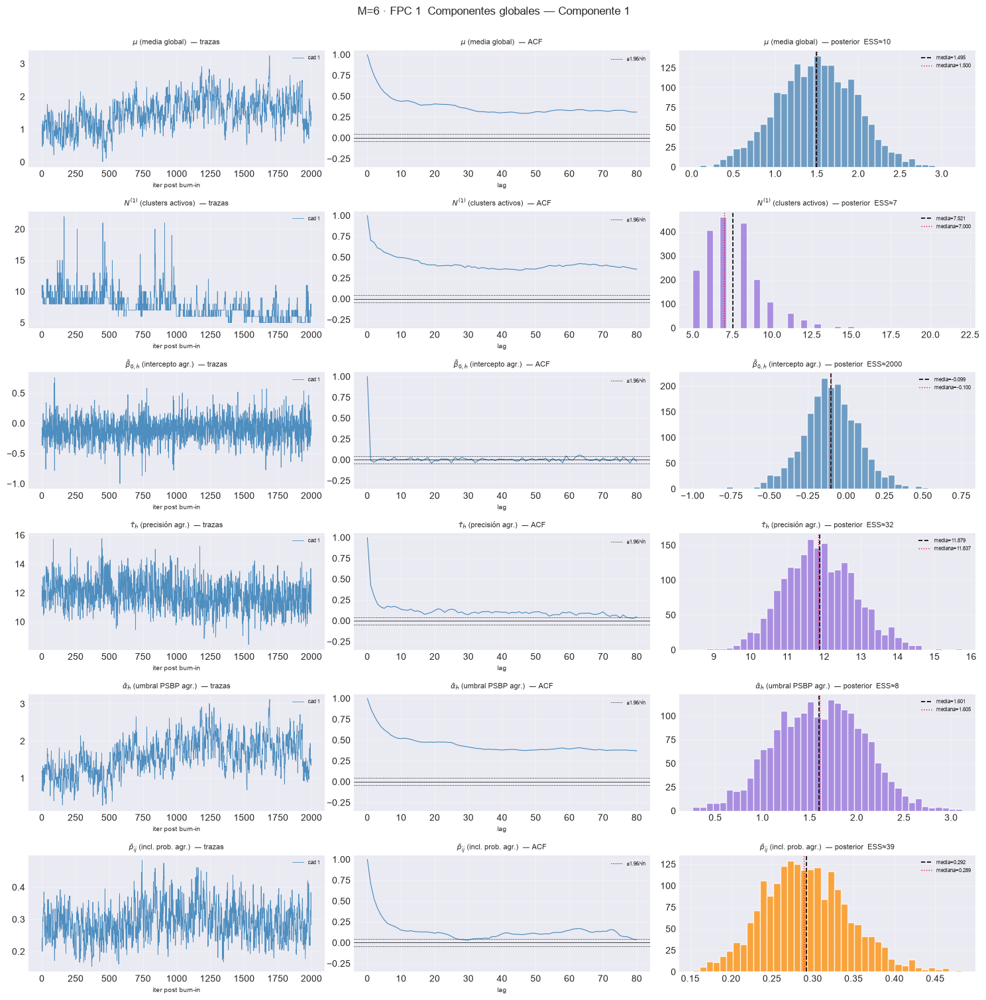

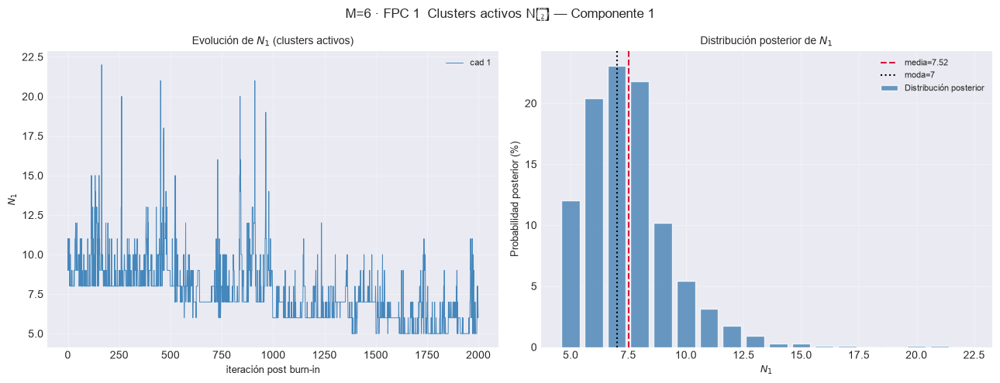

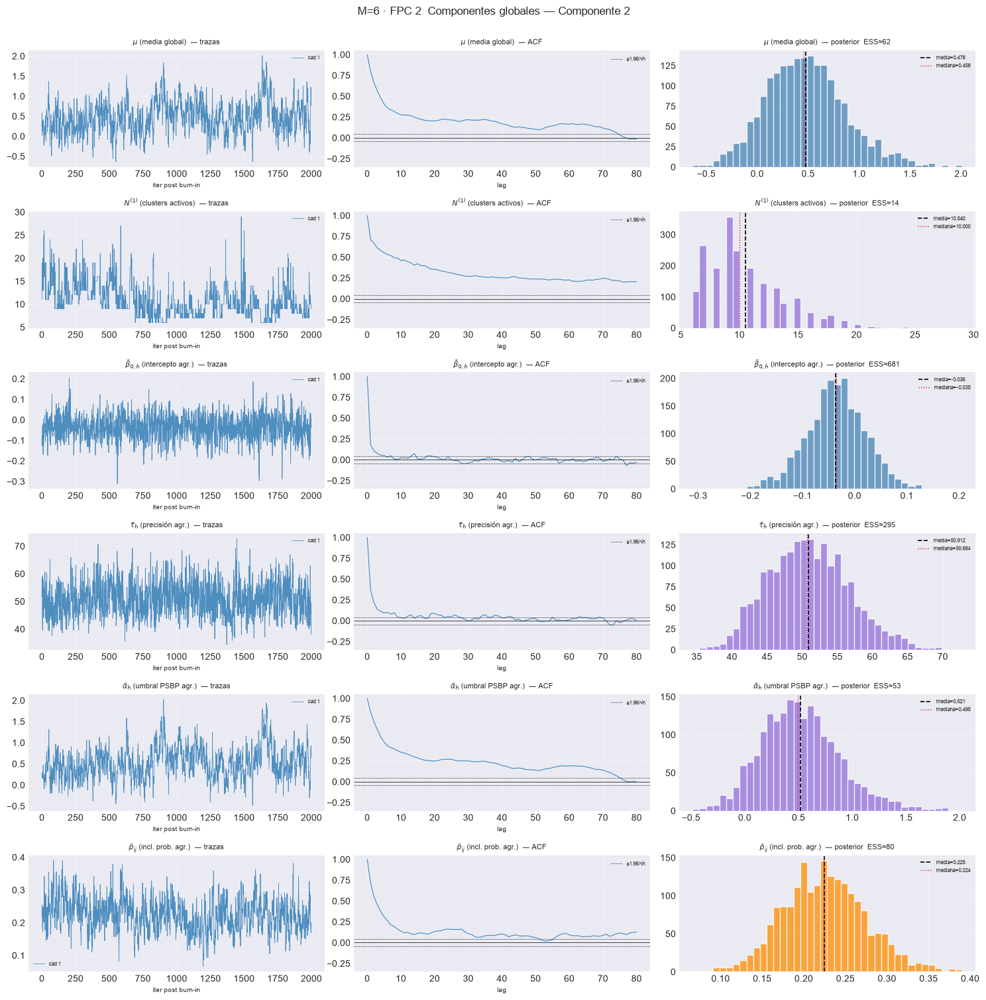

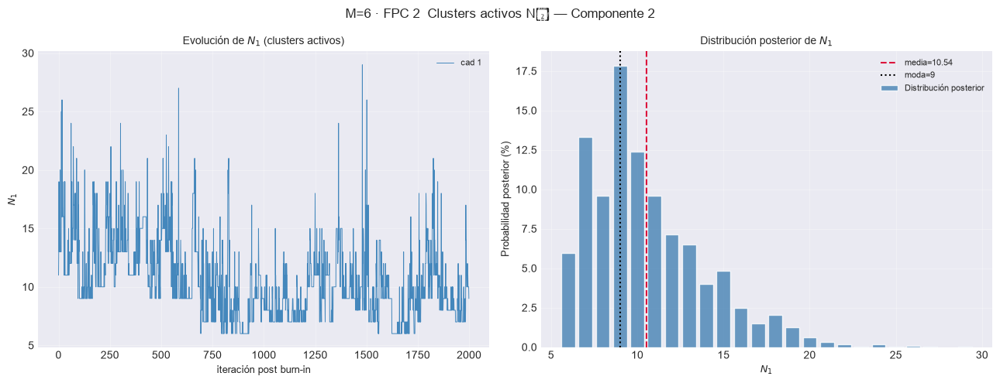

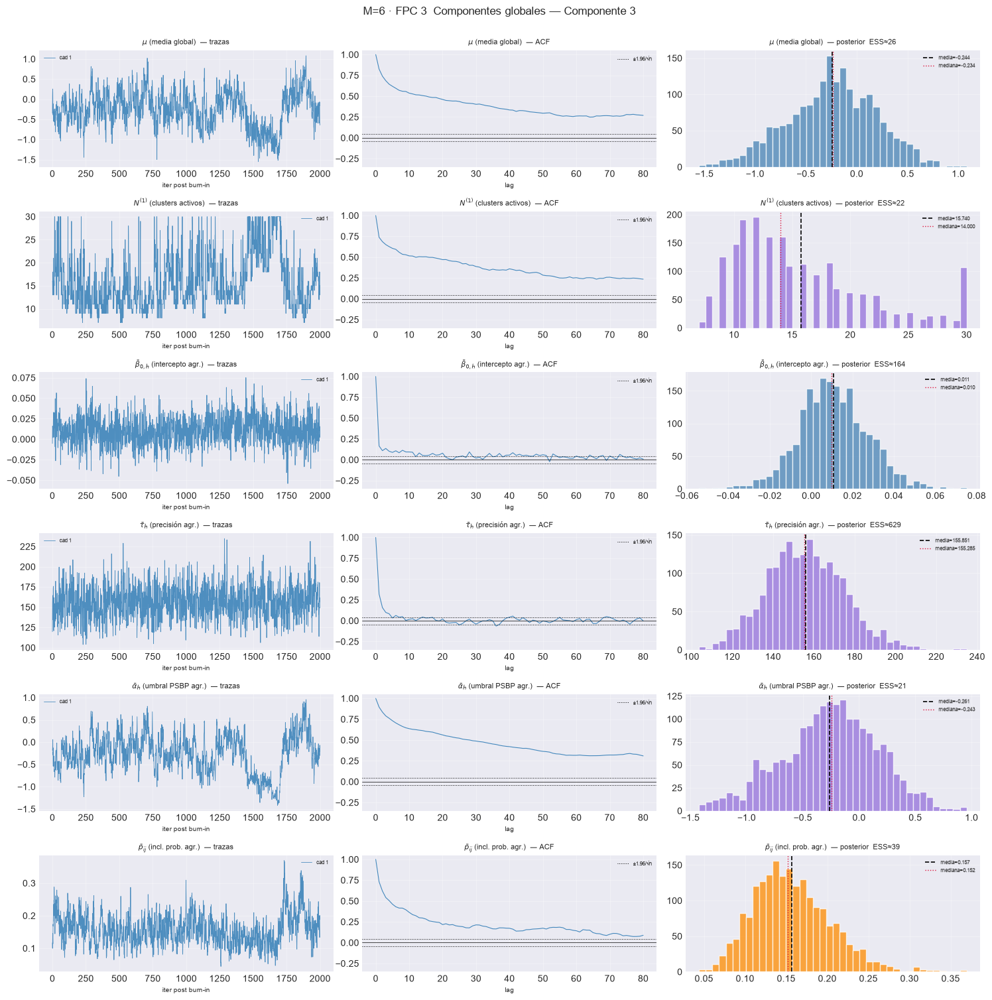

...

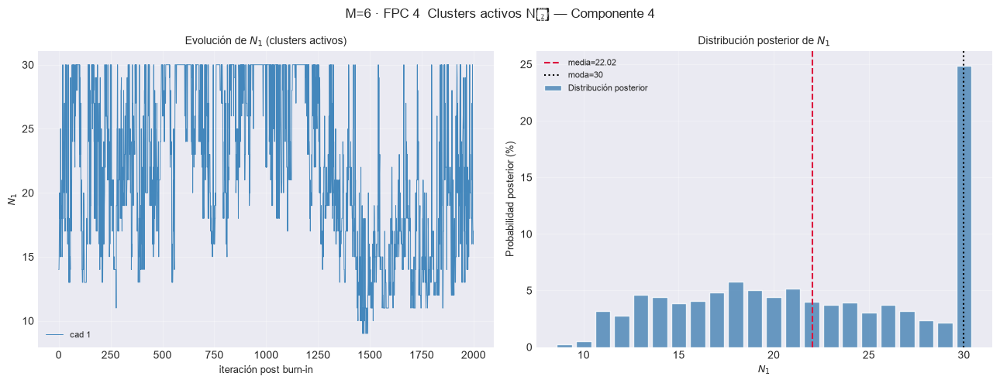

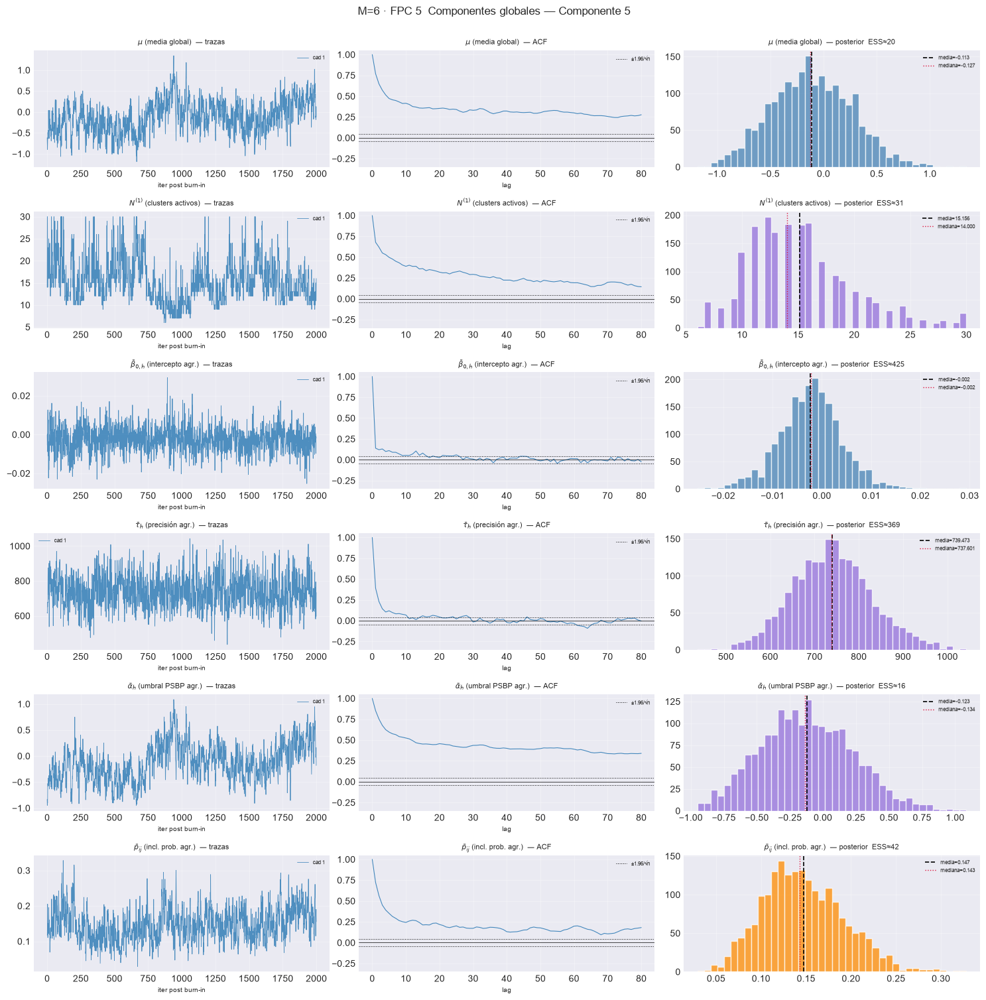

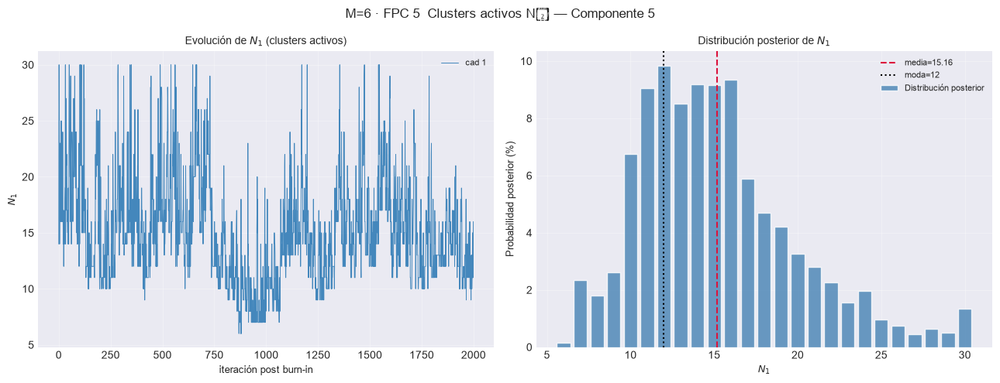

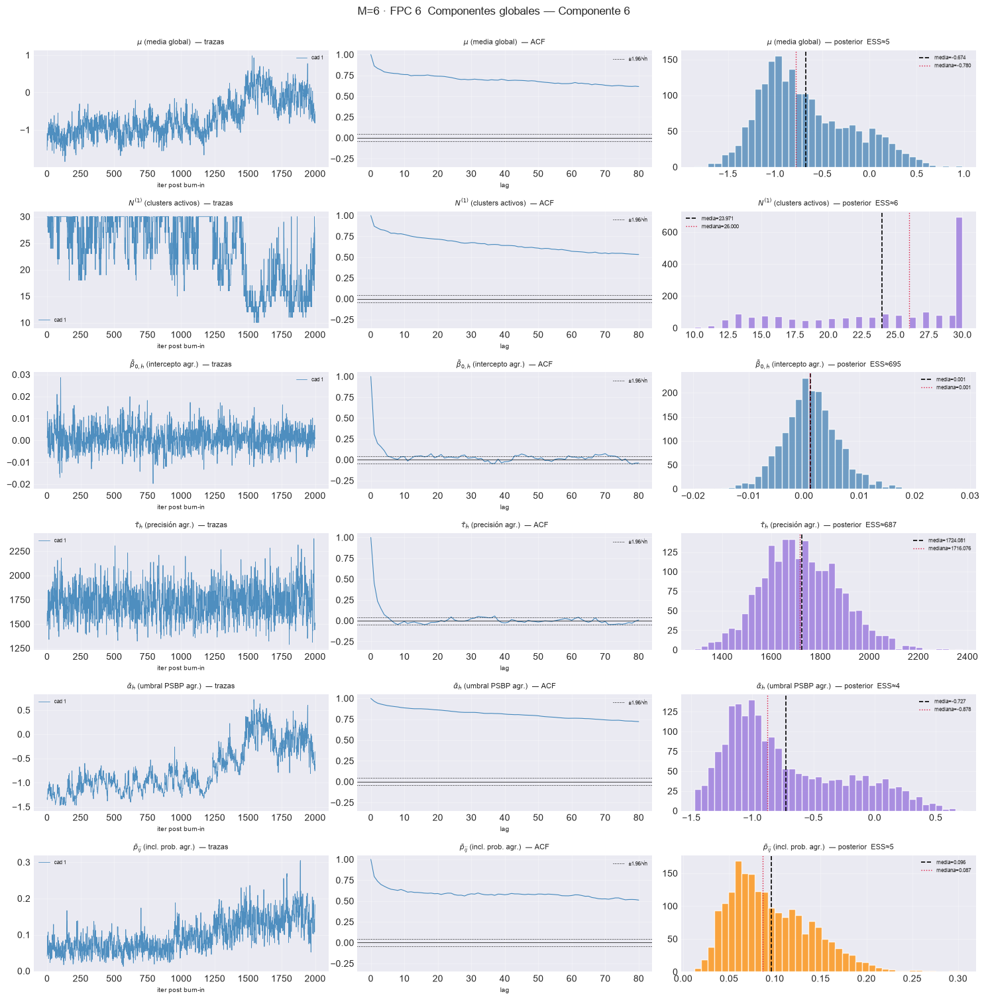

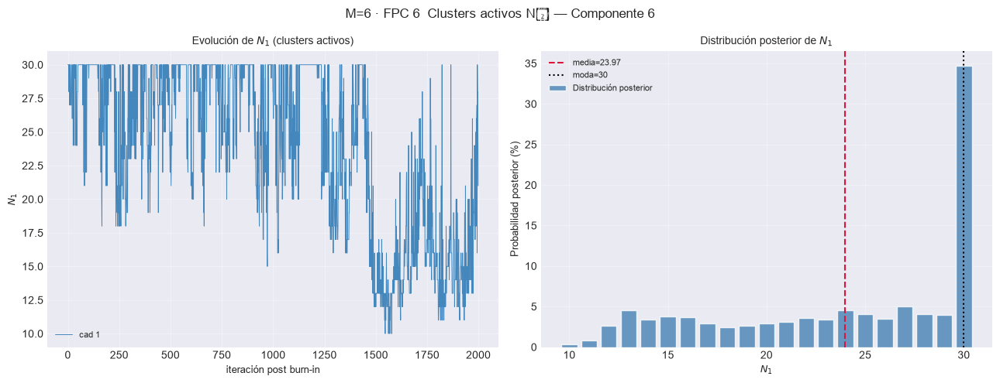

In [8]:
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc = e["component_idx"][k] + 1
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_global_components(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"42_global_k{fpc}.png"))
        plt.show()
        plot_active_clusters(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"43_clusters_k{fpc}.png"))
        plt.show()

== M=1 ==============================================
[plot_convergence_bj[FPC 1]] inicio (1 pasos)


  1/1 (100.0%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=1744  |G|=0.22  ✓


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_bj[FPC 1]] listo: 1 pasos en 0.4s  0/1 sin converger


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


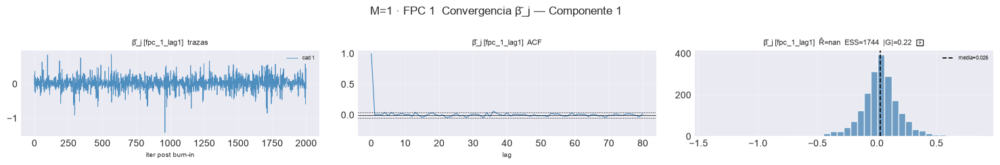

[plot_convergence_pj[FPC 1]] inicio (1 pasos)


  1/1 (100.0%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=302  |G|=1.75  ✓


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_pj[FPC 1]] listo: 1 pasos en 0.4s  0/1 sin converger


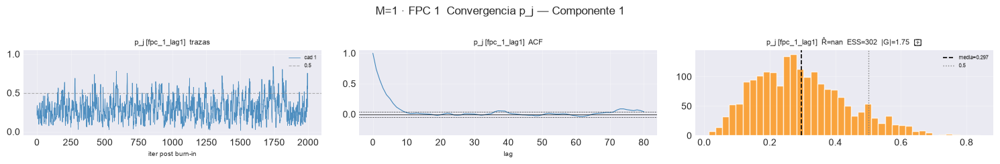

== M=2 ==============================================
[plot_convergence_bj[FPC 1]] inicio (2 pasos)


  1/2 (50.0%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=2000  |G|=0.44  ✓


  2/2 (100.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=1839  |G|=0.12  ✓


[plot_convergence_bj[FPC 1]] listo: 2 pasos en 0.7s  0/2 sin converger


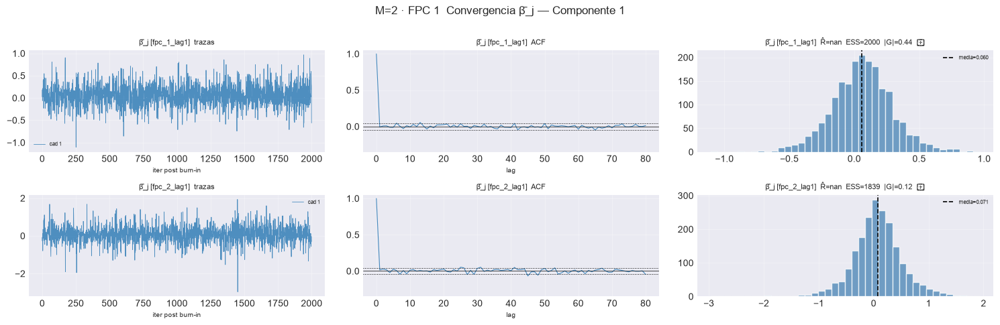

[plot_convergence_pj[FPC 1]] inicio (2 pasos)


  1/2 (50.0%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=55  |G|=4.00  ✗


  2/2 (100.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=287  |G|=2.20  ✗


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_pj[FPC 1]] listo: 2 pasos en 0.7s  2/2 sin converger


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


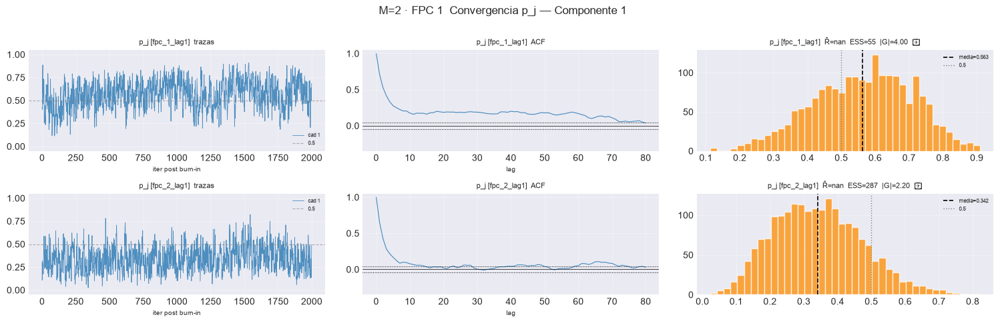

[plot_convergence_bj[FPC 2]] inicio (2 pasos)


  1/2 (50.0%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=1274  |G|=1.35  ✓


  2/2 (100.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=286  |G|=0.62  ✓


[plot_convergence_bj[FPC 2]] listo: 2 pasos en 1.0s  0/2 sin converger


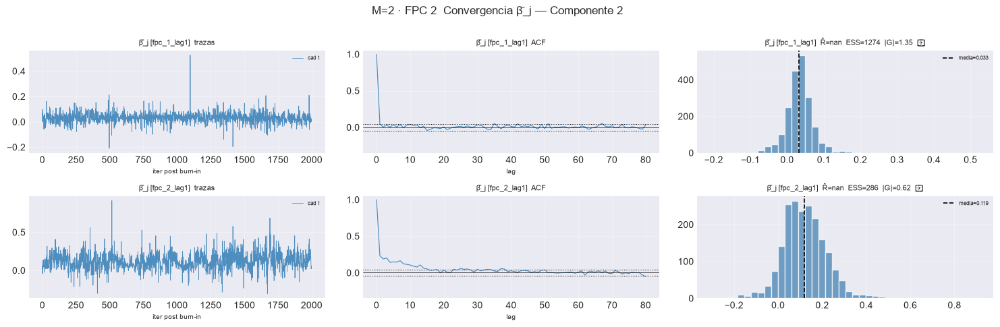

[plot_convergence_pj[FPC 2]] inicio (2 pasos)


  1/2 (50.0%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=222  |G|=0.43  ✓


  2/2 (100.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=32  |G|=0.11  ✗


[plot_convergence_pj[FPC 2]] listo: 2 pasos en 0.7s  1/2 sin converger


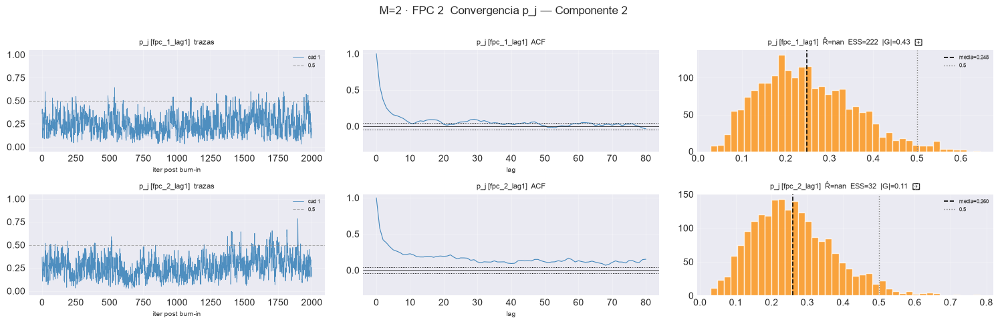

== M=3 ==============================================
[plot_convergence_bj[FPC 1]] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=1075  |G|=0.08  ✓


  2/3 (66.7%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=972  |G|=0.37  ✓


  3/3 (100.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=2000  |G|=0.42  ✓


[plot_convergence_bj[FPC 1]] listo: 3 pasos en 1.0s  0/3 sin converger


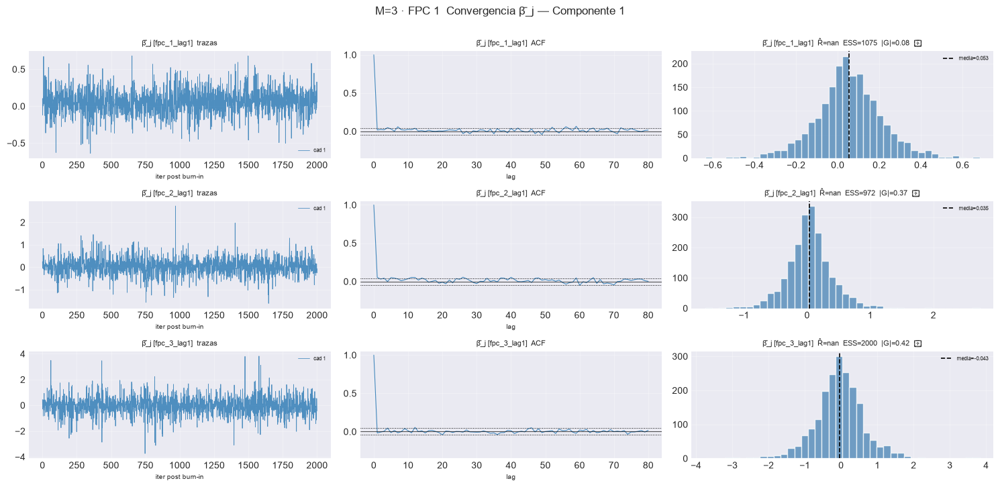

[plot_convergence_pj[FPC 1]] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=87  |G|=0.46  ✗


  2/3 (66.7%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=115  |G|=3.06  ✗


  3/3 (100.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=54  |G|=4.61  ✗


[plot_convergence_pj[FPC 1]] listo: 3 pasos en 1.0s  3/3 sin converger


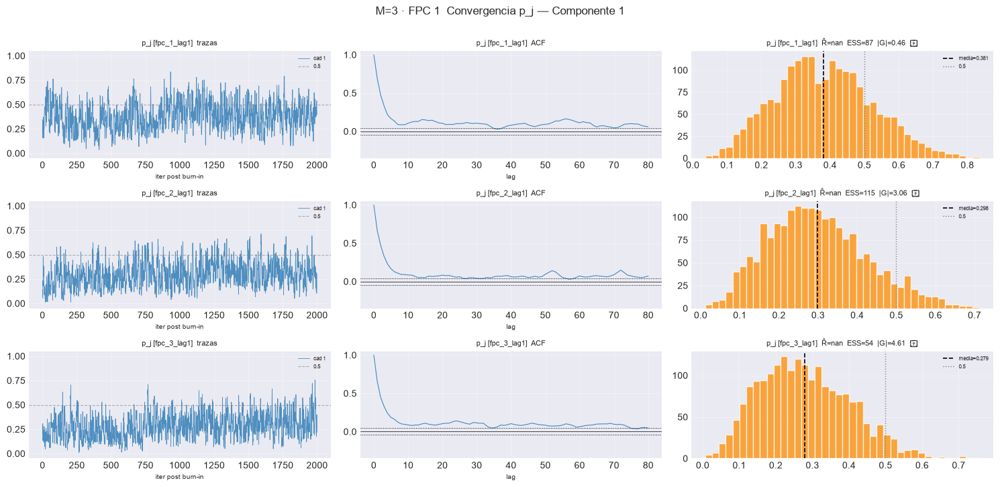

[plot_convergence_bj[FPC 2]] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=793  |G|=1.44  ✓


  2/3 (66.7%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=163  |G|=1.61  ✓


  3/3 (100.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=99  |G|=1.79  ✗


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_bj[FPC 2]] listo: 3 pasos en 0.9s  1/3 sin converger


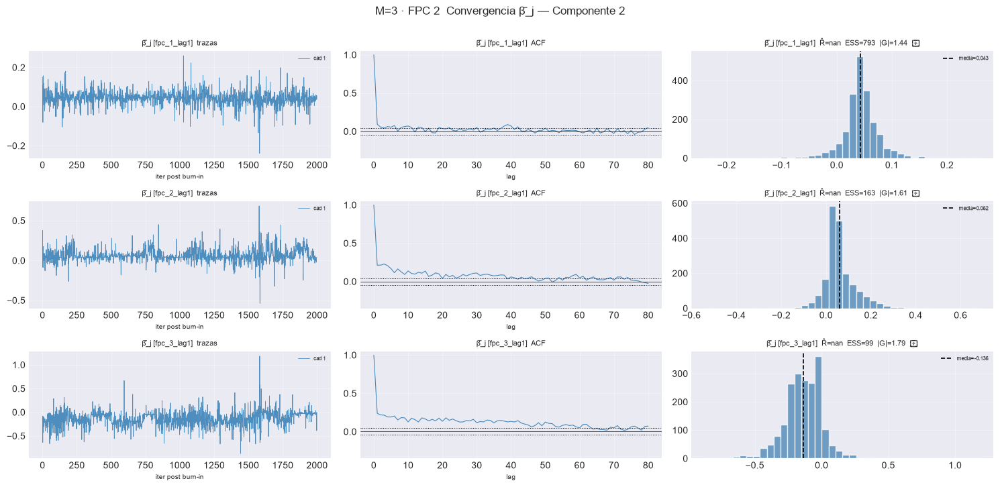

[plot_convergence_pj[FPC 2]] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=155  |G|=2.53  ✗


  2/3 (66.7%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=132  |G|=1.58  ✓


  3/3 (100.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=60  |G|=3.72  ✗


[plot_convergence_pj[FPC 2]] listo: 3 pasos en 1.0s  2/3 sin converger


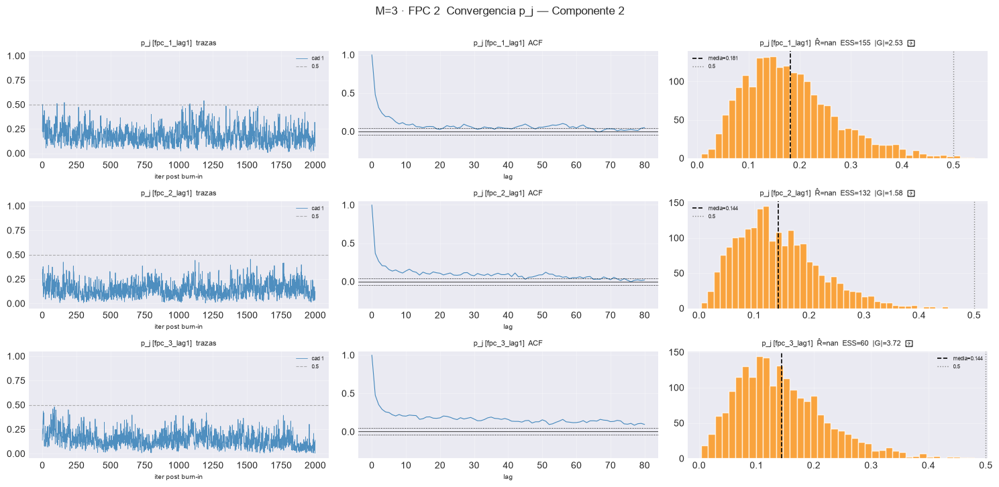

[plot_convergence_bj[FPC 3]] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=935  |G|=1.92  ✓


  2/3 (66.7%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=155  |G|=3.52  ✗


  3/3 (100.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=1831  |G|=1.04  ✓


[plot_convergence_bj[FPC 3]] listo: 3 pasos en 0.9s  1/3 sin converger


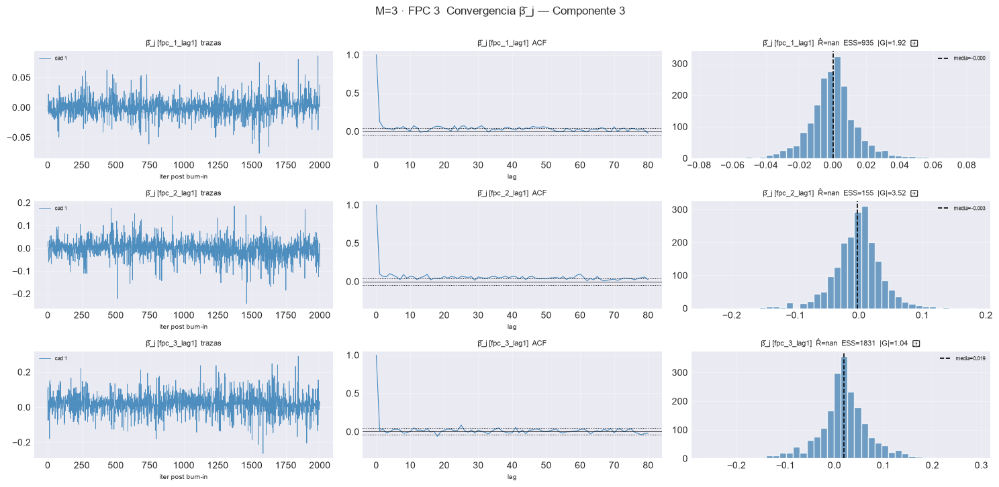

[plot_convergence_pj[FPC 3]] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  fpc_1_lag1  rhat=nan  ess_min=52  |G|=0.17  ✗


  2/3 (66.7%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=128  |G|=1.38  ✓


  3/3 (100.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=81  |G|=2.51  ✗


[plot_convergence_pj[FPC 3]] listo: 3 pasos en 1.0s  2/3 sin converger


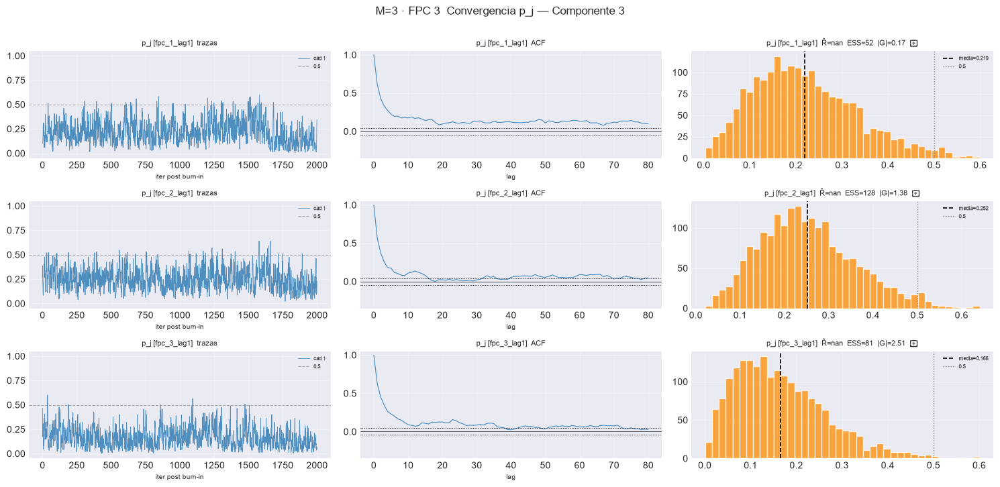

== M=4 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=2000  |G|=0.38  ✓


  2/4 (50.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=1.68  ✓


  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=1461  |G|=0.28  ✓


  4/4 (100.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=1755  |G|=1.36  ✓


[plot_convergence_bj[FPC 1]] listo: 4 pasos en 1.2s  0/4 sin converger


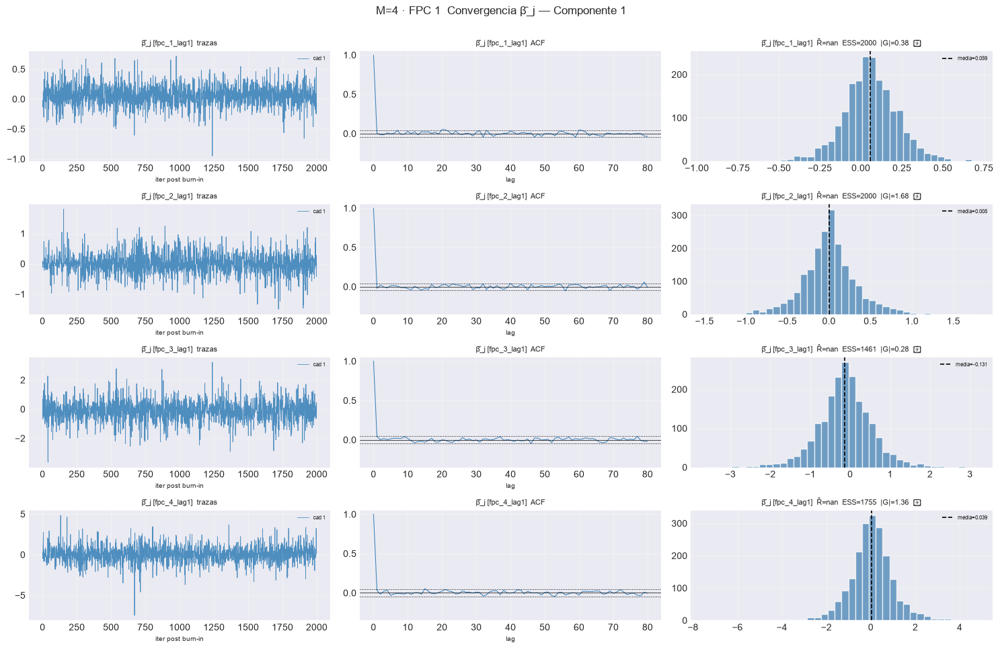

[plot_convergence_pj[FPC 1]] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=353  |G|=0.23  ✓


  2/4 (50.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=15  |G|=11.69  ✗


  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=128  |G|=0.96  ✓


  4/4 (100.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=426  |G|=0.07  ✓


[plot_convergence_pj[FPC 1]] listo: 4 pasos en 1.3s  1/4 sin converger


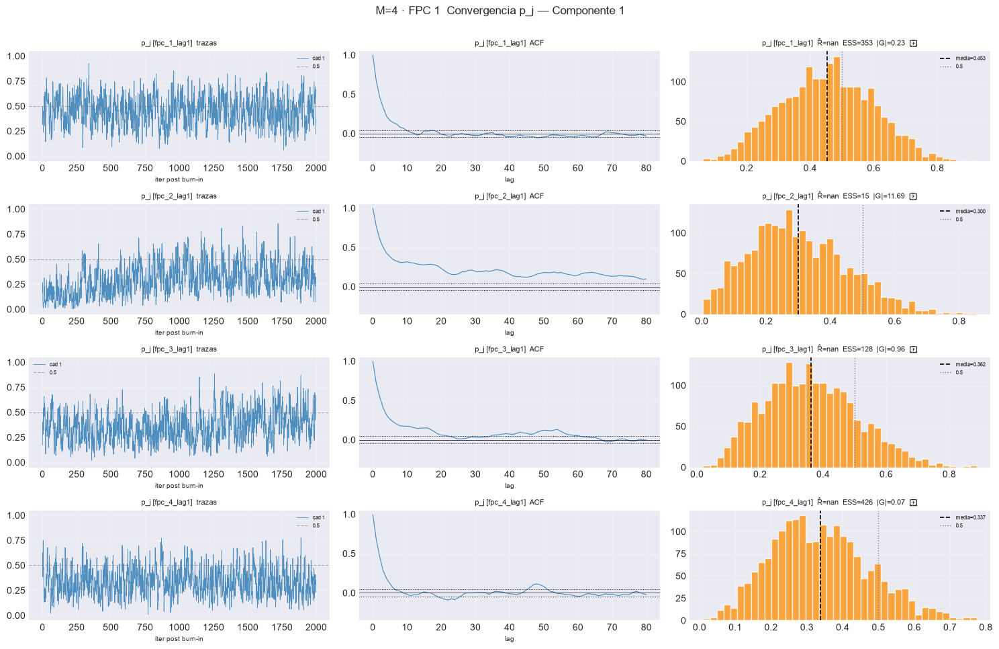

[plot_convergence_bj[FPC 2]] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=1442  |G|=1.68  ✓


  2/4 (50.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=499  |G|=2.88  ✗


  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=1081  |G|=0.48  ✓


  4/4 (100.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=1257  |G|=0.39  ✓


[plot_convergence_bj[FPC 2]] listo: 4 pasos en 1.2s  1/4 sin converger


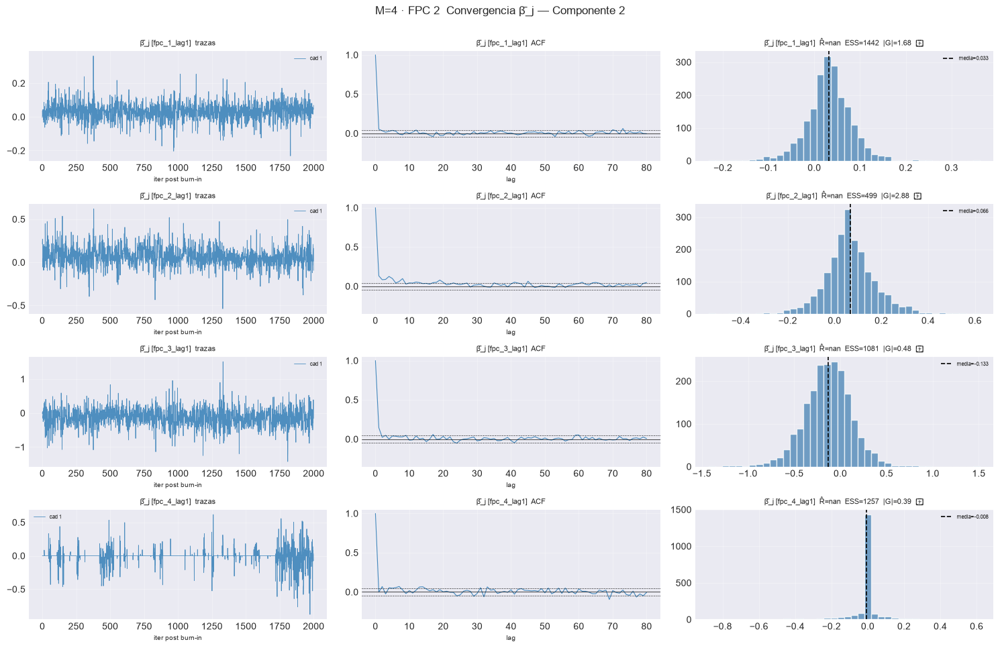

[plot_convergence_pj[FPC 2]] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=136  |G|=0.68  ✓


  2/4 (50.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=134  |G|=2.75  ✗


  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=66  |G|=0.56  ✗


  4/4 (100.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=22  |G|=0.30  ✗


[plot_convergence_pj[FPC 2]] listo: 4 pasos en 1.3s  3/4 sin converger


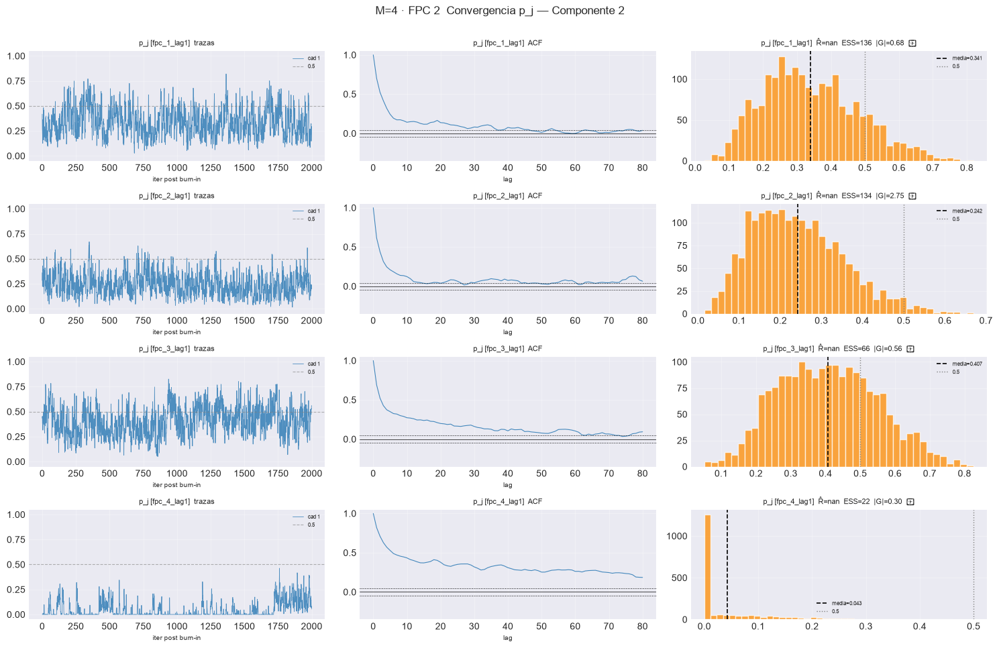

[plot_convergence_bj[FPC 3]] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=1380  |G|=1.57  ✓


  2/4 (50.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=310  |G|=5.97  ✗


  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=1987  |G|=0.16  ✓


  4/4 (100.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=1564  |G|=0.42  ✓


[plot_convergence_bj[FPC 3]] listo: 4 pasos en 1.3s  1/4 sin converger


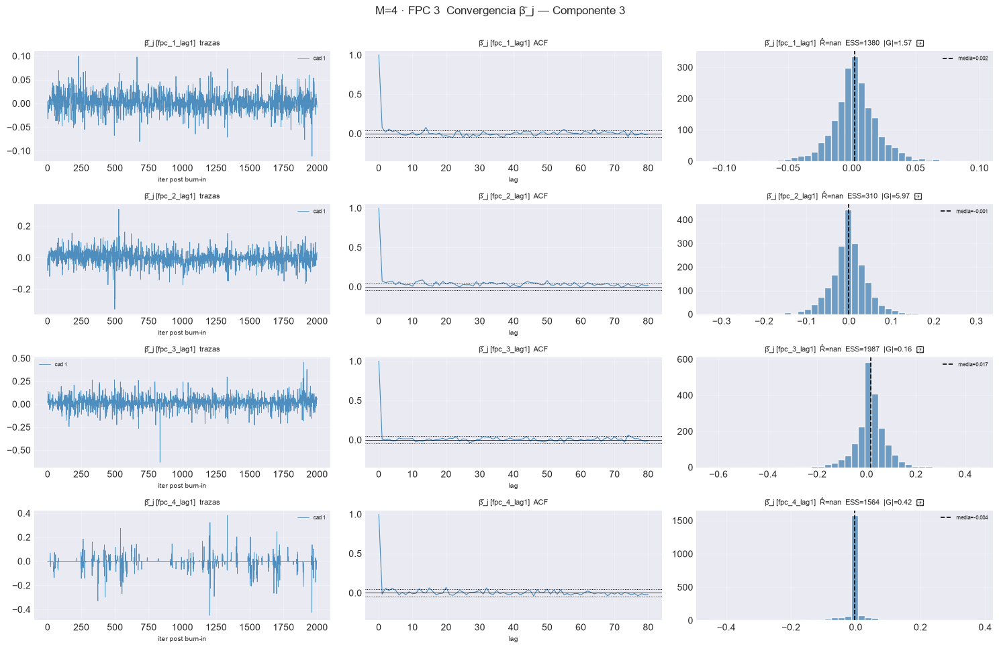

[plot_convergence_pj[FPC 3]] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=92  |G|=4.55  ✗


  2/4 (50.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=47  |G|=3.43  ✗


  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=248  |G|=0.49  ✓


  4/4 (100.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=150  |G|=1.72  ✓


[plot_convergence_pj[FPC 3]] listo: 4 pasos en 1.2s  2/4 sin converger


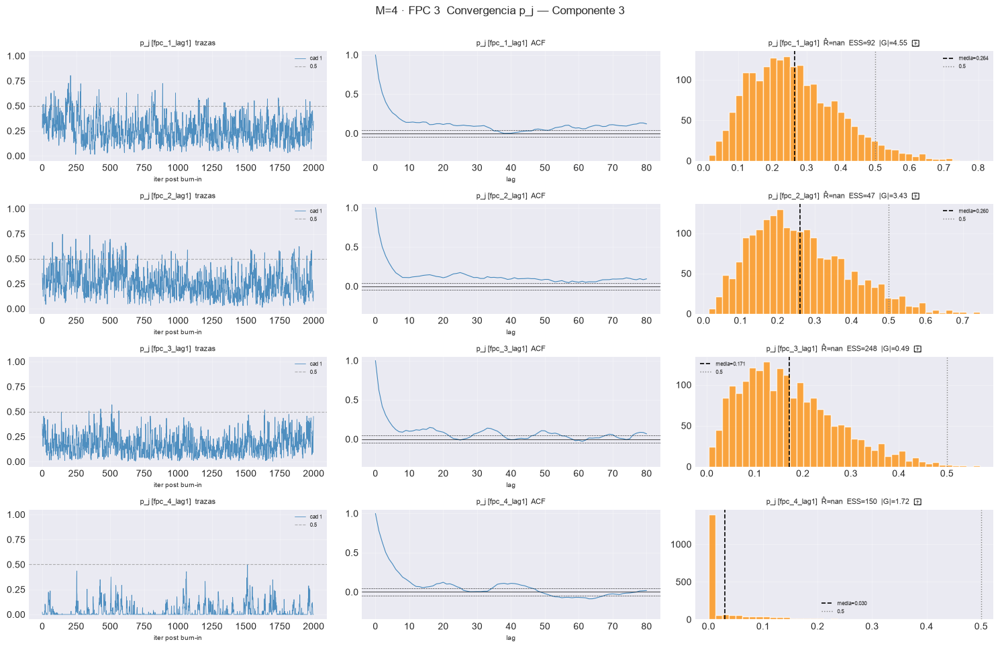

[plot_convergence_bj[FPC 4]] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=1749  |G|=0.83  ✓


  2/4 (50.0%) t=0.0s eta=0.0s  fpc_2_lag1  rhat=nan  ess_min=65  |G|=1.90  ✗


  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=110  |G|=0.26  ✓


  4/4 (100.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=265  |G|=7.05  ✗


[plot_convergence_bj[FPC 4]] listo: 4 pasos en 1.2s  2/4 sin converger


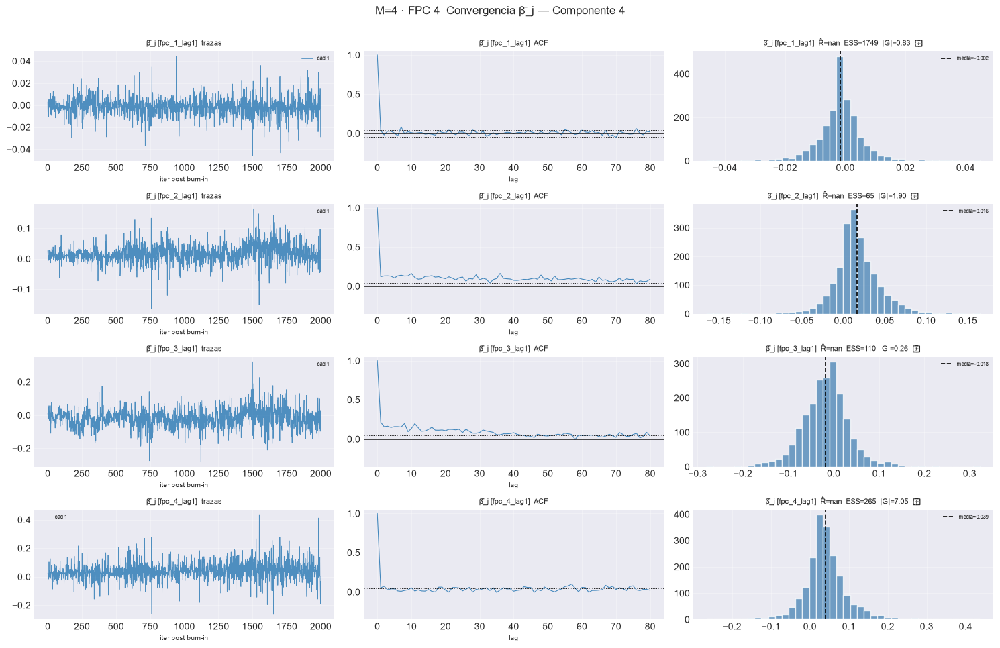

[plot_convergence_pj[FPC 4]] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=252  |G|=1.13  ✓


  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=33  |G|=5.24  ✗


  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=18  |G|=6.94  ✗


  4/4 (100.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=23  |G|=6.27  ✗


[plot_convergence_pj[FPC 4]] listo: 4 pasos en 1.3s  3/4 sin converger


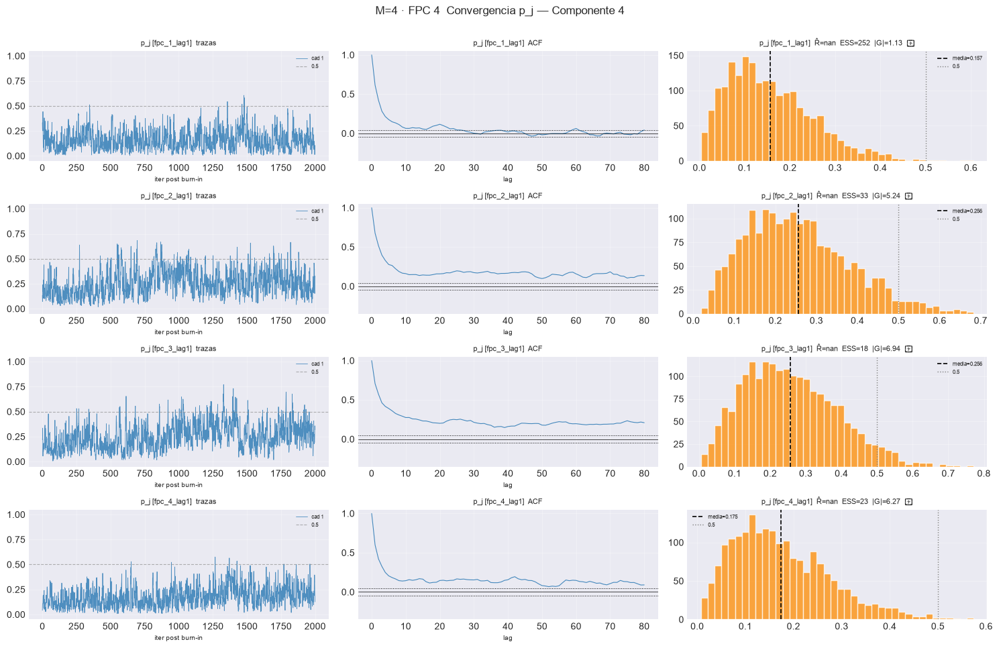

== M=5 ==============================================
[plot_convergence_bj[FPC 1]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=1757  |G|=1.21  ✓


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=1.07  ✓


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=1627  |G|=1.64  ✓


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.33  ✓


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=1599  |G|=0.96  ✓


[plot_convergence_bj[FPC 1]] listo: 5 pasos en 1.5s  0/5 sin converger


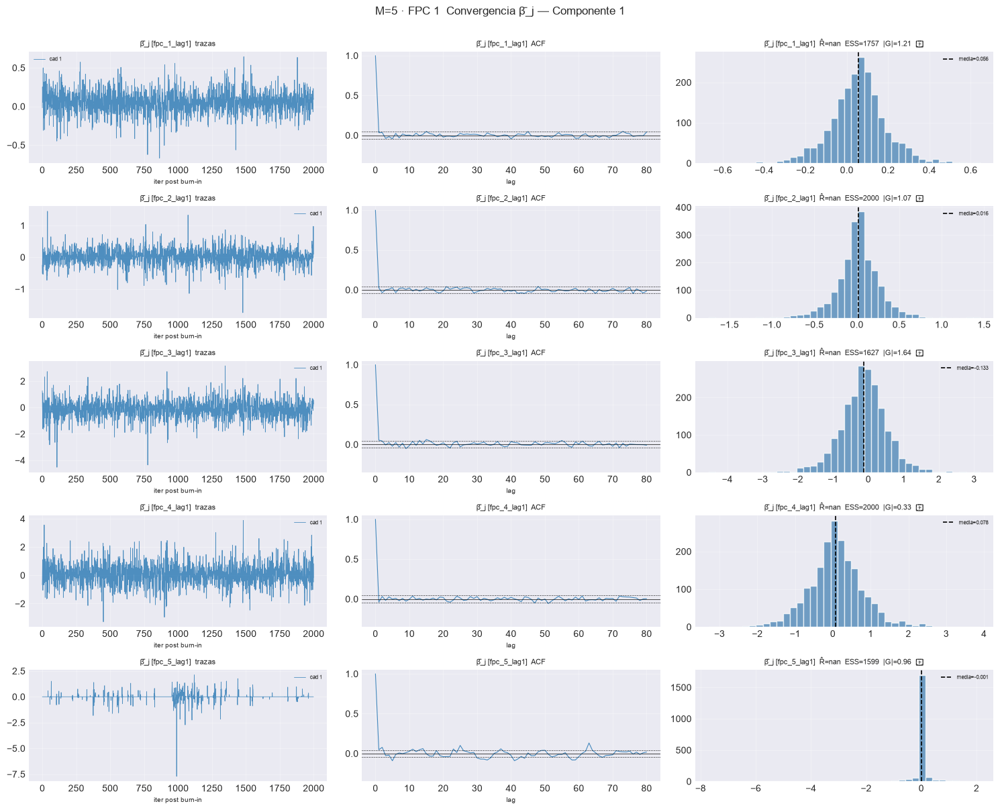

[plot_convergence_pj[FPC 1]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=56  |G|=6.23  ✗


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=80  |G|=2.19  ✗


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=193  |G|=3.46  ✗


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=342  |G|=0.36  ✓


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=42  |G|=1.24  ✗


[plot_convergence_pj[FPC 1]] listo: 5 pasos en 1.9s  4/5 sin converger


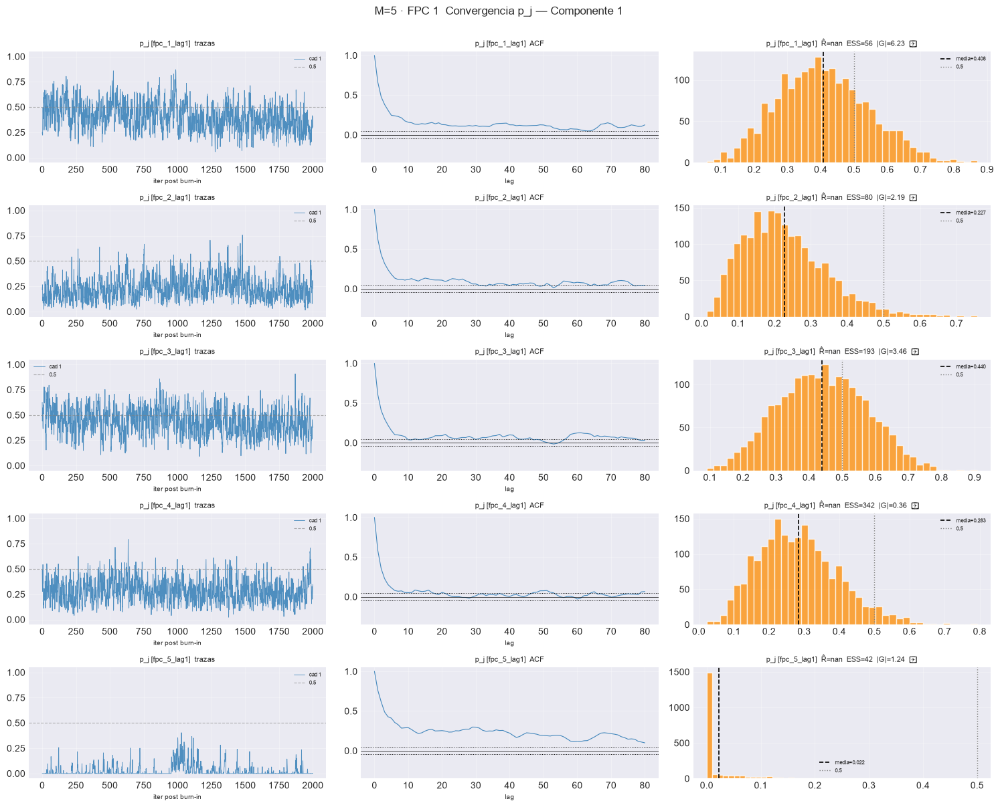

[plot_convergence_bj[FPC 2]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=1865  |G|=2.41  ✗


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=907  |G|=1.45  ✓


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=667  |G|=1.74  ✓


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.16  ✓


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=1016  |G|=0.53  ✓


[plot_convergence_bj[FPC 2]] listo: 5 pasos en 1.6s  1/5 sin converger


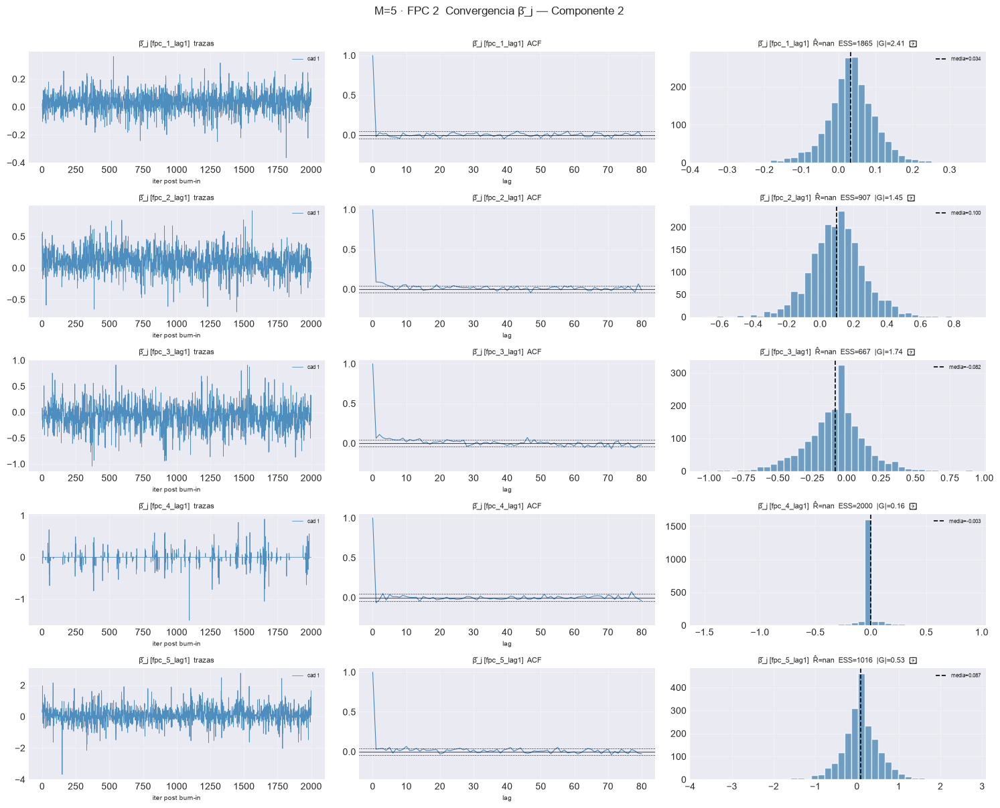

[plot_convergence_pj[FPC 2]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=313  |G|=1.21  ✓


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=335  |G|=1.01  ✓


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=335  |G|=0.45  ✓


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=202  |G|=2.45  ✗


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=429  |G|=1.41  ✓


[plot_convergence_pj[FPC 2]] listo: 5 pasos en 1.6s  1/5 sin converger


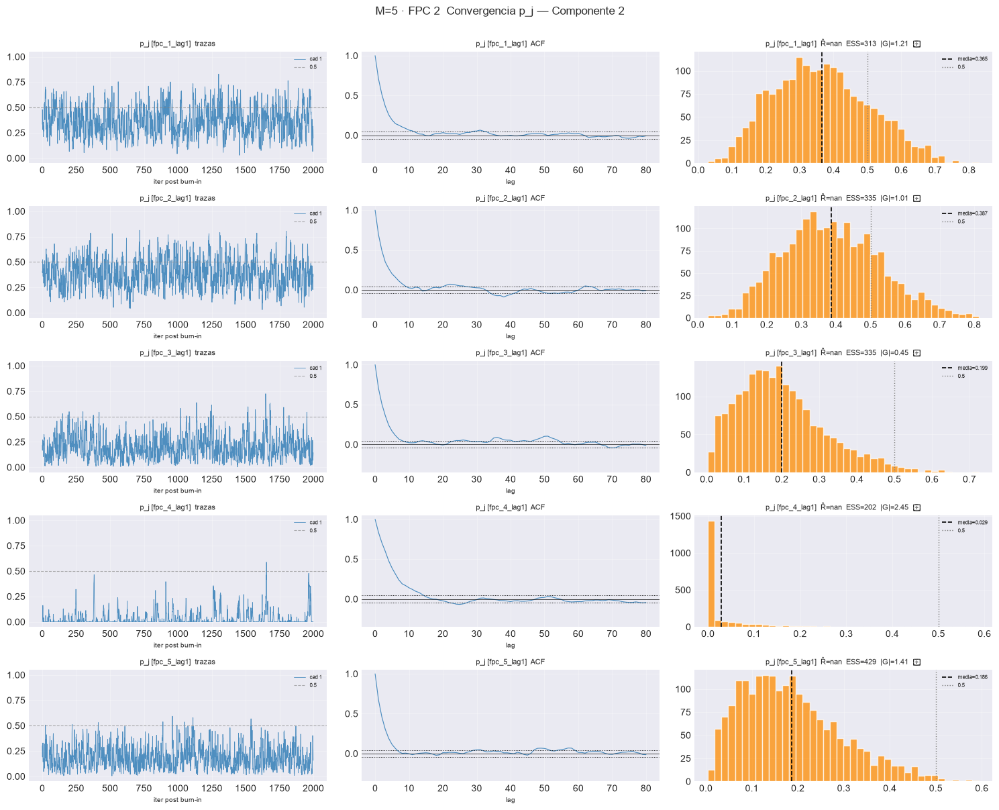

[plot_convergence_bj[FPC 3]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=55  |G|=9.97  ✗


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=1138  |G|=4.38  ✗


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=970  |G|=1.66  ✓


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.45  ✓


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=1902  |G|=0.40  ✓


[plot_convergence_bj[FPC 3]] listo: 5 pasos en 1.6s  2/5 sin converger


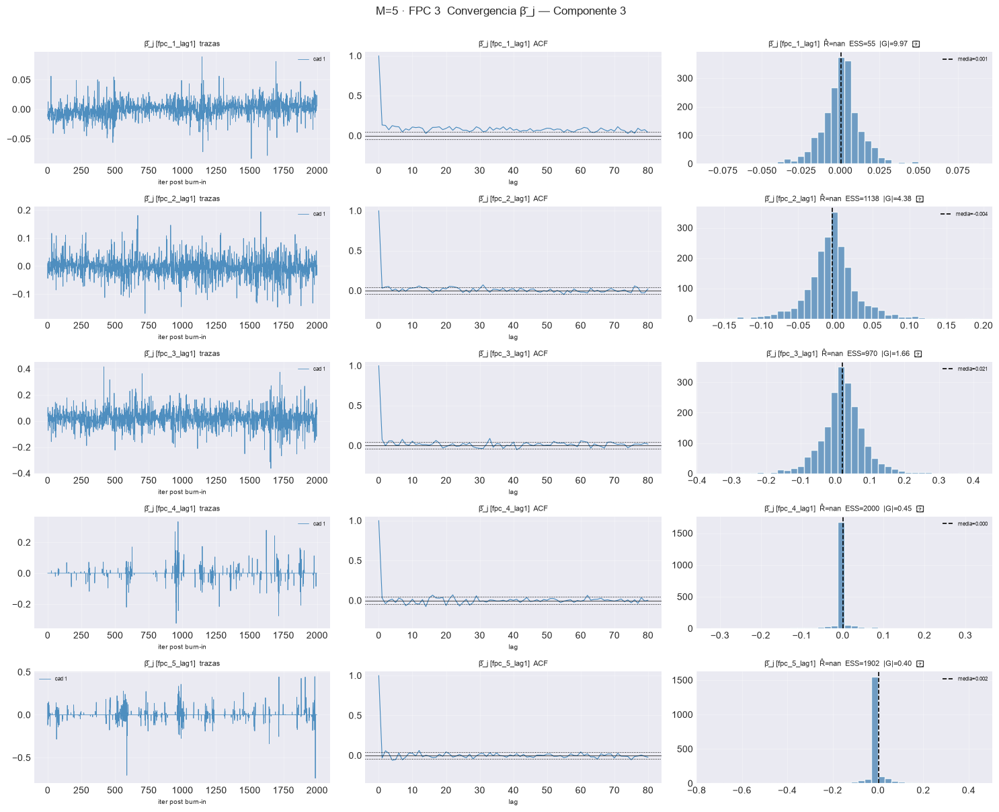

[plot_convergence_pj[FPC 3]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=28  |G|=3.02  ✗


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=282  |G|=0.16  ✓


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=75  |G|=3.42  ✗


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=171  |G|=3.10  ✗


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=110  |G|=0.74  ✓


[plot_convergence_pj[FPC 3]] listo: 5 pasos en 1.6s  3/5 sin converger


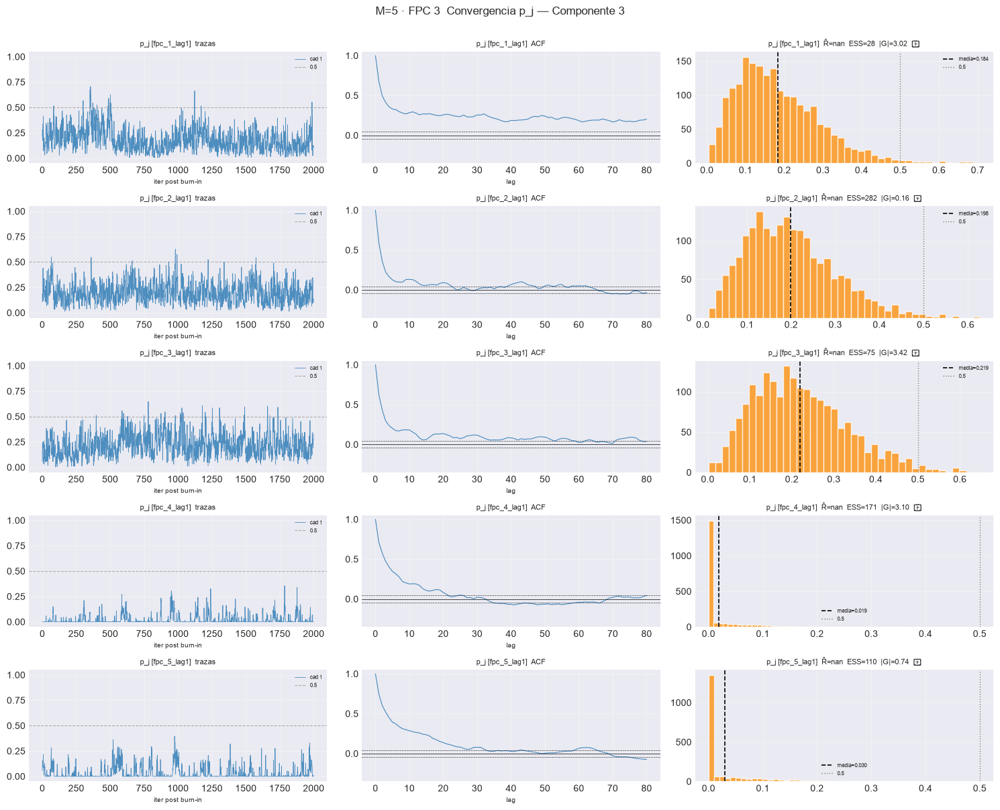

[plot_convergence_bj[FPC 4]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=995  |G|=4.63  ✗


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=14  |G|=14.80  ✗


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=432  |G|=0.26  ✓


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=535  |G|=1.46  ✓


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=1890  |G|=1.30  ✓


[plot_convergence_bj[FPC 4]] listo: 5 pasos en 1.6s  2/5 sin converger


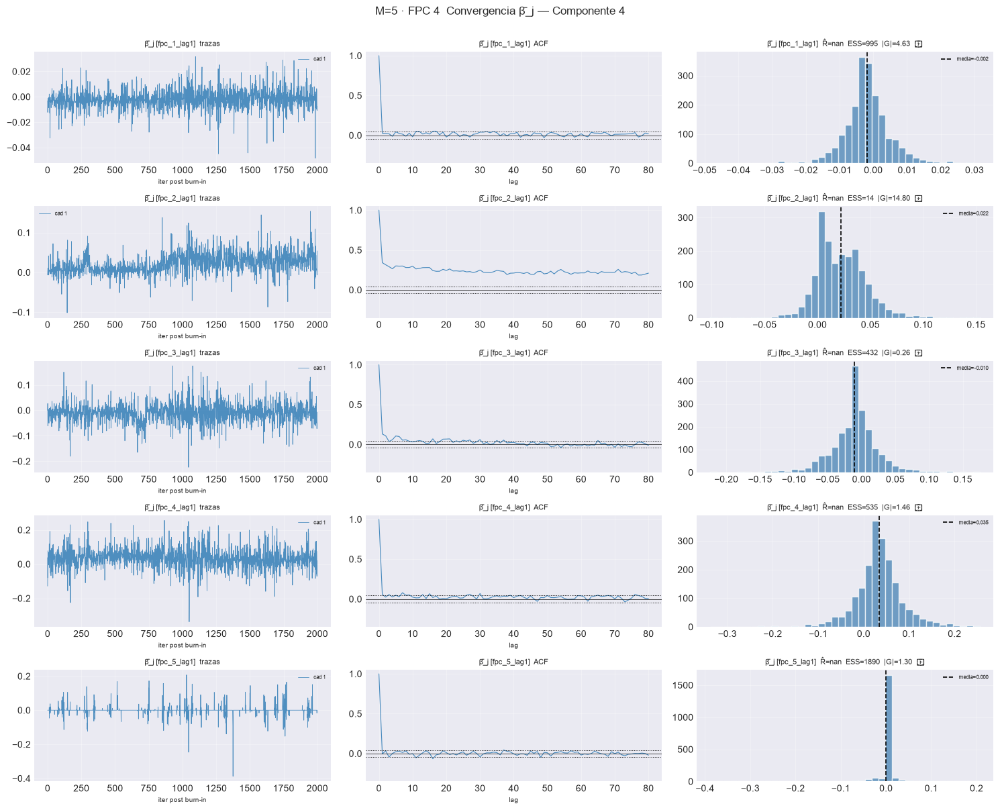

[plot_convergence_pj[FPC 4]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=310  |G|=1.13  ✓


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=39  |G|=6.39  ✗


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=179  |G|=0.61  ✓


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=39  |G|=5.20  ✗


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=229  |G|=0.11  ✓


[plot_convergence_pj[FPC 4]] listo: 5 pasos en 1.6s  2/5 sin converger


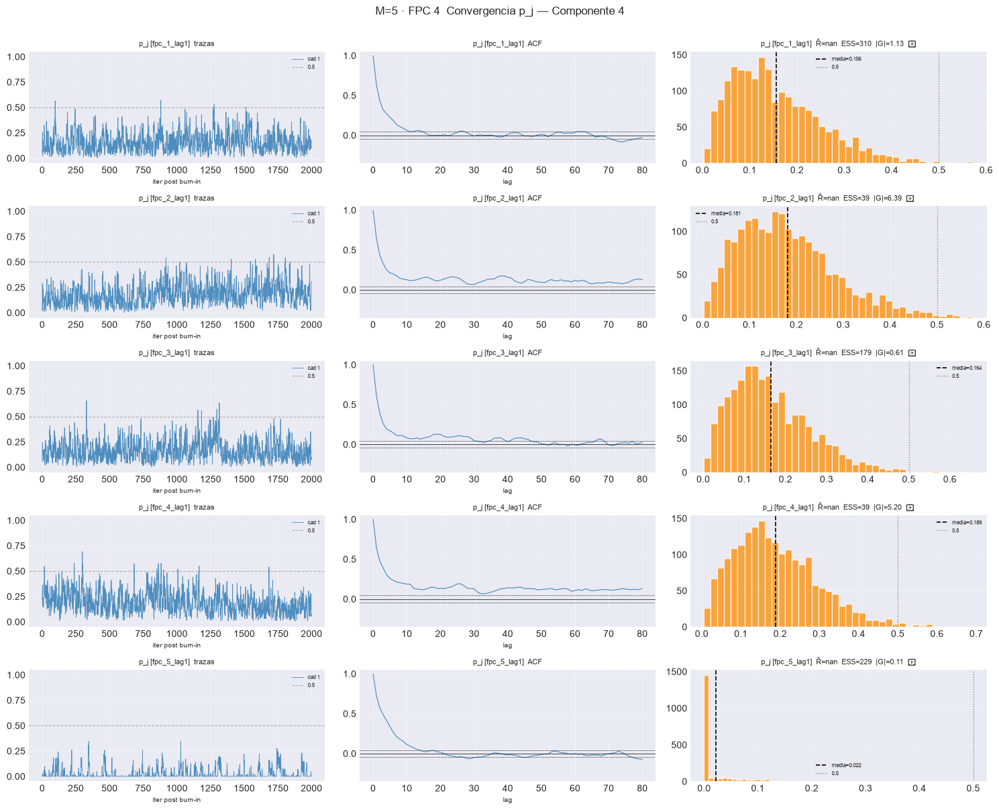

[plot_convergence_bj[FPC 5]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=1439  |G|=0.52  ✓


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=1620  |G|=0.82  ✓


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=1340  |G|=0.16  ✓


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=663  |G|=0.76  ✓


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=677  |G|=0.78  ✓


[plot_convergence_bj[FPC 5]] listo: 5 pasos en 1.5s  0/5 sin converger


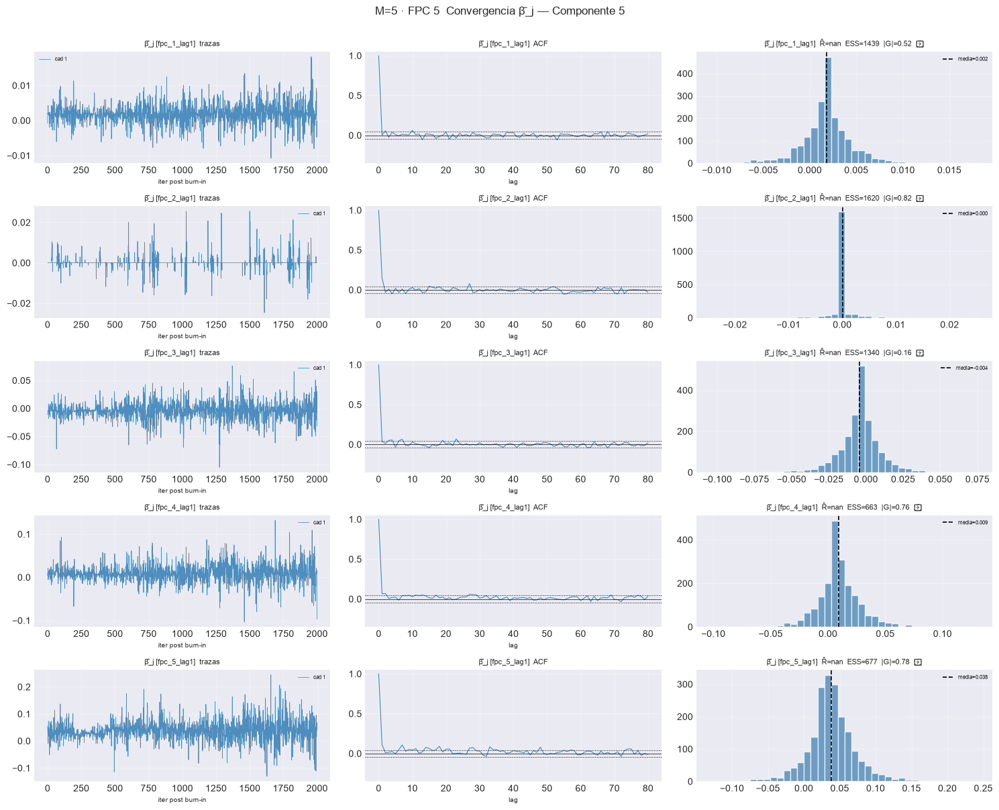

[plot_convergence_pj[FPC 5]] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=48  |G|=2.69  ✗


  2/5 (40.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=210  |G|=0.60  ✓


  3/5 (60.0%) t=0.1s eta=0.0s  fpc_3_lag1  rhat=nan  ess_min=28  |G|=4.80  ✗


  4/5 (80.0%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=21  |G|=4.45  ✗


  5/5 (100.0%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=10  |G|=3.57  ✗


[plot_convergence_pj[FPC 5]] listo: 5 pasos en 1.6s  4/5 sin converger


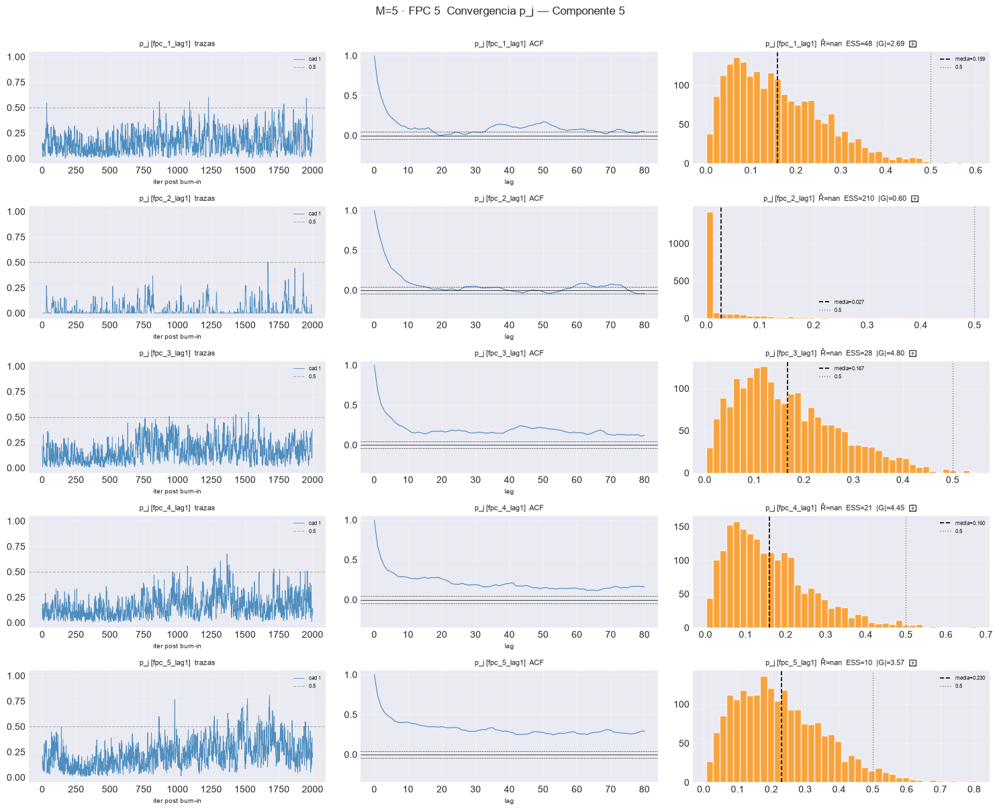

== M=6 ==============================================
[plot_convergence_bj[FPC 1]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=1439  |G|=1.01  ✓


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=0.11  ✓


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1762  |G|=1.83  ✓


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=1965  |G|=1.70  ✓


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=1548  |G|=2.03  ✗


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=0.84  ✓


[plot_convergence_bj[FPC 1]] listo: 6 pasos en 1.9s  1/6 sin converger


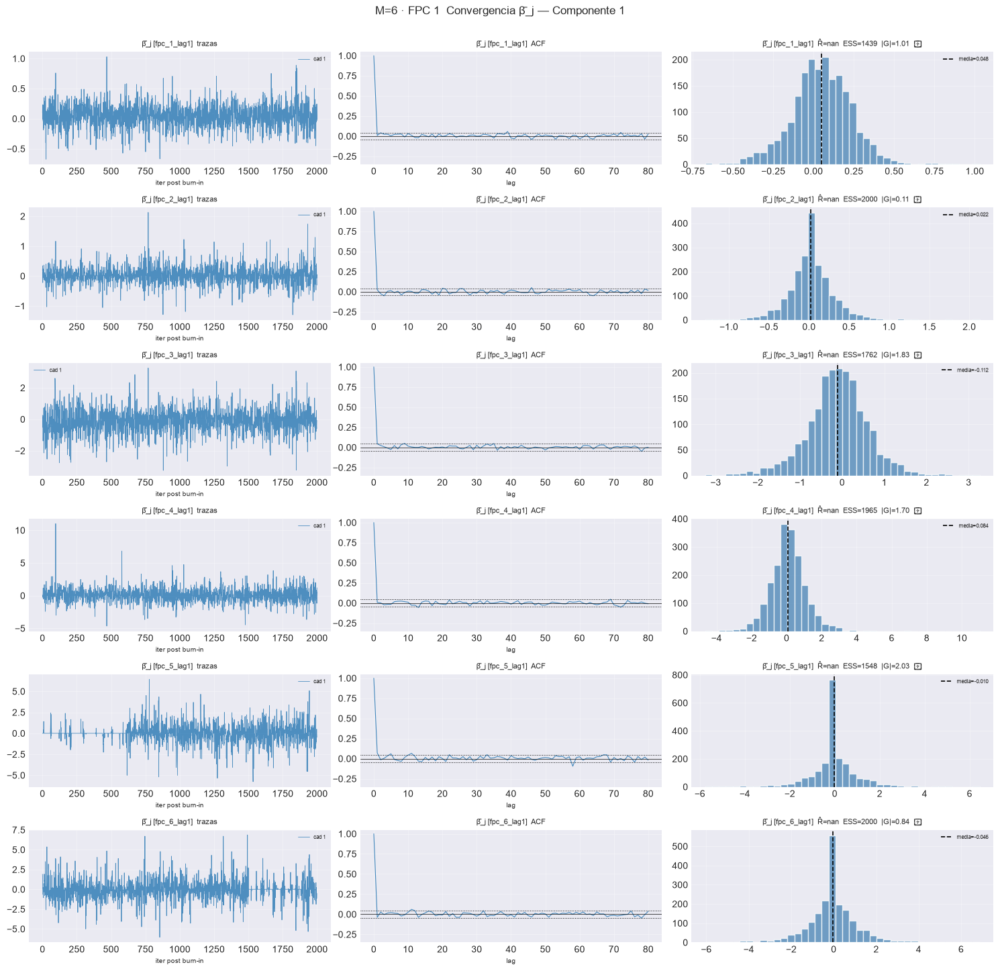

[plot_convergence_pj[FPC 1]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=294  |G|=0.44  ✓


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=111  |G|=1.33  ✓


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=22  |G|=6.76  ✗


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=31  |G|=2.91  ✗


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=8  |G|=11.33  ✗


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=40  |G|=1.72  ✗


[plot_convergence_pj[FPC 1]] listo: 6 pasos en 2.0s  4/6 sin converger


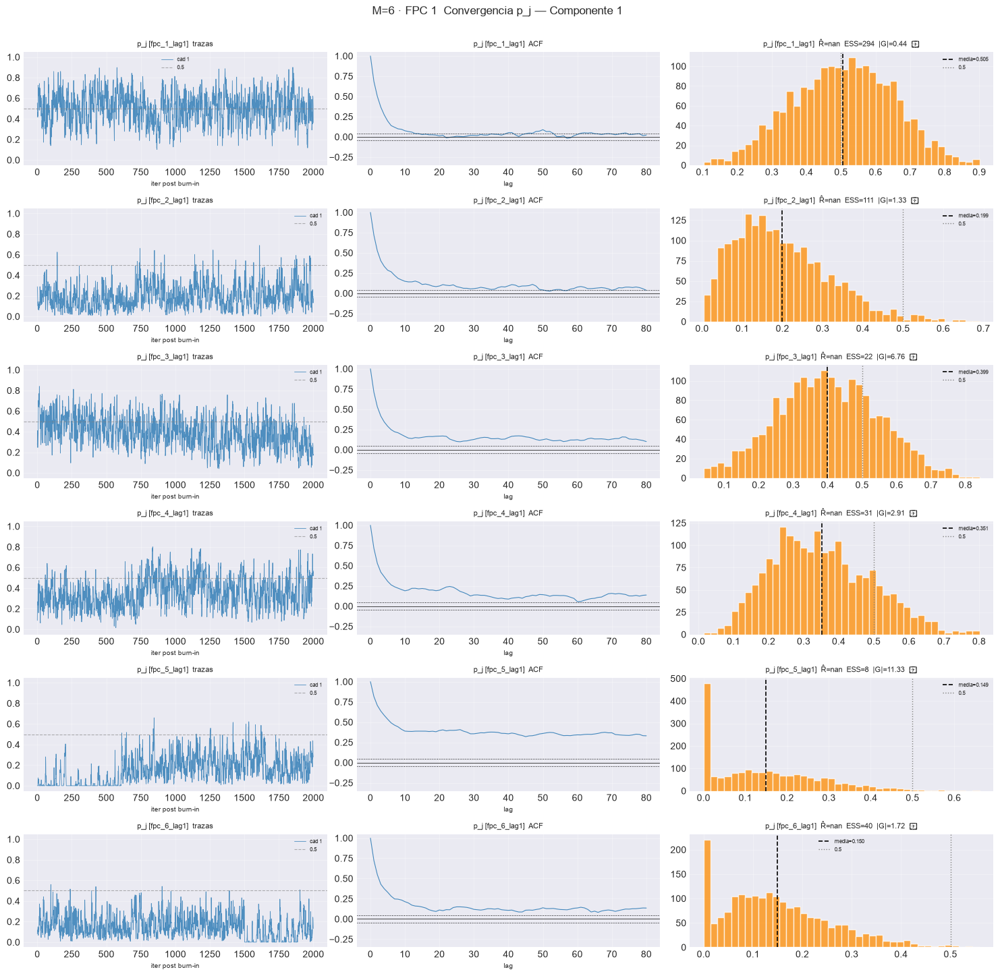

[plot_convergence_bj[FPC 2]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=1662  |G|=0.76  ✓


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=868  |G|=3.24  ✗


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=785  |G|=1.69  ✓


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=1149  |G|=1.02  ✓


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=1442  |G|=2.31  ✗


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=1348  |G|=0.83  ✓


[plot_convergence_bj[FPC 2]] listo: 6 pasos en 1.9s  2/6 sin converger


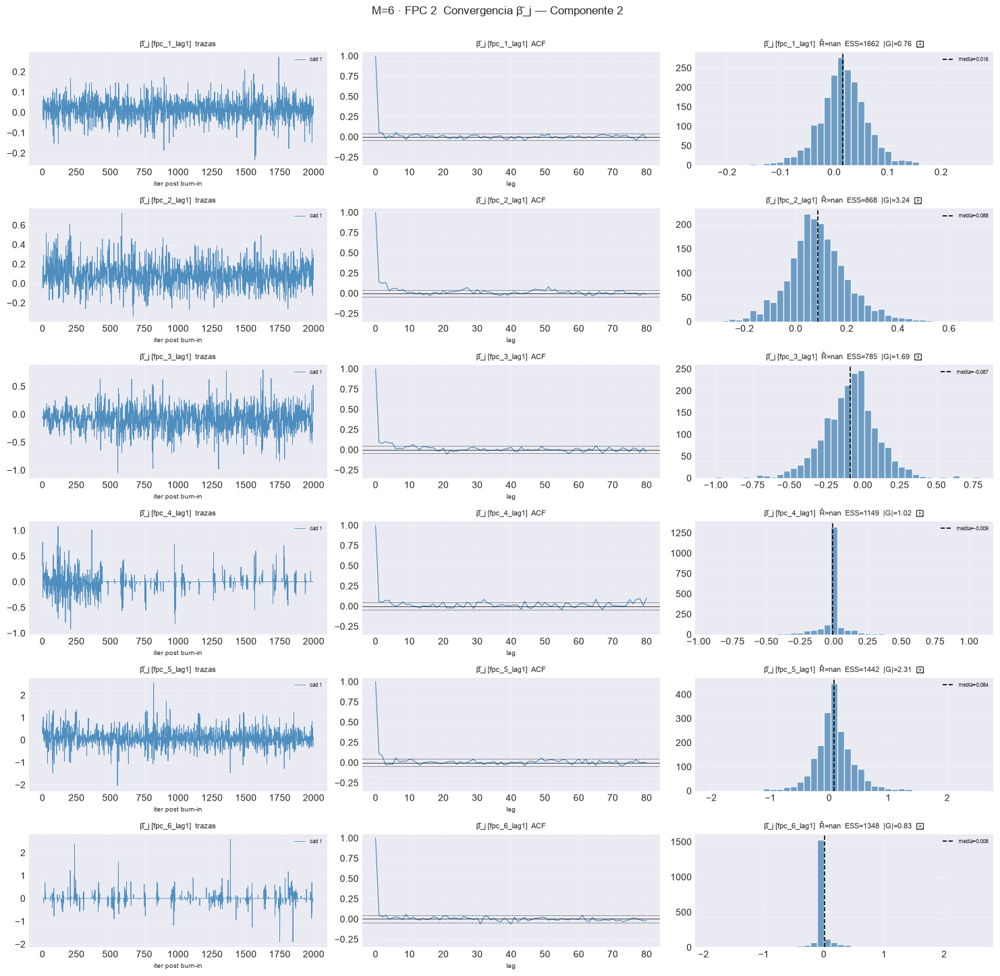

[plot_convergence_pj[FPC 2]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=65  |G|=0.02  ✗


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=151  |G|=3.48  ✗


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=57  |G|=5.26  ✗


  4/6 (66.7%) t=0.4s eta=0.2s  fpc_4_lag1  rhat=nan  ess_min=10  |G|=11.21  ✗


  5/6 (83.3%) t=0.4s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=257  |G|=2.33  ✗


  6/6 (100.0%) t=0.4s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=186  |G|=0.21  ✓


[plot_convergence_pj[FPC 2]] listo: 6 pasos en 2.3s  5/6 sin converger


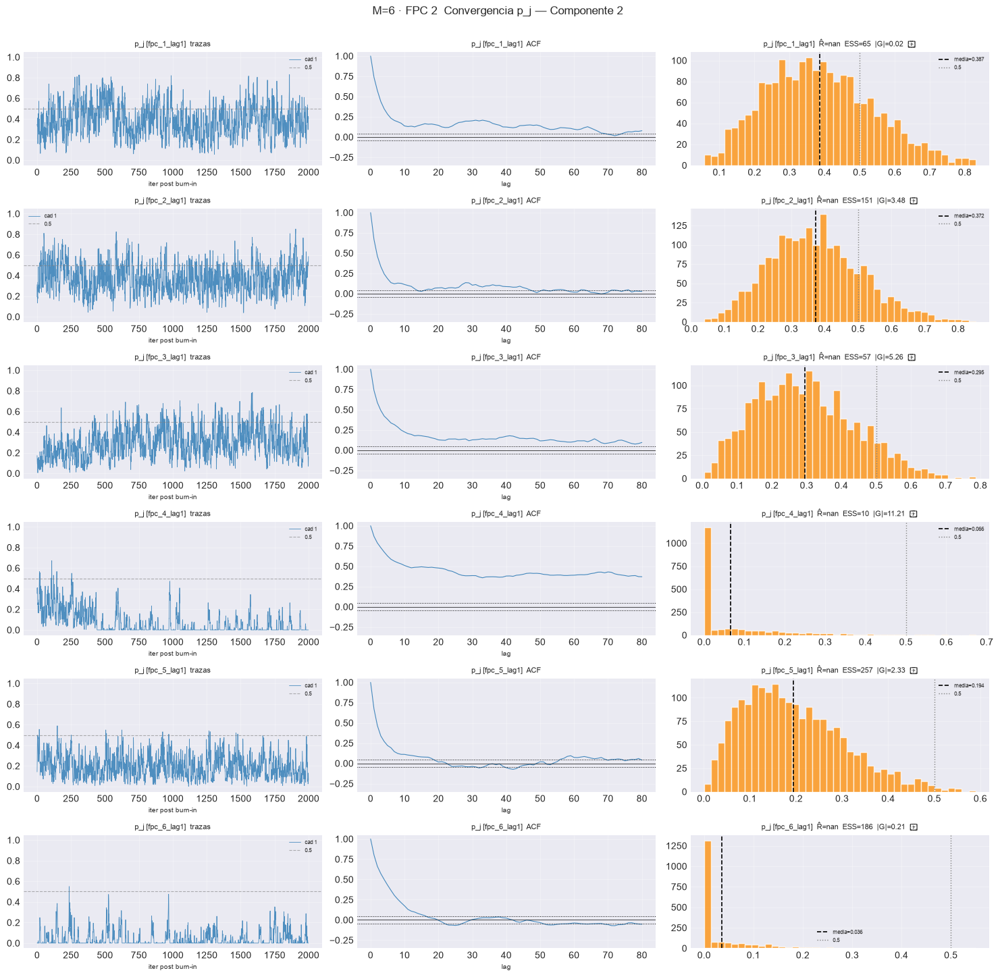

[plot_convergence_bj[FPC 3]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=172  |G|=0.24  ✓


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=1165  |G|=0.74  ✓


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1328  |G|=0.60  ✓


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=1165  |G|=0.91  ✓


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=0.21  ✓


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=1617  |G|=0.40  ✓


[plot_convergence_bj[FPC 3]] listo: 6 pasos en 1.9s  0/6 sin converger


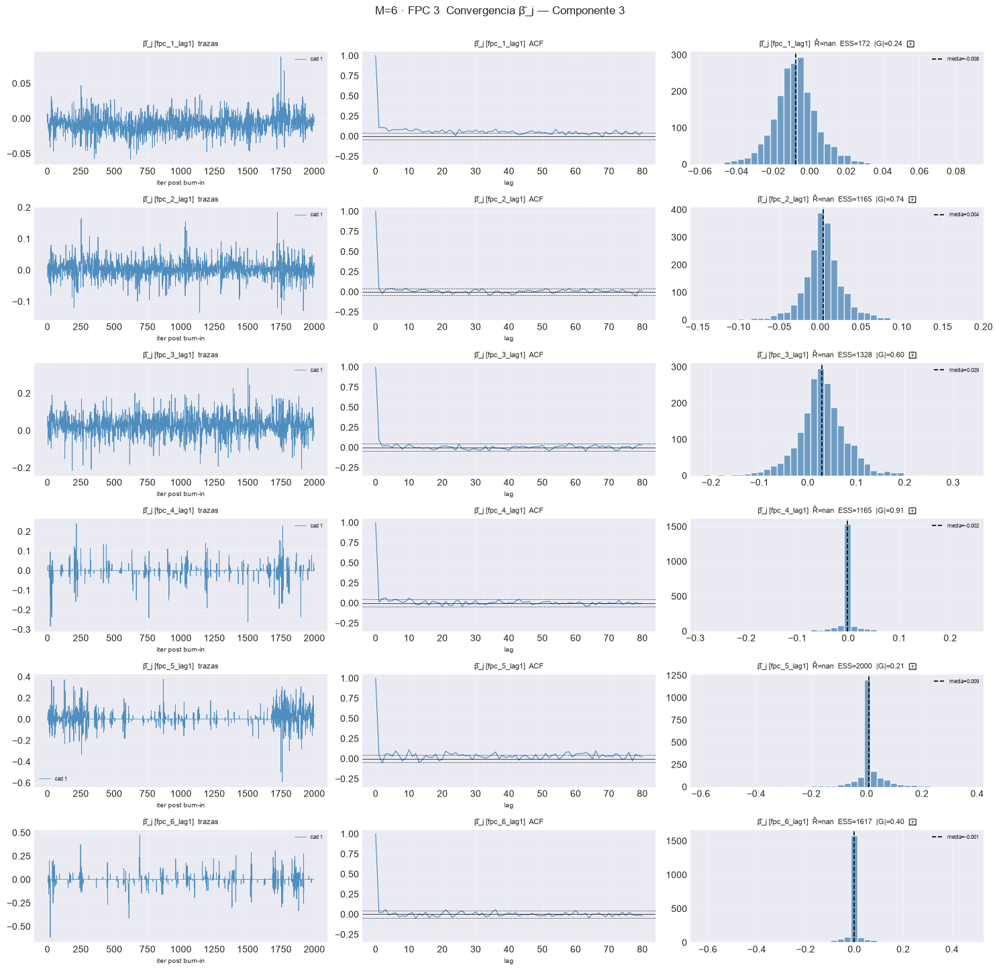

[plot_convergence_pj[FPC 3]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=202  |G|=1.45  ✓


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=135  |G|=0.93  ✓


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=99  |G|=1.14  ✗


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=178  |G|=0.05  ✓


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=13  |G|=1.76  ✗


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=132  |G|=0.24  ✓


[plot_convergence_pj[FPC 3]] listo: 6 pasos en 2.0s  2/6 sin converger


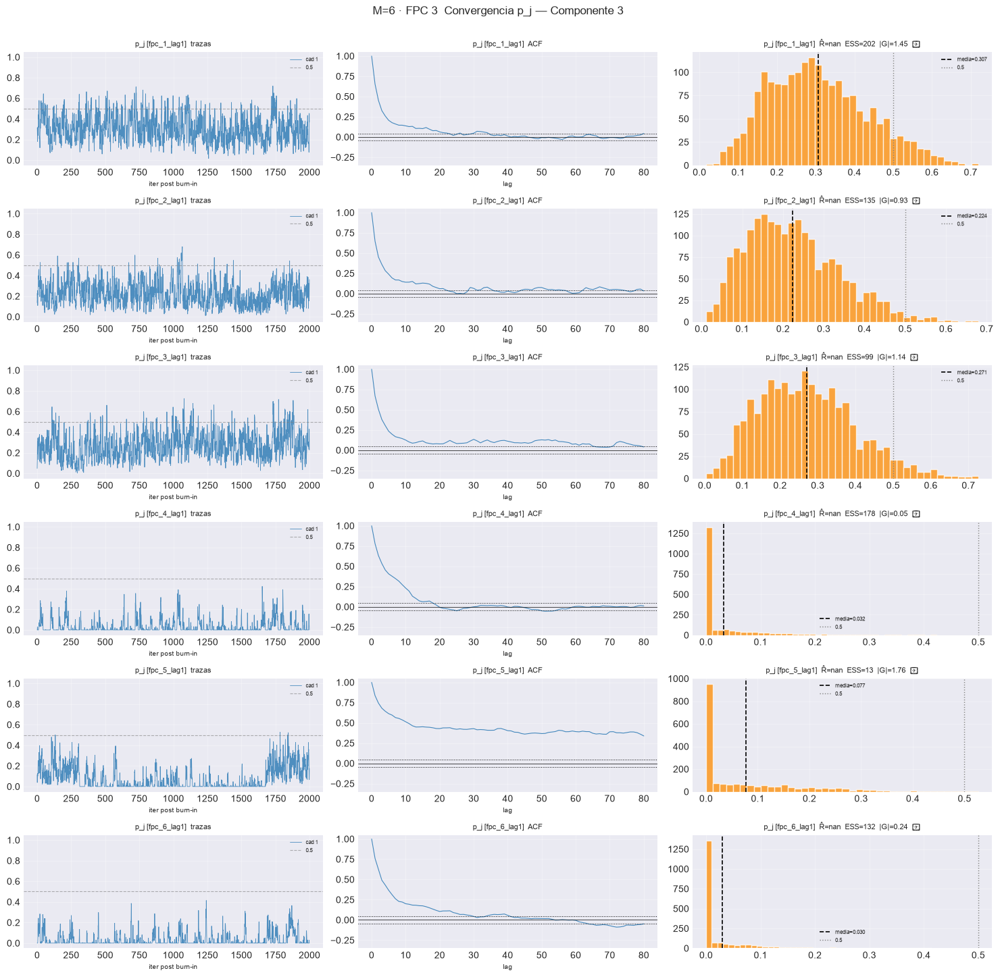

[plot_convergence_bj[FPC 4]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=1437  |G|=0.84  ✓


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=538  |G|=0.21  ✓


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=132  |G|=4.23  ✗


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=34  |G|=8.44  ✗


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=1674  |G|=0.06  ✓


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=0.29  ✓


[plot_convergence_bj[FPC 4]] listo: 6 pasos en 2.2s  2/6 sin converger


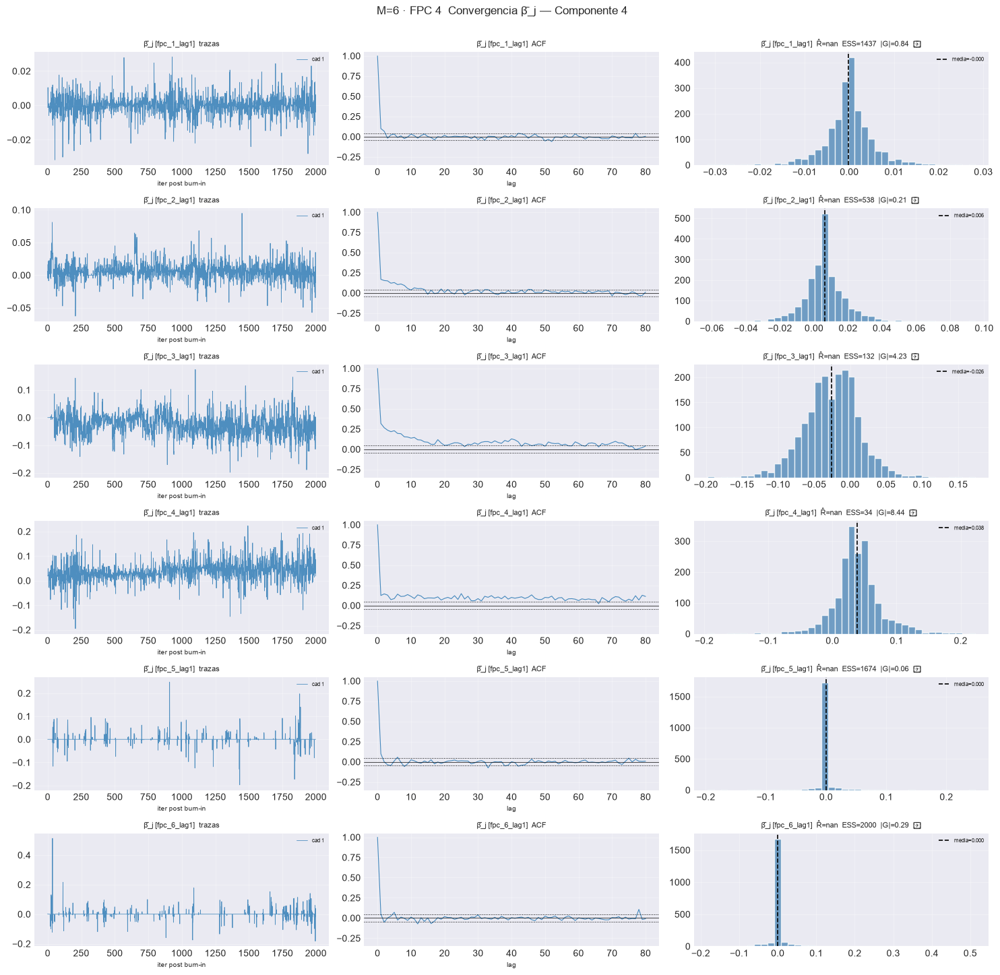

[plot_convergence_pj[FPC 4]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=160  |G|=1.12  ✓


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=210  |G|=0.55  ✓


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=25  |G|=1.53  ✗


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=14  |G|=2.48  ✗


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=174  |G|=0.18  ✓


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=206  |G|=0.23  ✓


[plot_convergence_pj[FPC 4]] listo: 6 pasos en 2.0s  2/6 sin converger


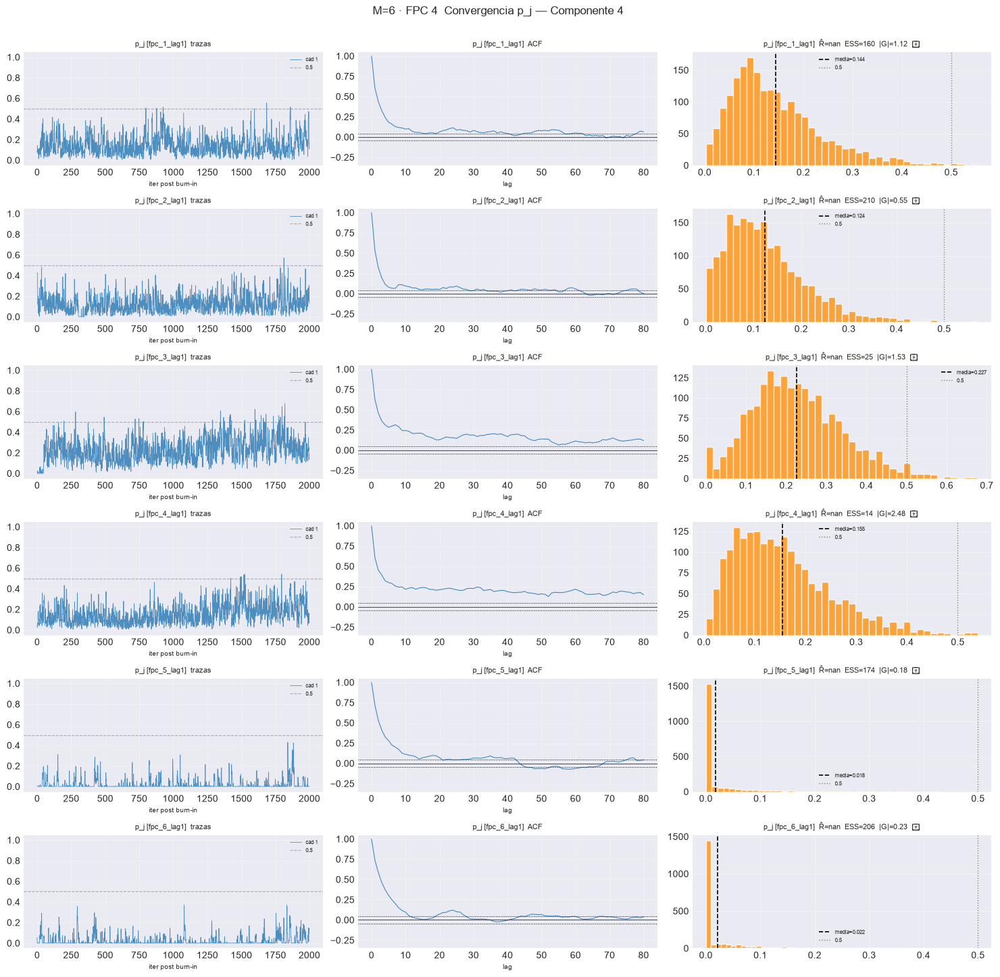

[plot_convergence_bj[FPC 5]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=456  |G|=1.09  ✓


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=157  |G|=1.43  ✓


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=596  |G|=1.91  ✓


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=217  |G|=0.12  ✓


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=509  |G|=0.57  ✓


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=1335  |G|=0.60  ✓


[plot_convergence_bj[FPC 5]] listo: 6 pasos en 1.9s  0/6 sin converger


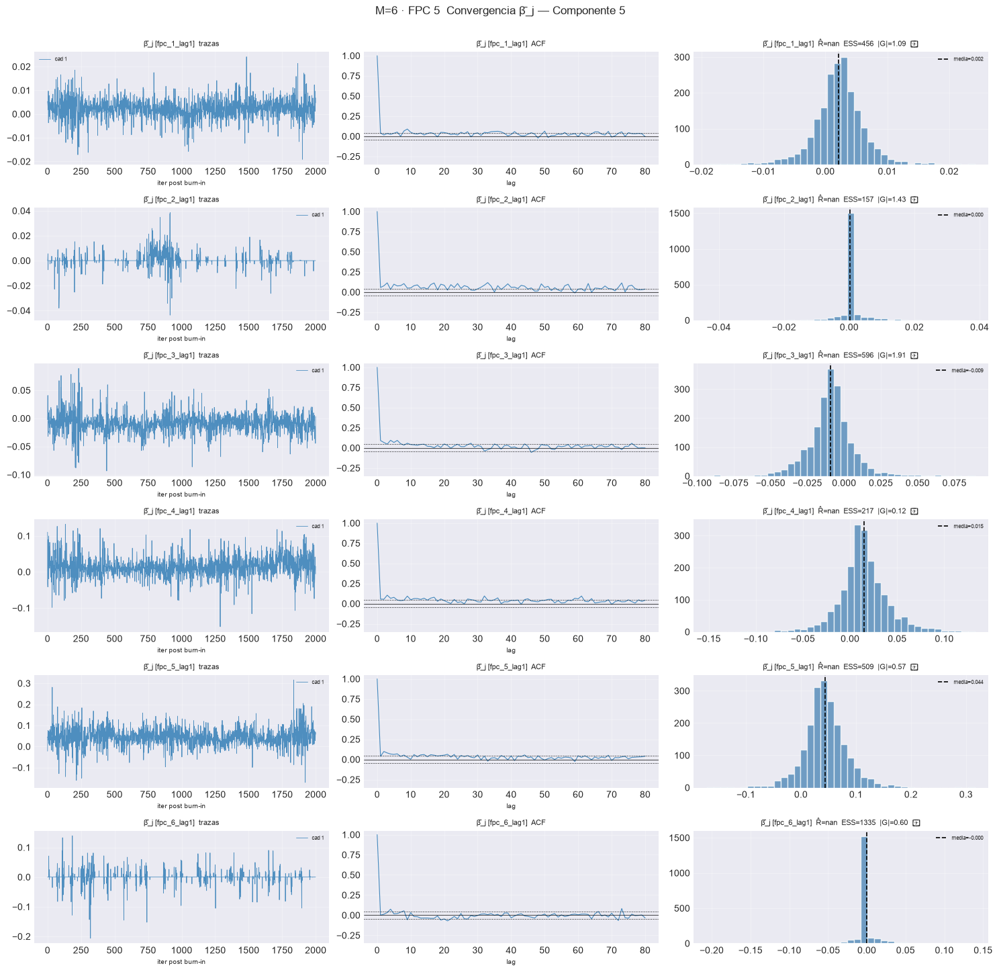

[plot_convergence_pj[FPC 5]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=59  |G|=0.83  ✗


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=25  |G|=0.97  ✗


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=315  |G|=0.40  ✓


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=16  |G|=0.02  ✗


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=54  |G|=1.57  ✗


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=240  |G|=0.55  ✓


[plot_convergence_pj[FPC 5]] listo: 6 pasos en 2.0s  4/6 sin converger


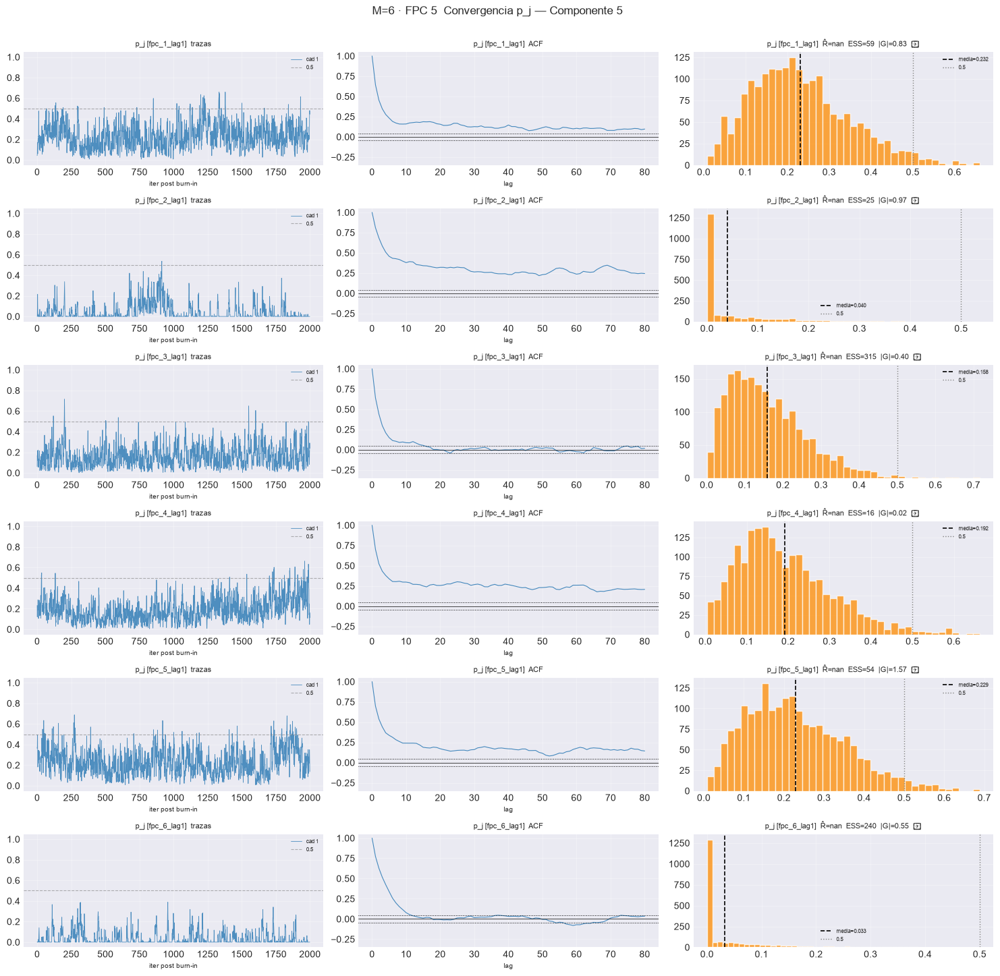

[plot_convergence_bj[FPC 6]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=669  |G|=1.06  ✓


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=0.81  ✓


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=64  |G|=2.91  ✗


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=871  |G|=0.35  ✓


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=325  |G|=0.33  ✓


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=318  |G|=1.54  ✓


[plot_convergence_bj[FPC 6]] listo: 6 pasos en 2.1s  1/6 sin converger


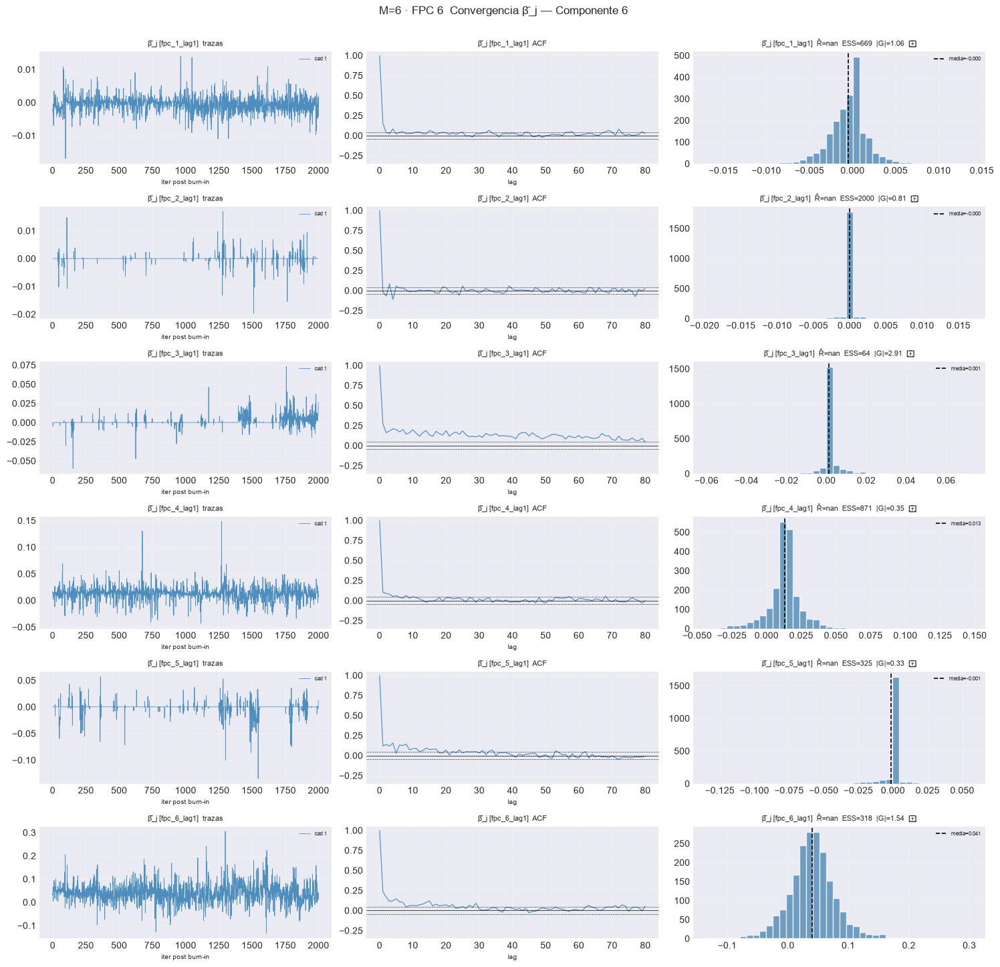

[plot_convergence_pj[FPC 6]] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=nan  ess_min=8  |G|=9.86  ✗


  2/6 (33.3%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=nan  ess_min=351  |G|=1.05  ✓


  3/6 (50.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=12  |G|=1.83  ✗


  4/6 (66.7%) t=0.1s eta=0.0s  fpc_4_lag1  rhat=nan  ess_min=129  |G|=3.61  ✗


  5/6 (83.3%) t=0.1s eta=0.0s  fpc_5_lag1  rhat=nan  ess_min=95  |G|=1.47  ✗


  6/6 (100.0%) t=0.1s eta=0.0s  fpc_6_lag1  rhat=nan  ess_min=8  |G|=5.29  ✗


[plot_convergence_pj[FPC 6]] listo: 6 pasos en 2.0s  5/6 sin converger


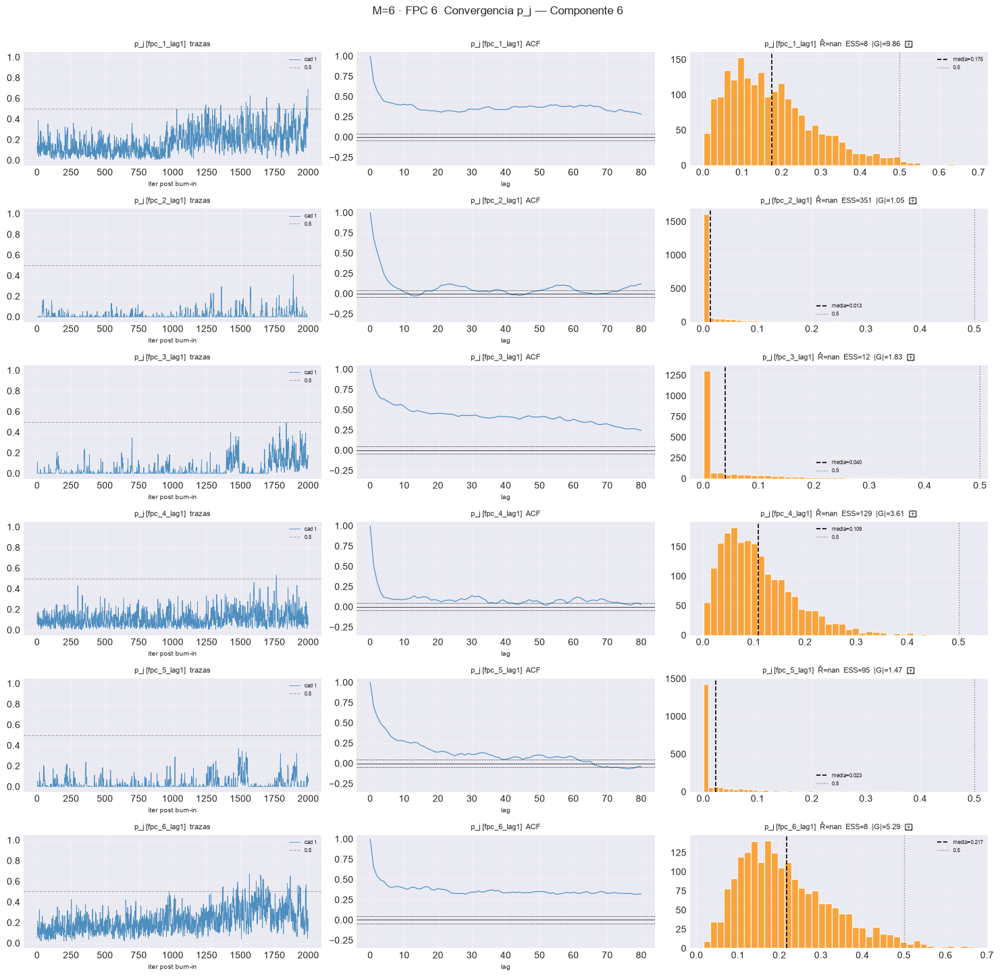

In [9]:
# Traza | ACF | posterior con las métricas anotadas; beta_j va promediado sobre
# átomos (invariante a la permutación de etiquetas). verbose=True saca
# Rhat/ESS/Geweke por covariable a la consola.
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc  = e["component_idx"][k] + 1
        feat = e["models_chains"][k][0].feature_names_
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_convergence_bj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"44_conv_bj_k{fpc}.png"), verbose=True)
        plt.show()
        plot_convergence_pj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"45_conv_pj_k{fpc}.png"), verbose=True)
        plt.show()

## 6. Probabilidades posteriores de inclusión

Tercer eje del diseño (`docs §03_06`): qué variables selecciona el modelo.
Con datos reales no hay estructura verdadera contra la cual contrastar: se reporta
el PIP y su dispersión entre cadenas.

In [10]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} - P(gamma_j = 1 | datos), inclusión global, media entre cadenas +- sd"))

[matriz_pip] inicio (1 pasos)


  1/1 (100.0%) t=0.0s eta=0.0s  FPC 1: 1 cadenas, 1 variables, PIP en [1.000, 1.000]


[matriz_pip] listo: 1 pasos en 0.0s  tabla 1x2


[M=1] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd
variable,,
fpc_1_lag1,1.000,0.000


[matriz_pip] inicio (2 pasos)


... (35 outputs left out)

  6/6 (100.0%) t=0.0s eta=0.0s  FPC 6: 1 cadenas, 6 variables, PIP en [0.090, 1.000]


[matriz_pip] listo: 6 pasos en 0.0s  tabla 6x12


[M=6] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd
variable,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000
fpc_2_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.976,0.000,0.220,0.000,0.090,0.000
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.978,0.000,1.000,0.000,0.274,0.000
fpc_4_lag1,1.000,0.000,0.305,0.000,0.179,0.000,1.000,0.000,1.000,0.000,1.000,0.000
fpc_5_lag1,0.713,0.000,1.000,0.000,0.422,0.000,0.131,0.000,1.000,0.000,0.180,0.000
fpc_6_lag1,0.812,0.000,0.155,0.000,0.160,0.000,0.150,0.000,0.191,0.000,1.000,0.000


## 7. Verificación muestreador ↔ predictor

`inEout` es $E[y\mid x]$ dentro de muestra tal como la calcula MATLAB en cada
iteración. Debe coincidir con lo que el predictor de Python reconstruye de las
mismas trazas: es la única prueba directa de que ambos lados interpretan las
trazas igual. Se corre **en cada $M$** (el contrato depende de $p$).

In [11]:
ok_global = all([verificar_muestreador_predictor(EST[M], CORR_MIN_CONTRATO) for M in M_OK])
print(f"\n{'OK contrato verificado en todo el barrido' if ok_global else 'X el contrato falla'}")

-- M=1 --


  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000
-- M=2 --


  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 2 cadena1: corr=1.000000  |dif|max=0.0000
-- M=3 --


  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 2 cadena1: corr=1.000000  |dif|max=0.0000


... (12 outputs left out)

  FPC 3 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 4 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 5 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 6 cadena1: corr=1.000000  |dif|max=0.0000

OK contrato verificado en todo el barrido


### 7.1 Paso de $\Gamma$: grilla por predictor y normalización

- cada $\Gamma_{hj}$ muestreado cae **en la grilla de su predictor** `Gstar[:, j]`;
- en cada sorteo, `pm1` es finito y suma 1 (`gamdiagout`).

In [12]:
gamma_df = diagnostico_paso_gamma(EST, M_OK)
display(gamma_df[gamma_df.M == max(M_OK)].style
        .format({"dist_max": "{:.1e}", "err_suma_max": "{:.1e}",
                 "rango_log_mediana": "{:.1f}", "rango_log_max": "{:.1f}"})
        .set_caption(f"M={max(M_OK)} - paso de Gamma, post-burn"))

OK Gamma siempre en su grilla y pm1 finita y normalizada   ·   rango_log mediano 6472


,M,FPC,cadena,fuera_de_grilla,dist_max,sorteos,no_finitos,err_suma_max,rango_log_mediana,rango_log_max
15,6,1,1,False,1.2e-07,111329,0,6.7e-16,6471.9,15241.3
16,6,2,1,False,1.2e-07,84670,0,4.4e-16,5212.3,13474.5
17,6,3,1,False,1.2e-07,57150,0,4.4e-16,2272.7,7062.4
18,6,4,1,False,1.2e-07,39225,0,4.4e-16,2300.8,7915.3
19,6,5,1,False,1.2e-07,52146,0,4.4e-16,1509.6,4025.0
20,6,6,1,False,1.2e-07,32464,0,5.6e-16,10214.8,45659.8


## 8. Comparación entre los puntos del barrido

Las cifras son comparables entre $M$: $\hat R$ máx, ESS mín y Geweke máx son el
**peor caso** del punto (no un promedio sobre un número de variables que cambia
con $M$); la ocupación cuenta átomos; el PIP es una proporción en $[0,1]$.

,experiment_id,p_covariables,n_variables_diag,rhat_max,ess_min,geweke_max,n_no_converge,converge,ocupacion_media,ocupacion_max,N_trunc,toca_truncamiento,pip_sd_max,contrato_ok
M,,,,,,,,,,,,,,
1,real_trafico_mi_v01_m01,1,2,-,302,1.7546,0,True,6.17,20,30,False,0.0000,True
2,real_trafico_mi_v01_m02,2,8,-,32,3.9958,3,False,14.48,30,30,True,0.0000,True
3,real_trafico_mi_v01_m03,3,18,-,52,4.6115,9,False,17.48,30,30,True,0.0000,True
4,real_trafico_mi_v01_m04,4,32,-,15,11.6950,13,False,12.26,30,30,True,0.0000,True
5,real_trafico_mi_v01_m05,5,50,-,10,14.7992,19,False,13.85,30,30,True,0.0000,True
6,real_trafico_mi_v01_m06,6,72,-,8,11.3281,28,False,15.82,30,30,True,0.0000,True


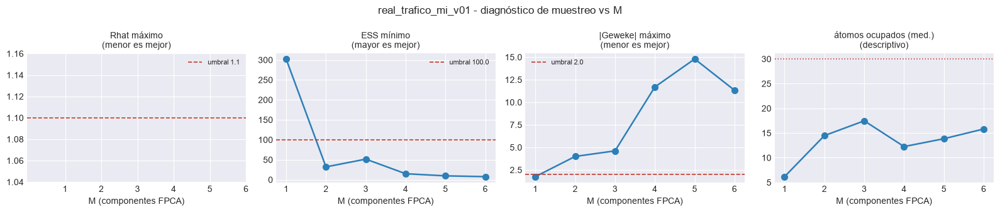

In [13]:
barrido_df = tabla_barrido(EST, M_OK, PATH_BARRIDO)
_fmt = {c: "{:.4f}" for c in ("rhat_max", "geweke_max", "pip_sd_max", "pip_media_activas")
        if c in barrido_df.columns} | {"ess_min": "{:.0f}", "ocupacion_media": "{:.2f}"}
display(barrido_df.style.format(_fmt, na_rep="-")
        .background_gradient(subset=["rhat_max"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption("Diagnóstico de muestreo a lo largo del barrido en M"))

plot_diagnostico_vs_M(barrido_df, EST[M_OK[0]]["res_conv"]["umbrales"], EXPERIMENT_BASE,
                      PATH_BARRIDO / "81_diagnostico_vs_M.png")
plt.show()

FPC,1,2,3,4,5,6
M,,,,,,
1,6.17,-,-,-,-,-
2,7.60,21.36,-,-,-,-
3,9.20,28.30,14.93,-,-,-
4,6.81,13.34,12.78,16.11,-,-
5,12.59,8.60,15.85,15.04,17.19,-
6,7.52,10.54,15.74,22.02,15.16,23.97


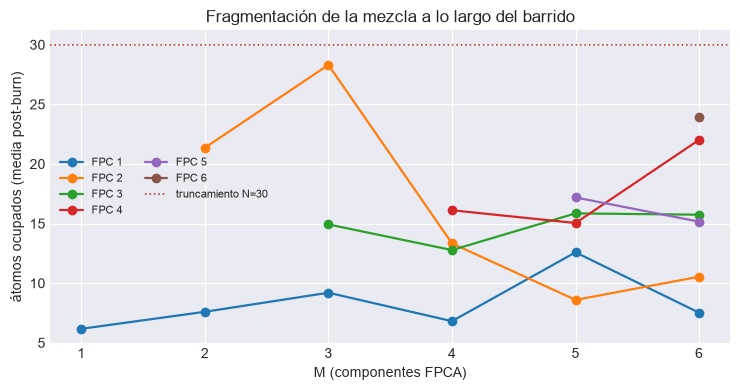

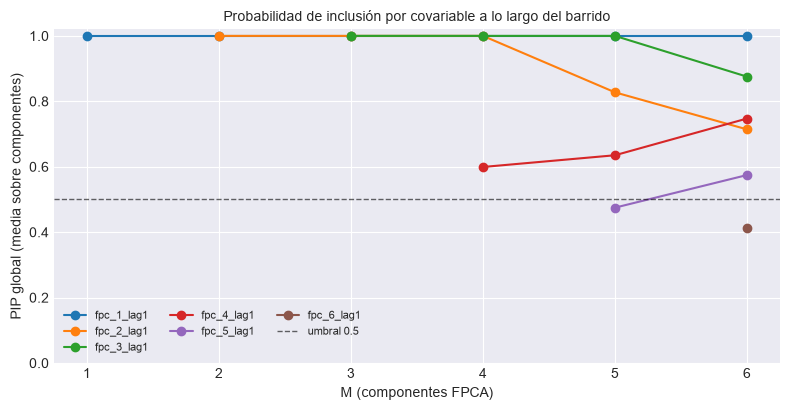

In [14]:
# Ocupación por M y componente: dice si al subir M el modelo parte la mezcla en más átomos.
ocup_todo, piv = ocupacion_barrido(EST, M_OK, PATH_BARRIDO)
display(piv.style.format("{:.2f}", na_rep="-").background_gradient(cmap="RdYlGn_r", axis=None)
        .set_caption("Átomos ocupados (media post-burn) por M y componente FPCA"))
plot_ocupacion_vs_M(piv, int(ocup_todo["N_trunc"].iloc[0]), PATH_BARRIDO / "82_ocupacion_por_M.png")
plt.show()

# PIP por covariable a lo largo del barrido (formato largo).
pip_largo = pip_barrido(EST, M_OK, PATH_BARRIDO)
plot_pip_vs_M(pip_largo, M_OK, PATH_BARRIDO / "83_pip_por_M.png")
plt.show()

In [15]:
veredicto_barrido(barrido_df, EXPERIMENT_BASE, M_FPCA_LIST, M_OK, PATH_BARRIDO)
print("Continuar con 30_04_evaluacion, declarando el mismo M_FPCA_LIST.")

  BARRIDO real_trafico_mi_v01   ·   M evaluados: [1, 2, 3, 4, 5, 6]
  M=1  p=1  Rhatmax=nan  ESSmin=302  ocup=6.2/30  OK
  M=2  p=2  Rhatmax=nan  ESSmin=32  ocup=14.5/30  X NO CONVERGE
  M=3  p=3  Rhatmax=nan  ESSmin=52  ocup=17.5/30  X NO CONVERGE
  M=4  p=4  Rhatmax=nan  ESSmin=15  ocup=12.3/30  X NO CONVERGE
  M=5  p=5  Rhatmax=nan  ESSmin=10  ocup=13.9/30  X NO CONVERGE
  M=6  p=6  Rhatmax=nan  ESSmin=8  ocup=15.8/30  X NO CONVERGE
------------------------------------------------------------------
X NO convergen: M = [2, 3, 4, 5, 6]. Excluirlos de la comparacion de _04/_05,
  o subir nsim/burn antes de leer su error como efecto de M.

corr(M, Rhatmax) = +nan   ·   corr(M, ESSmin) = -0.732
Tablas y figuras cruzadas en C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_barrido_M  (archivos 80-83)
Continuar con 30_04_evaluacion, declarando el mismo M_FPCA_LIST.
